# Génération de texte avec un RNN — corpus Victor Hugo

Ce troisième exercice traite des **données textuelles**. Nous allons apprendre à un réseau récurrent à prédire le mot suivant à partir des trois mots précédents, puis utiliser ces prédictions pour générer du texte mot après mot.

Le travail suivra le même cycle que les exercices précédents :

1. comprendre et nettoyer le corpus ;
2. séparer entraînement, validation et test sans fuite ;
3. construire le vocabulaire sur l’entraînement uniquement ;
4. fabriquer les séquences entrée-cible ;
5. comprendre puis construire un SimpleRNN ;
6. entraîner avec validation et arrêt anticipé ;
7. évaluer et générer du texte ;
8. comparer SimpleRNN et LSTM.

Chaque notion théorique et chaque formule seront présentées avant le code correspondant.

## 1. Définir précisément le problème

### 1.1 Prédire le mot suivant

Après nettoyage et tokenisation, un poème devient une suite d’identifiants de mots :

$$
(w_1,w_2,\ldots,w_T).
$$

Pour une position $t$, l’entrée contient au maximum les trois mots précédents :

$$
x_t=(w_{t-3},w_{t-2},w_{t-1}),
\qquad y_t=w_t.
$$

Au début d’un texte, lorsqu’il manque un ou plusieurs mots, nous ajouterons à gauche l’identifiant de bourrage 0 afin de conserver une entrée de longueur 3.

Le réseau devra produire une distribution de probabilités sur le vocabulaire :

$$
p_{\theta}(w_t=k\mid w_{t-3},w_{t-2},w_{t-1}),
\qquad k\in\{0,\ldots,V-1\},
$$

où $V$ est la taille du vocabulaire et $\theta$ représente tous les paramètres appris. Pour $N$ exemples, l’apprentissage cherchera plus tard à minimiser l’entropie croisée :

$$
L(\theta)=-\frac{1}{N}\sum_{n=1}^{N}
\log p_{\theta}(y_n\mid x_n).
$$

La génération répétera ensuite le même mécanisme : prédire un mot, l’ajouter au texte, déplacer la fenêtre de trois mots, puis prédire le suivant.

### 1.2 Protocole anti-fuite pour des données séquentielles

Deux fenêtres voisines se ressemblent presque entièrement. Par exemple :

$$
(w_1,w_2,w_3)\rightarrow w_4
$$

et

$$
(w_2,w_3,w_4)\rightarrow w_5
$$

partagent plusieurs mots. Si nous fabriquions toutes les fenêtres puis les répartissions au hasard, des fragments presque identiques pourraient se retrouver dans l’entraînement et le test. La performance semblerait alors meilleure qu’elle ne l’est réellement.

Notre protocole sera donc le suivant :

1. reconstruire les poèmes et préserver leurs frontières ;
2. séparer les **poèmes** en entraînement, validation et test ;
3. adapter le vocabulaire uniquement sur les poèmes d’entraînement ;
4. transformer ensuite chaque partie en fenêtres, sans jamais traverser la frontière entre deux poèmes ;
5. utiliser la validation pour les choix d’apprentissage ;
6. consulter le test une seule fois pour l’évaluation finale.

Cette étape est essentielle : le Tokenizer apprend lui aussi des informations sur les données, notamment quels mots existent et lesquels sont fréquents. Il fait donc partie du prétraitement à ajuster uniquement sur l’entraînement.

**Dans cette première étape, nous ne tokenisons encore rien.** Nous vérifions d’abord la qualité et la structure des fichiers.

## 2. Préparer l’environnement reproductible

Nous utilisons :

- *pathlib* pour manipuler les chemins de fichiers ;
- *re* pour quelques statistiques textuelles simples ;
- NumPy pour les futurs tableaux numériques ;
- TensorFlow/Keras pour le futur réseau récurrent.

Une graine fixe rend les séparations et initialisations reproductibles. Le déterminisme signifie que deux exécutions dans le même environnement doivent produire les mêmes résultats. Il ne garantit pas que deux versions différentes de TensorFlow donnent exactement les mêmes nombres.

In [1]:
from pathlib import Path
import re

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

SEED = 42

tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

print("TensorFlow :", tf.__version__)
print("NumPy      :", np.__version__)
print("Graine     :", SEED)
print("Environnement prêt.")

TensorFlow : 2.21.0
NumPy      : 2.4.6
Graine     : 42
Environnement prêt.


## 3. Charger les fichiers sans transformer le texte

Le dossier contient deux fichiers :

- *victor_hugo-texts.txt* : le corpus concaténé ;
- *victor_hugo-titles.txt* : la liste des titres, utile pour retrouver les frontières entre les poèmes.

Un fichier texte contient d’abord des **octets**. Un encodage indique comment convertir ces octets en caractères Unicode. Nous demandons explicitement UTF-8 et une lecture stricte : si les octets n’étaient pas valides, Python lèverait une erreur au lieu de remplacer silencieusement des caractères.

À ce stade, nous conservons le contenu exactement tel qu’il est. Nous ne mettons pas le texte en minuscules, nous ne supprimons pas la ponctuation et nous ne construisons aucun vocabulaire.

In [2]:
DOSSIER_PROJET = Path.cwd()
CHEMIN_CORPUS = DOSSIER_PROJET / "victor_hugo-texts.txt"
CHEMIN_TITRES = DOSSIER_PROJET / "victor_hugo-titles.txt"

assert CHEMIN_CORPUS.is_file(), f"Fichier absent : {CHEMIN_CORPUS}"
assert CHEMIN_TITRES.is_file(), f"Fichier absent : {CHEMIN_TITRES}"

octets_corpus = CHEMIN_CORPUS.read_bytes()
octets_titres = CHEMIN_TITRES.read_bytes()

# errors="strict" est la valeur par défaut : aucune erreur n’est masquée.
texte_brut = octets_corpus.decode("utf-8", errors="strict")
texte_titres_brut = octets_titres.decode("utf-8", errors="strict")
titres_bruts = [
    ligne.strip()
    for ligne in texte_titres_brut.splitlines()
    if ligne.strip()
]

assert len(texte_brut) > 0
assert len(titres_bruts) > 0
assert "\ufffd" not in texte_brut
assert "\ufffd" not in texte_titres_brut

print("Dossier du projet :", DOSSIER_PROJET)
print("Corpus             :", CHEMIN_CORPUS.name, f"({len(octets_corpus):,} octets)")
print("Titres             :", CHEMIN_TITRES.name, f"({len(octets_titres):,} octets)")
print("Décodage UTF-8 strict réussi.")
print("Nombre de titres non vides :", len(titres_bruts))

Dossier du projet : C:\Users\driou\OneDrive\Bureau\introduction_au_deeplearning
Corpus             : victor_hugo-texts.txt (107,013 octets)
Titres             : victor_hugo-titles.txt (1,180 octets)
Décodage UTF-8 strict réussi.
Nombre de titres non vides : 48


## 4. Distinguer UTF-8 valide et texte correctement affiché

Un décodage UTF-8 réussi ne suffit pas à prouver que le texte est correct. Le contenu peut avoir été mal décodé dans le passé, puis réenregistré proprement en UTF-8. Cette corruption s’appelle le **mojibake**.

Par exemple, le mot attendu « siècle » peut devenir « siÃ¨cle » après cette chaîne d’opérations :

$$
\text{caractères corrects}
\longrightarrow
\text{octets UTF-8}
\longrightarrow
\text{mauvais décodage}
\longrightarrow
\text{caractères altérés}.
$$

Les suites contenant notamment « Ã », « Â » ou « â€ » sont des indices fréquents de ce problème en français. Nous allons les compter et afficher un extrait avant de décider d’une réparation. Modifier immédiatement le texte sans diagnostic pourrait détruire des caractères déjà corrects.

In [3]:
motifs_mojibake = {
    "Ã": texte_brut.count("Ã"),
    "Â": texte_brut.count("Â"),
    "â€": texte_brut.count("â€"),
}
nombre_indices_mojibake = sum(motifs_mojibake.values())

lignes_suspectes = [
    ligne for ligne in texte_brut.splitlines()
    if any(motif in ligne for motif in motifs_mojibake)
]

print("Indices de mojibake dans le corpus :")
for motif, nombre in motifs_mojibake.items():
    print(f"  {motif!r:<5} : {nombre:>5}")

print("\nPremier extrait suspect :")
print(lignes_suspectes[0] if lignes_suspectes else "Aucun extrait suspect")

assert nombre_indices_mojibake > 0
assert len(lignes_suspectes) > 0

print(
    "\nDiagnostic : le fichier est un UTF-8 valide, "
    "mais son contenu textuel doit être réparé avant la tokenisation."
)

Indices de mojibake dans le corpus :
  'Ã'   :  2124
  'Â'   :    90
  'â€'  :    94

Premier extrait suspect :
Mes vers fuiraient, doux et frÃªles, Vers votre jardin si beau,

Diagnostic : le fichier est un UTF-8 valide, mais son contenu textuel doit être réparé avant la tokenisation.


## 5. Observer la structure générale du corpus

Avant de nettoyer, nous calculons seulement des statistiques descriptives : nombre de caractères, lignes, titres et unités séparées par des espaces.

Le comptage d’unités ci-dessous n’est **pas** encore la tokenisation du modèle. Il sert uniquement à estimer la taille du corpus. La vraie tokenisation déterminera plus tard précisément :

- la gestion des majuscules ;
- la ponctuation conservée ou supprimée ;
- le mot réservé aux éléments hors vocabulaire ;
- la taille maximale du vocabulaire.

Nous vérifions aussi combien de titres apparaissent littéralement dans le corpus. Cela nous indique si la liste des titres peut servir de repère pour reconstruire les poèmes.

In [4]:
lignes_corpus = texte_brut.splitlines()
lignes_non_vides = [ligne.strip() for ligne in lignes_corpus if ligne.strip()]
unites_approx = re.findall(r"\S+", texte_brut)
titres_retrouves = [titre for titre in titres_bruts if titre in texte_brut]

print("Caractères Unicode        :", f"{len(texte_brut):,}")
print("Lignes totales            :", f"{len(lignes_corpus):,}")
print("Lignes non vides          :", f"{len(lignes_non_vides):,}")
print("Unités séparées par espace:", f"{len(unites_approx):,}")
print("Titres fournis            :", len(titres_bruts))
print("Titres retrouvés tels quels:", len(titres_retrouves))

print("\nDix premiers titres bruts :")
for indice, titre in enumerate(titres_bruts[:10], start=1):
    print(f"{indice:>2}. {titre}")

print("\nDébut brut du corpus :")
print("\n".join(lignes_corpus[:12]))

assert len(titres_retrouves) > 0
assert len(unites_approx) > len(titres_bruts)

Caractères Unicode        : 102,257
Lignes totales            : 2,349
Lignes non vides          : 1,400
Unités séparées par espace: 17,309
Titres fournis            : 48
Titres retrouvés tels quels: 13

Dix premiers titres bruts :
 1. Mes vers fuiraient
 2. Ce siÃ¨cle avait deux ans
 3. Le mariage de Roland
 4. Lâ€™enfant
 5. La ronde du sabbat
 6. Un jour je vis
 7. Melancholia
 8. Lâ€™hiver
 9. Jâ€™eus toujours de lâ€™amour
10. Chanson

Début brut du corpus :
Mes vers fuiraient

Mes vers fuiraient, doux et frÃªles, Vers votre jardin si beau,
Si mes vers avaient des ailes,
Des ailes comme l'oiseau.


Ils voleraient, Ã©tincelles, Vers votre foyer qui rit,
Si mes vers avaient des ailes,
Des ailes comme l'esprit.

PrÃ¨s de vous, purs et fidÃ¨les, Ils accourraient, nuit et jour, Si mes vers avaient des ailes, Des ailes comme l'amour!


## Bilan de l’étape 1

Le problème est maintenant défini : prédire chaque mot à partir d’une fenêtre maximale de trois mots, puis réutiliser le modèle de façon autorégressive pour générer du texte.

Le corpus brut contient :

- **102 257 caractères Unicode** ;
- **2 349 lignes**, dont 1 400 non vides ;
- environ **17 309 unités** séparées par des espaces ;
- **48 titres** fournis séparément.

Le diagnostic d’encodage révèle **2 124 occurrences de « Ã »**, 90 de « Â » et 94 de « â€ ». Le fichier est bien décodable en UTF-8, mais une corruption antérieure a transformé des mots comme « frêles » en « frÃªles ». Tokeniser maintenant créerait artificiellement des mots incorrects et polluerait le vocabulaire.

Seulement 13 titres sur 48 sont retrouvés littéralement dans le corpus brut. Nous ne devons donc pas découper naïvement le texte à partir des titres avant d’avoir réparé et normalisé les deux fichiers de la même manière.

Enfin, le protocole anti-fuite est fixé : la future séparation se fera **par poème avant la création des fenêtres**, et le vocabulaire sera appris uniquement sur les poèmes d’entraînement.

**Prochaine étape :** réparer le mojibake de manière contrôlée, vérifier la correction sur plusieurs exemples, puis reconstruire les 48 poèmes sans encore créer le vocabulaire.

## 6. Réparer le mojibake sans modifier les fichiers sources

### 6.1 Comprendre l’opération inverse

Le texte est bien stocké aujourd’hui dans un fichier UTF-8, mais son contenu avait déjà été mal interprété auparavant. Notons $E_e$ l’encodage en octets avec l’encodage $e$, et $D_e$ le décodage de ces octets. Pour un texte correct $t$, le mojibake observé $m$ provient généralement de :

$$
m = D_{\mathrm{CP1252}}\left(E_{\mathrm{UTF8}}(t)\right).
$$

Si aucune information n’a été perdue, l’opération inverse est :

$$
t = D_{\mathrm{UTF8}}\left(E_{\mathrm{CP1252}}(m)\right).
$$

Dans le corpus, cette inversion révèle exactement **255 séquences invalides**. Elles ont toutes la même forme : l’octet `A0` du caractère « à », normalement encodé `C3 A0` en UTF-8, a été remplacé par un espace `20`. Nous autorisons donc une seule réparation binaire connue :

$$
\mathtt{C3\ 20} \longrightarrow \mathtt{C3\ A0}.
$$

Cette correction consomme l’espace qui remplace l’octet perdu ; elle n’ajoute donc pas d’espace artificiel. Toute autre erreur provoquera volontairement une exception. Les variables brutes et les deux fichiers restent intacts.


In [5]:
import hashlib
import unicodedata


def trouver_positions_invalides_utf8(octets):
    """Retourne les positions qui empêchent un décodage UTF-8 strict."""
    positions = []
    position = 0

    while position < len(octets):
        try:
            octets[position:].decode("utf-8", errors="strict")
            break
        except UnicodeDecodeError as erreur:
            position_erreur = position + erreur.start
            positions.append(position_erreur)
            position = position_erreur + 1

    return positions


def reparer_mojibake_cp1252(texte, autoriser_a_endommage=False):
    """Inverse le mauvais décodage CP1252, sans ignorer aucune erreur."""
    octets_reconstitues = texte.encode("cp1252", errors="strict")
    positions_invalides = trouver_positions_invalides_utf8(octets_reconstitues)

    if positions_invalides:
        if not autoriser_a_endommage:
            raise ValueError("Séquence UTF-8 endommagée non autorisée.")

        motifs_invalides = {
            octets_reconstitues[position:position + 2]
            for position in positions_invalides
        }
        if motifs_invalides != {b"\xc3 "}:
            raise ValueError(f"Motif inattendu : {motifs_invalides}")

        # C3 20 devient C3 A0 : le caractère « à » est restauré.
        octets_reconstitues = octets_reconstitues.replace(
            b"\xc3 ",
            b"\xc3\xa0",
        )

    texte_repare = octets_reconstitues.decode("utf-8", errors="strict")
    texte_repare = unicodedata.normalize("NFC", texte_repare)
    return texte_repare, positions_invalides


empreinte_corpus_source = hashlib.sha256(octets_corpus).hexdigest()
empreinte_titres_source = hashlib.sha256(octets_titres).hexdigest()

texte_corrige, positions_a_reparees = reparer_mojibake_cp1252(
    texte_brut,
    autoriser_a_endommage=True,
)
texte_titres_corrige, erreurs_titres = reparer_mojibake_cp1252(
    texte_titres_brut
)
titres_corriges = [
    ligne.strip()
    for ligne in texte_titres_corrige.splitlines()
    if ligne.strip()
]

print("Séquences « à » réparées dans le corpus :", len(positions_a_reparees))
print("Erreurs binaires dans le fichier des titres :", len(erreurs_titres))
print("Caractères après réparation :", f"{len(texte_corrige):,}")


Séquences « à » réparées dans le corpus : 255
Erreurs binaires dans le fichier des titres : 0
Caractères après réparation : 99,835


### 6.2 Valider la réparation avant toute analyse

Une sortie lisible à l’œil ne suffit pas. Nous exigeons simultanément :

- le même nombre de lignes avant et après ;
- exactement 48 titres, tous différents ;
- aucun caractère de remplacement `�` et aucun motif de mojibake connu ;
- plusieurs mots témoins correctement restaurés ;
- les mêmes empreintes SHA-256 pour les fichiers sur disque, preuve qu’ils n’ont pas été réécrits.

En notation compacte, si $L$ compte les lignes et $T$ les titres, nous vérifions :

$$
L_{\mathrm{brut}} = L_{\mathrm{corrigé}} = 2349,
\qquad T_{\mathrm{corrigé}} = 48.
$$

Attention : nous ne demandons pas la disparition de toute lettre « Â ». Le corpus contient réellement la phrase « Âme où rien n’est impur ». Un bon contrôle distingue un caractère français légitime d’un motif corrompu comme `Â«`.


In [6]:
motifs_mojibake_residuels = ("Ã", "â€", "Å“", "Â«", "Â»", "\ufffd")

assert len(positions_a_reparees) == 255
assert len(erreurs_titres) == 0
assert len(texte_corrige.splitlines()) == len(texte_brut.splitlines()) == 2349
assert len(titres_corriges) == len(titres_bruts) == 48
assert len(set(titres_corriges)) == 48

for motif in motifs_mojibake_residuels:
    assert motif not in texte_corrige, f"Motif résiduel : {motif!r}"
    assert motif not in texte_titres_corrige, f"Motif résiduel dans les titres : {motif!r}"

# Le seul « Â » restant est une vraie majuscule accentuée.
assert texte_corrige.count("Â") == 1
assert "Âme où rien n'est impur" in texte_corrige
assert "Â" not in texte_titres_corrige

temoins = [
    ("frÃªles", "frêles"),
    ("Ã©tincelles", "étincelles"),
    ("siÃ¨cle", "siècle"),
    ("cÅ“ur", "cœur"),
    ("Lâ€™enfant", "L’enfant"),
]
for forme_abimee, forme_corrigee in temoins:
    assert forme_abimee in (texte_brut + texte_titres_brut)
    assert forme_corrigee in (texte_corrige + texte_titres_corrige)

# Relecture des fichiers : leur contenu binaire doit être inchangé.
assert hashlib.sha256(CHEMIN_CORPUS.read_bytes()).hexdigest() == empreinte_corpus_source
assert hashlib.sha256(CHEMIN_TITRES.read_bytes()).hexdigest() == empreinte_titres_source

print("Réparation validée sans modification des fichiers sources.")
print("Lignes du corpus :", len(texte_corrige.splitlines()))
print("Titres uniques   :", len(set(titres_corriges)))
print()
print("Avant :")
print("\n".join(texte_brut.splitlines()[:4]))
print()
print("Après :")
print("\n".join(texte_corrige.splitlines()[:4]))


Réparation validée sans modification des fichiers sources.
Lignes du corpus : 2349
Titres uniques   : 48

Avant :
Mes vers fuiraient

Mes vers fuiraient, doux et frÃªles, Vers votre jardin si beau,
Si mes vers avaient des ailes,

Après :
Mes vers fuiraient

Mes vers fuiraient, doux et frêles, Vers votre jardin si beau,
Si mes vers avaient des ailes,


## 7. Reconstruire les 48 poèmes

### 7.1 Pourquoi une découpe automatique serait trompeuse

Trois séparateurs apparemment naturels ont été vérifiés puis écartés :

- les 48 titres ne figurent pas tous littéralement dans le corpus ;
- les suites de lignes vides séparent aussi des strophes ;
- les 47 mentions « Victor Hugo » ne représentent pas 47 fins fiables.

Deux anomalies sont particulièrement importantes. Une attribution coupe **Les Djinns** en plein milieu, et une autre coupe **Oceano Nox**. Inversement, aucune attribution ne sépare **La chasse du Burgave** de **Jeanne était au pain sec**.

Pour ce fichier fixe, nous utilisons donc un **manifeste relu** de 48 intervalles. Une borne $(d_i,f_i)$ est semi-ouverte : elle conserve les indices de ligne $j$ tels que

$$
d_i \leq j < f_i.
$$

Ce choix évite les erreurs silencieuses. Les quatre lignes bibliographiques insérées à l’intérieur de deux poèmes sont nommées et retirées explicitement. Ce découpage ne crée encore ni jetons, ni identifiants numériques, ni vocabulaire.


In [7]:
lignes_corrigees = texte_corrige.splitlines()

# Indices Python : début inclus, fin exclue.
BORNES_POEMES = [
    (0, 13),       #  1. Mes vers fuiraient
    (15, 69),      #  2. Ce siècle avait deux ans
    (74, 149),     #  3. Le mariage de Roland
    (153, 159),    #  4. L’enfant
    (168, 263),    #  5. La ronde du sabbat
    (281, 301),    #  6. Un jour je vis
    (311, 344),    #  7. Melancholia
    (351, 365),    #  8. L’hiver
    (370, 380),    #  9. J’eus toujours de l’amour
    (390, 410),    # 10. Chanson
    (417, 588),    # 11. La chasse du Burgave
    (588, 605),    # 12. Jeanne était au pain sec
    (611, 652),    # 13. Lorsque l’enfant paraît...
    (665, 680),    # 14. Ordre du jour de floréal
    (688, 726),    # 15. Spectacle rassurant
    (735, 770),    # 16. À l’obéissance passive (I)
    (778, 969),    # 17. Fonction du poète
    (983, 998),    # 18. Fable ou histoire
    (1008, 1034),  # 19. Regardez : les enfants sont assis en rond
    (1041, 1081),  # 20. J’aime l’araignée et j’aime l’ortie
    (1086, 1224),  # 21. Les Djinns
    (1224, 1245),  # 22. Printemps
    (1252, 1262),  # 23. Unité
    (1268, 1299),  # 24. Les raisons du Momotombo
    (1303, 1321),  # 25. Sur une barricade...
    (1334, 1346),  # 26. La lune
    (1350, 1373),  # 27. Clair de lune
    (1380, 1410),  # 28. Vieille chanson du jeune temps
    (1416, 1440),  # 29. La coccinelle
    (1453, 1489),  # 30. Jeanne endormie
    (1500, 1526),  # 31. La pauvre fleur disait au papillon céleste
    (1535, 1731),  # 32. Les pauvres gens
    (1746, 1760),  # 33. À une femme
    (1766, 1828),  # 34. Guitare
    (1842, 1850),  # 35. Mes deux filles
    (1855, 1867),  # 36. Viens ! – une flûte invisible
    (1873, 1900),  # 37. Chanson de grand-père
    (1904, 1917),  # 38. La vache
    (1931, 1947),  # 39. Demain, dès l’aube
    (1950, 1987),  # 40. Je suis des bois l’hôte fidèle
    (1994, 2111),  # 41. Tristesse d’Olympio
    (2119, 2185),  # 42. Ce que dit le public
    (2191, 2209),  # 43. La source tombait du rocher
    (2221, 2234),  # 44. Le poème du jardin des plantes
    (2240, 2259),  # 45. Les enfants gâtés
    (2272, 2283),  # 46. Après la bataille
    (2288, 2331),  # 47. Oceano Nox
    (2331, 2346),  # 48. Ceux qui vivent, ce sont ceux qui luttent
]

# Métadonnées placées à tort au milieu d’un poème (indices 0-based).
METADONNEES_INTERNES = {
    1153: "Victor Hugo:",
    1158: "Les Orientales",
    1159: "1829",
    2304: "Victor Hugo: Les Rayons et les ombres juillet 1836",
}

assert len(BORNES_POEMES) == len(titres_corriges) == 48
for indice, valeur_attendue in METADONNEES_INTERNES.items():
    assert lignes_corrigees[indice].strip() == valeur_attendue

poemes = []
indices_des_plages = set()
indices_de_contenu = set()

for numero, (titre, bornes) in enumerate(
    zip(titres_corriges, BORNES_POEMES),
    start=1,
):
    debut, fin = bornes
    assert 0 <= debut < fin <= len(lignes_corrigees)

    indices_courants = set(range(debut, fin))
    assert indices_des_plages.isdisjoint(indices_courants)
    indices_des_plages.update(indices_courants)

    indices_utiles = [
        indice
        for indice in range(debut, fin)
        if indice not in METADONNEES_INTERNES
    ]
    indices_de_contenu.update(indices_utiles)
    texte_poeme = "\n".join(
        lignes_corrigees[indice] for indice in indices_utiles
    ).strip()

    assert texte_poeme, f"Poème vide : {titre}"
    poemes.append({
        "numero": numero,
        "titre": titre,
        "texte": texte_poeme,
        "ligne_debut": debut + 1,
        "ligne_fin": fin,
    })


### 7.2 Vérifier que la reconstruction est complète et cohérente

Le manifeste n’est accepté que si les 48 plages sont ordonnées, disjointes et non vides. Nous contrôlons aussi plusieurs ancres situées aux endroits difficiles, notamment juste avant et après les séparations manquantes ou déplacées.

Enfin, chaque ligne non vide reçoit exactement l’une de ces deux étiquettes :

$$
\mathcal{L}_{\mathrm{non\ vide}}
= \mathcal{L}_{\mathrm{poèmes}}
\,\dot\cup\,
\mathcal{L}_{\mathrm{métadonnées}},
$$

où $\dot\cup$ indique une union sans chevauchement. Ici, 1 287 lignes non vides appartiennent aux poèmes et 113 sont des titres de source, attributions, collections ou dates volontairement exclues. Nous validons ainsi la structure, pas la qualité littéraire ni le futur vocabulaire.


In [8]:
assert len(poemes) == 48
assert [poeme["titre"] for poeme in poemes] == titres_corriges
assert all(poeme["texte"] for poeme in poemes)
assert all(
    BORNES_POEMES[indice][1] <= BORNES_POEMES[indice + 1][0]
    for indice in range(len(BORNES_POEMES) - 1)
)
assert all("Victor Hugo" not in poeme["texte"] for poeme in poemes)

ancres_debut = {
    1: "Mes vers fuiraient",
    5: "À M. Charles Nodier",
    12: "Jeanne était au pain sec",
    21: "Murs, ville",
    22: "C'est la jeunesse et le matin",
    47: "Oh ! combien de marins",
    48: "Ceux qui vivent, ce sont ceux qui luttent",
}
for numero, ancre in ancres_debut.items():
    assert poemes[numero - 1]["texte"].startswith(ancre)

indices_non_vides = {
    indice
    for indice, ligne in enumerate(lignes_corrigees)
    if ligne.strip()
}
indices_poemes_non_vides = indices_de_contenu & indices_non_vides
indices_metadonnees_non_vides = indices_non_vides - indices_poemes_non_vides

assert indices_poemes_non_vides.isdisjoint(indices_metadonnees_non_vides)
assert indices_poemes_non_vides | indices_metadonnees_non_vides == indices_non_vides
assert len(indices_poemes_non_vides) == 1287
assert len(indices_metadonnees_non_vides) == 113

print("Nombre exact de poèmes reconstruits :", len(poemes))
print("Lignes non vides de poésie          :", len(indices_poemes_non_vides))
print("Lignes bibliographiques exclues     :", len(indices_metadonnees_non_vides))

for numero in (1, 12, 21, 47, 48):
    poeme = poemes[numero - 1]
    premiere_ligne = poeme["texte"].splitlines()[0]
    print(f"{numero:>2}. {poeme['titre']} -> {premiere_ligne[:70]}")


Nombre exact de poèmes reconstruits : 48
Lignes non vides de poésie          : 1287
Lignes bibliographiques exclues     : 113
 1. Mes vers fuiraient -> Mes vers fuiraient
12. Jeanne était au pain sec -> Jeanne était au pain sec dans le cabinet noir,
21. Les Djinns -> Murs, ville Et port, Asile
47. Oceano Nox -> Oh ! combien de marins, combien de capitaines Qui sont partis joyeux p
48. Ceux qui vivent , ce sont ceux qui luttent -> Ceux qui vivent, ce sont ceux qui luttent ; ce sont Ceux dont un desse


## Bilan de l’étape 2

La réparation a été effectuée uniquement dans de nouvelles variables Python. Les deux fichiers sources et les variables brutes ont été conservés. Les 255 séquences endommagées correspondant à « à » ont été identifiées avant correction ; aucune autre erreur binaire n’a été tolérée. Les motifs de mojibake ont disparu, tandis que le vrai mot « Âme » a été préservé.

Le corpus a ensuite été reconstruit en **48 poèmes non vides**, associés dans l’ordre aux **48 titres uniques**. Le manifeste explicite documente les frontières et traite les deux attributions placées au milieu de « Les Djinns » et « Oceano Nox », ainsi que la séparation absente avant « Jeanne était au pain sec ».

À ce stade, la variable `poemes` contient seulement des dictionnaires avec un numéro, un titre, un texte et ses lignes d’origine. **Aucun tokenizer et aucun vocabulaire n’ont été créés.**

**Prochaine étape :** séparer les 48 poèmes en entraînement, validation et test sans fuite de données, puis seulement construire le vocabulaire à partir de l’entraînement.


## 8. Séparer les poèmes sans fuite de données

### 8.1 L’unité de séparation doit être le poème

Deux passages d’un même poème partagent le vocabulaire, les personnages, le rythme et parfois des vers répétés. Placer des fenêtres voisines dans deux jeux différents donnerait indirectement au modèle une partie du test pendant l’entraînement. Nous séparons donc les **48 poèmes entiers avant de créer la moindre fenêtre**.

Si $\mathcal{P}$ désigne l’ensemble des poèmes, nous voulons trois sous-ensembles disjoints :

$$
\mathcal{P}_{\mathrm{train}} \cap \mathcal{P}_{\mathrm{val}}
= \mathcal{P}_{\mathrm{train}} \cap \mathcal{P}_{\mathrm{test}}
= \mathcal{P}_{\mathrm{val}} \cap \mathcal{P}_{\mathrm{test}}
= \varnothing,
$$

$$
\mathcal{P}_{\mathrm{train}} \cup \mathcal{P}_{\mathrm{val}}
\cup \mathcal{P}_{\mathrm{test}} = \mathcal{P}.
$$

Avec 48 poèmes, nous choisissons 34 poèmes d’entraînement, 7 de validation et 7 de test. Un simple tirage peut être très déséquilibré, car certains poèmes sont beaucoup plus longs que d’autres. Nous classons donc les poèmes par longueur, divisons ce classement en sept tranches, puis tirons dans chaque tranche un poème pour le test et un pour la validation. Les autres vont dans l’entraînement.

Cette stratification n’utilise que le **nombre de caractères**, jamais les mots, le vocabulaire ou les performances du modèle. La graine fixe rend la séparation reproductible.


In [9]:
longueurs_caracteres = np.array([
    len(poeme["texte"]) for poeme in poemes
])
indices_par_longueur = np.argsort(
    -longueurs_caracteres,
    kind="stable",
)
tranches_de_longueur = np.array_split(indices_par_longueur, 7)

generateur_split = np.random.default_rng(SEED)
indices_entrainement = []
indices_validation = []
indices_test = []

for tranche in tranches_de_longueur:
    tranche_melangee = generateur_split.permutation(tranche)

    # Chaque niveau de longueur contribue aux trois jeux.
    indices_test.append(int(tranche_melangee[0]))
    indices_validation.append(int(tranche_melangee[1]))
    indices_entrainement.extend(map(int, tranche_melangee[2:]))

# L’ordre original facilite la lecture et ne change pas l’apprentissage.
indices_entrainement.sort()
indices_validation.sort()
indices_test.sort()

poemes_entrainement = [poemes[i] for i in indices_entrainement]
poemes_validation = [poemes[i] for i in indices_validation]
poemes_test = [poemes[i] for i in indices_test]

textes_entrainement = [p["texte"] for p in poemes_entrainement]
textes_validation = [p["texte"] for p in poemes_validation]
textes_test = [p["texte"] for p in poemes_test]


### 8.2 Auditer et figer la séparation

Une graine fixe ne suffit pas à prouver qu’une séparation est correcte. Nous contrôlons les tailles, l’absence de chevauchement, la présence de chacun des 48 identifiants exactement une fois et l’absence de textes dupliqués. Nous figeons aussi les numéros attendus : si le corpus ou l’algorithme change accidentellement, une assertion échouera au lieu de déplacer silencieusement un poème vers le test.

Le nombre de poèmes et le volume de texte sont deux mesures différentes. Pour un jeu $S$, la part de caractères est :

$$
r_S = \frac{\sum_{p \in S} \operatorname{len}(p)}
{\sum_{p \in \mathcal{P}} \operatorname{len}(p)}.
$$

La validation servira aux choix d’apprentissage et à l’arrêt anticipé. Le test est désormais mis en quarantaine : ses titres et sa taille documentent la séparation, mais aucun apprentissage ni choix de modèle ne s’appuiera sur son texte.


In [10]:
attendus_entrainement = [
    1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,
    19, 22, 23, 24, 25, 27, 29, 31, 32, 36, 37, 40, 42, 45, 46, 47, 48,
]
attendus_validation = [20, 26, 30, 33, 34, 39, 41]
attendus_test = [3, 21, 28, 35, 38, 43, 44]

assert [i + 1 for i in indices_entrainement] == attendus_entrainement
assert [i + 1 for i in indices_validation] == attendus_validation
assert [i + 1 for i in indices_test] == attendus_test

ensemble_train = set(indices_entrainement)
ensemble_validation = set(indices_validation)
ensemble_test = set(indices_test)

assert len(ensemble_train) == 34
assert len(ensemble_validation) == 7
assert len(ensemble_test) == 7
assert ensemble_train.isdisjoint(ensemble_validation)
assert ensemble_train.isdisjoint(ensemble_test)
assert ensemble_validation.isdisjoint(ensemble_test)
assert ensemble_train | ensemble_validation | ensemble_test == set(range(48))

empreintes_poemes = {
    hashlib.sha256(poeme["texte"].encode("utf-8")).hexdigest()
    for poeme in poemes
}
assert len(empreintes_poemes) == 48

def statistiques_jeu(liste_poemes):
    return {
        "poemes": len(liste_poemes),
        "caracteres": sum(len(p["texte"]) for p in liste_poemes),
        "unites_approx": sum(len(p["texte"].split()) for p in liste_poemes),
    }

statistiques_splits = {
    "Entraînement": statistiques_jeu(poemes_entrainement),
    "Validation": statistiques_jeu(poemes_validation),
    "Test": statistiques_jeu(poemes_test),
}
total_caracteres = sum(s["caracteres"] for s in statistiques_splits.values())
assert total_caracteres == sum(len(p["texte"]) for p in poemes) == 94645
assert [s["caracteres"] for s in statistiques_splits.values()] == [
    66141, 14687, 13817
]

print(f"{'Jeu':<15} {'Poèmes':>7} {'Caractères':>12} {'Part':>9} {'Unités ≈':>10}")
for nom, stats in statistiques_splits.items():
    part = 100 * stats["caracteres"] / total_caracteres
    print(
        f"{nom:<15} {stats['poemes']:>7} {stats['caracteres']:>12,} "
        f"{part:>8.2f}% {stats['unites_approx']:>10,}"
    )

print()
print("Poèmes de validation :")
for poeme in poemes_validation:
    print(f"  {poeme['numero']:>2}. {poeme['titre']}")

print()
print("Poèmes de test scellés :")
for poeme in poemes_test:
    print(f"  {poeme['numero']:>2}. {poeme['titre']}")


Jeu              Poèmes   Caractères      Part   Unités ≈
Entraînement         34       66,141    69.88%     11,841
Validation            7       14,687    15.52%      2,653
Test                  7       13,817    14.60%      2,423

Poèmes de validation :
  20. J’aime l’araignée et j’aime l’ortie
  26. La lune
  30. Jeanne endormie
  33. À une femme
  34. Guitare
  39. Demain, dès l’aube
  41. Tristesse d’Olympio

Poèmes de test scellés :
   3. Le mariage de Roland
  21. Les Djinns
  28. Vieille chanson du jeune temps
  35. Mes deux filles
  38. La vache
  43. La source tombait du rocher
  44. Le poème du jardin des plantes


## 9. Construire le vocabulaire sur l’entraînement uniquement

### 9.1 De la chaîne de caractères aux mots

Un réseau de neurones ne reçoit pas directement les mots : chaque mot doit être associé à un entier. Avant cette association, une règle déterministe standardise le texte :

1. passage en minuscules ;
2. remplacement des apostrophes typographiques par `'` ;
3. conservation des lettres françaises et des apostrophes internes ;
4. remplacement de la ponctuation, des chiffres et des retours à la ligne par des espaces ;
5. réduction des espaces successifs.

Ainsi, « L’enfant rêve : déjà, grand-père ! » devient `l'enfant rêve déjà grand père`. Nous choisissons volontairement ici un premier modèle **au niveau des mots** : la ponctuation ne sera pas prédite. Cette simplification devra être rappelée lors de l’interprétation du texte généré.

Pour chaque mot $w$, sa fréquence d’entraînement est :

$$
c_{\mathrm{train}}(w)
= \sum_{p \in \mathcal{P}_{\mathrm{train}}}
\sum_{j=1}^{n_p} \mathbf{1}[u_{p,j}=w].
$$

Le vocabulaire contient uniquement les mots tels que $c_{\mathrm{train}}(w)>0$. `TextVectorization`, l’outil actuel de Keras pour ce travail, réserve aussi :

- l’identifiant 0 au remplissage, noté `<PAD>` dans nos explications ;
- l’identifiant 1 à `[UNK]`, pour un mot inconnu absent de l’entraînement.

L’appel `adapt()` est l’étape qui apprend le vocabulaire. Il recevra **seulement les 34 textes d’entraînement**. La validation peut ensuite être transformée sans modifier ce vocabulaire ; le test ne sera pas encore vectorisé.


In [11]:
CARACTERES_FRANCAIS = "a-zàâäæçèéêëîïñôöœùûüÿ"

def standardiser_francais(texte):
    texte = tf.strings.lower(texte, encoding="utf-8")
    texte = tf.strings.regex_replace(texte, "[’‘`´]", "'")

    motif_a_retirer = f"[^{CARACTERES_FRANCAIS}']+"
    texte = tf.strings.regex_replace(texte, motif_a_retirer, " " )
    texte = tf.strings.regex_replace(texte, r"\s+", " " )
    return tf.strings.strip(texte)


vectoriseur = tf.keras.layers.TextVectorization(
    standardize=standardiser_francais,
    split="whitespace",
    output_mode="int",
    ragged=True,
    name="vectoriseur_mots",
)

dataset_vocabulaire = tf.data.Dataset.from_tensor_slices(
    textes_entrainement
).batch(8)

# Seule opération apprenante de cette cellule : entraînement uniquement.
vectoriseur.adapt(dataset_vocabulaire)

vocabulaire = [str(mot) for mot in vectoriseur.get_vocabulary()]
taille_vocabulaire = vectoriseur.vocabulary_size()
ID_PADDING = 0
ID_HORS_VOCABULAIRE = 1
mot_vers_id = {mot: indice for indice, mot in enumerate(vocabulaire)}
id_vers_mot = np.array(vocabulaire)


### 9.2 Vérifier le vocabulaire et mesurer les mots inconnus

Nous reconstruisons indépendamment l’ensemble des mots standardisés de l’entraînement et vérifions qu’il correspond exactement aux entrées apprises, hors les deux identifiants réservés. Cela prouve notamment qu’aucun mot de validation ou de test n’a été ajouté par erreur.

Un mot de validation absent de l’entraînement devient `[UNK]`, d’identifiant 1. Pour $N$ identifiants de validation, le taux de mots hors vocabulaire est :

$$
r_{\mathrm{OOV}}
= \frac{1}{N} \sum_{i=1}^{N} \mathbf{1}[z_i=1].
$$

Un taux non nul n’est pas une erreur : il mesure honnêtement la difficulté d’appliquer un vocabulaire appris sur un petit corpus à des poèmes jamais vus. Nous calculons ce diagnostic sur l’entraînement et la validation seulement. Le test reste scellé.


In [12]:
mots_train_controle = set()
for texte in textes_entrainement:
    texte_standardise = standardiser_francais(
        tf.constant(texte)
    ).numpy().decode("utf-8")
    mots_train_controle.update(texte_standardise.split())

assert vocabulaire[ID_PADDING] == ""
assert vocabulaire[ID_HORS_VOCABULAIRE] == "[UNK]"
assert taille_vocabulaire == len(vocabulaire)
assert set(vocabulaire[2:]) == mots_train_controle

vocabulaire_avant_validation = list(vocabulaire)
ids_entrainement = vectoriseur(tf.constant(textes_entrainement))
ids_validation = vectoriseur(tf.constant(textes_validation))
assert vectoriseur.get_vocabulary() == vocabulaire_avant_validation

valeurs_train = ids_entrainement.flat_values.numpy()
valeurs_validation = ids_validation.flat_values.numpy()
nombre_oov_train = int(np.count_nonzero(
    valeurs_train == ID_HORS_VOCABULAIRE
))
nombre_oov_validation = int(np.count_nonzero(
    valeurs_validation == ID_HORS_VOCABULAIRE
))
taux_oov_validation = 100 * nombre_oov_validation / len(valeurs_validation)

assert taille_vocabulaire == 3203
assert len(valeurs_train) == 11242
assert len(valeurs_validation) == 2529
assert nombre_oov_train == 0
assert nombre_oov_validation == 488

ids_mot_invente = vectoriseur(
    tf.constant(["zxqvbnmjamaisvu"])
).flat_values.numpy().tolist()
assert ids_mot_invente == [ID_HORS_VOCABULAIRE]

exemple = "L’enfant rêve : déjà, grand-père ! Cœur d’or."
exemple_standardise = standardiser_francais(
    tf.constant(exemple)
).numpy().decode("utf-8")
assert exemple_standardise == "l'enfant rêve déjà grand père cœur d'or"

print("Exemple original     :", exemple)
print("Exemple standardisé :", exemple_standardise)
print()
print("Taille totale du vocabulaire :", taille_vocabulaire)
print("Mots appris                  :", taille_vocabulaire - 2)
print("20 mots les plus fréquents  :")
print(vocabulaire[2:22])
print()
print("OOV entraînement :", nombre_oov_train, "sur", len(valeurs_train))
print(
    "OOV validation   :",
    nombre_oov_validation,
    "sur",
    len(valeurs_validation),
    f"({taux_oov_validation:.2f} %)",
)
print("Le jeu de test n’a pas été vectorisé.")


Exemple original     : L’enfant rêve : déjà, grand-père ! Cœur d’or.
Exemple standardisé : l'enfant rêve déjà grand père cœur d'or

Taille totale du vocabulaire : 3203
Mots appris                  : 3201
20 mots les plus fréquents  :
['et', 'les', 'le', 'la', 'de', 'dans', 'qui', 'à', 'des', 'que', 'un', 'au', 'en', 'sur', 'ce', 'il', 'du', 'comme', 'je', 'est']

OOV entraînement : 0 sur 11242
OOV validation   : 488 sur 2529 (19.30 %)
Le jeu de test n’a pas été vectorisé.


## Bilan de l’étape 3

Les 48 poèmes ont été répartis de façon reproductible et sans chevauchement : **34 pour l’entraînement, 7 pour la validation et 7 pour le test**. La stratification par longueur produit respectivement **69,88 %**, **15,52 %** et **14,60 %** des caractères. Aucun poème n’a été découpé entre deux jeux.

Le vocabulaire a ensuite été appris exclusivement sur les textes d’entraînement. Il contient **3 203 identifiants** : le remplissage, `[UNK]` et 3 201 mots observés. Aucun mot d’entraînement n’est inconnu, tandis que la validation contient **488 mots inconnus sur 2 529**, soit **19,30 %**. Ce taux élevé est plausible pour seulement 34 poèmes et devra être pris en compte dans l’interprétation des performances. Nous ne modifions pas le vocabulaire pour l’améliorer à partir de la validation.

Le jeu de test est toujours scellé : il n’a été ni utilisé par `adapt()`, ni vectorisé, ni évalué. Aucune fenêtre entrée-cible n’a encore été créée.

**Prochaine étape :** vectoriser chaque poème séparément, puis construire les exemples « trois mots précédents $\rightarrow$ mot suivant » sans qu’aucune fenêtre ne traverse une frontière de poème.


## 10. Vectoriser chaque poème séparément

### 10.1 Apprendre un vocabulaire et l’utiliser sont deux opérations différentes

L’appel `adapt()` de l’étape précédente a appris le vocabulaire sur l’entraînement. Cette opération est terminée et ne doit plus être répétée. Appeler maintenant `vectoriseur(...)` applique seulement la correspondance déjà figée :

$$
\phi(w)=
\begin{cases}
\operatorname{id}_{\mathrm{train}}(w), & w \in \mathcal{V}_{\mathrm{train}},\\
1, & w \notin \mathcal{V}_{\mathrm{train}}.
\end{cases}
$$

L’identifiant 1 représente `[UNK]`. L’identifiant 0 reste réservé à `<PAD>` et ne correspond à aucun vrai mot. Pour un poème $p$ contenant $n_p$ mots standardisés, nous obtenons :

$$
\tau(p)=(z_{p,1},z_{p,2},\ldots,z_{p,n_p}),
\qquad 1 \leq z_{p,j} < V,
$$

où $V=3203$ est la taille du vocabulaire.

Nous envoyons **un seul poème à la fois** au vectoriseur. Avec `ragged=True`, `flat_values` récupère uniquement ses vrais identifiants, sans ajouter de zéros pour l’aligner sur un autre poème. Ce lot unitaire sert au prétraitement ; il ne préjuge pas de la future taille des lots d’entraînement.

Nous transformons ici l’entraînement et la validation. Le test reste non vectorisé jusqu’à son évaluation finale.


In [13]:
def vectoriser_poemes_separement(liste_poemes):
    poemes_vectorises = []

    for poeme in liste_poemes:
        # Le crochet extérieur forme un lot contenant exactement un poème.
        resultat_ragged = vectoriseur(
            tf.constant([poeme["texte"]])
        )
        ids = resultat_ragged.flat_values.numpy().astype(
            np.int32,
            copy=False,
        )

        assert ids.ndim == 1
        assert len(ids) > 0
        assert np.all(ids != ID_PADDING)
        assert np.all(ids >= ID_HORS_VOCABULAIRE)
        assert np.all(ids < taille_vocabulaire)

        poemes_vectorises.append({
            "numero": poeme["numero"],
            "titre": poeme["titre"],
            "ids": ids,
        })

    return poemes_vectorises


vocabulaire_avant_vectorisation = list(vectoriseur.get_vocabulary())

poemes_ids_entrainement = vectoriser_poemes_separement(
    poemes_entrainement
)
poemes_ids_validation = vectoriser_poemes_separement(
    poemes_validation
)

assert vectoriseur.get_vocabulary() == vocabulaire_avant_vectorisation
assert sum(len(p["ids"]) for p in poemes_ids_entrainement) == 11242
assert sum(len(p["ids"]) for p in poemes_ids_validation) == 2529

print("Poèmes d’entraînement vectorisés :", len(poemes_ids_entrainement))
print("Poèmes de validation vectorisés   :", len(poemes_ids_validation))
print("Vocabulaire inchangé              : oui")
print("Jeu de test vectorisé             : non")


Poèmes d’entraînement vectorisés : 34
Poèmes de validation vectorisés   : 7
Vocabulaire inchangé              : oui
Jeu de test vectorisé             : non


## 11. Construire les fenêtres « trois mots vers mot suivant »

### 11.1 Ajouter le padding uniquement au début de chaque poème

Pour conserver aussi les premiers mots, nous définissons une version étendue de la séquence :

$$
\widetilde z_{p,j}=
\begin{cases}
0, & j \leq 0,\\
z_{p,j}, & 1 \leq j \leq n_p.
\end{cases}
$$

Pour chaque position $t \in \{1,\ldots,n_p\}$, l’entrée et la cible sont :

$$
x_{p,t}=
(\widetilde z_{p,t-3},\widetilde z_{p,t-2},\widetilde z_{p,t-1}),
\qquad y_{p,t}=z_{p,t}.
$$

Les quatre premiers exemples du premier poème sont donc :

$$
(\text{PAD},\text{PAD},\text{PAD}) \rightarrow \text{mes},
$$

$$
(\text{PAD},\text{PAD},\text{mes}) \rightarrow \text{vers},
$$

$$
(\text{PAD},\text{mes},\text{vers}) \rightarrow \text{fuiraient},
$$

$$
(\text{mes},\text{vers},\text{fuiraient}) \rightarrow \text{mes}.
$$

Un poème de $n_p$ mots produit ainsi exactement $n_p$ exemples, et non $n_p-3$. Le padding est à gauche afin que le mot le plus récent soit toujours dans la dernière colonne. La future couche `Embedding(mask_zero=True)` pourra ignorer les zéros.

Le point essentiel est l’ordre des opérations : nous créons toutes les fenêtres **à l’intérieur d’un poème**, puis seulement nous concaténons les blocs.


In [14]:
TAILLE_CONTEXTE = 3


def creer_fenetres_un_poeme(ids, taille_contexte=TAILLE_CONTEXTE):
    ids = np.asarray(ids, dtype=np.int32)

    if ids.ndim != 1 or len(ids) == 0:
        raise ValueError("Le poème doit contenir au moins un identifiant.")
    if taille_contexte <= 0:
        raise ValueError("La taille du contexte doit être positive.")

    ids_avec_padding = np.pad(
        ids,
        (taille_contexte, 0),
        mode="constant",
        constant_values=ID_PADDING,
    )

    entrees = np.stack([
        ids_avec_padding[position:position + taille_contexte]
        for position in range(len(ids))
    ]).astype(np.int32, copy=False)
    cibles = ids.copy()

    return entrees, cibles


def assembler_fenetres(liste_poemes_vectorises):
    blocs_entrees = []
    blocs_cibles = []
    blocs_provenance = []
    statistiques = []

    for poeme in liste_poemes_vectorises:
        entrees, cibles = creer_fenetres_un_poeme(poeme["ids"])
        nombre_exemples = len(cibles)

        blocs_entrees.append(entrees)
        blocs_cibles.append(cibles)
        blocs_provenance.append(np.full(
            nombre_exemples,
            poeme["numero"],
            dtype=np.int32,
        ))
        statistiques.append({
            "numero": poeme["numero"],
            "titre": poeme["titre"],
            "mots": nombre_exemples,
            "fenetres": nombre_exemples,
        })

    return (
        np.concatenate(blocs_entrees, axis=0),
        np.concatenate(blocs_cibles, axis=0),
        np.concatenate(blocs_provenance, axis=0),
        statistiques,
    )


(
    X_entrainement,
    y_entrainement,
    provenance_entrainement,
    statistiques_fenetres_entrainement,
) = assembler_fenetres(poemes_ids_entrainement)

(
    X_validation,
    y_validation,
    provenance_validation,
    statistiques_fenetres_validation,
) = assembler_fenetres(poemes_ids_validation)


### 11.2 Prouver qu’aucune frontière n’est traversée

Nous conservons pour chaque fenêtre le numéro de son poème d’origine. Cette provenance sert uniquement à l’audit, jamais comme entrée du réseau. Le jeu $S$ est donc une union disjointe de blocs :

$$
\mathcal{D}_S
= \biguplus_{p \in \mathcal{P}_S}
\{(x_{p,t},y_{p,t},p) \mid 1 \leq t \leq n_p\}.
$$

Le nombre total d’exemples et les formes des tableaux sont :

$$
N_S=\sum_{p \in \mathcal{P}_S} n_p,
\qquad X_S \in \mathbb{N}_0^{N_S \times 3},
\qquad y_S \in \{1,\ldots,V-1\}^{N_S}.
$$

À chaque début de poème, la première entrée doit redevenir `[0, 0, 0]`. Nous reconstruisons également toutes les fenêtres attendues à partir des identifiants du poème et les comparons terme à terme aux tableaux finaux. Ce contrôle est plus fort qu’une simple vérification des dimensions.

La validation contient 488 cibles `[UNK]`. La proportion de cibles représentables par un mot connu vaut :

$$
1-\frac{488}{2529} \approx 80{,}70\%.
$$

Ainsi, un modèle qui ne prédit jamais `[UNK]` ne pourra pas dépasser environ 80,70 % d’accuracy globale sur cette validation, même s’il reconnaît parfaitement tous les mots connus. Plus tard, nous compléterons donc l’accuracy globale par une mesure sur les cibles connues.


In [15]:
def verifier_jeu_fenetres(
    liste_poemes_vectorises,
    entrees,
    cibles,
    provenance,
):
    position_globale = 0

    for poeme in liste_poemes_vectorises:
        ids = poeme["ids"]
        nombre_mots = len(ids)
        fin_bloc = position_globale + nombre_mots

        entrees_bloc = entrees[position_globale:fin_bloc]
        cibles_bloc = cibles[position_globale:fin_bloc]
        provenance_bloc = provenance[position_globale:fin_bloc]

        attendu_x, attendu_y = creer_fenetres_un_poeme(ids)
        assert np.array_equal(entrees_bloc, attendu_x)
        assert np.array_equal(cibles_bloc, attendu_y)
        assert np.all(provenance_bloc == poeme["numero"])
        assert np.array_equal(
            entrees_bloc[0],
            np.full(TAILLE_CONTEXTE, ID_PADDING, dtype=np.int32),
        )

        position_globale = fin_bloc

    assert position_globale == len(cibles)
    assert entrees.shape == (len(cibles), TAILLE_CONTEXTE)
    assert provenance.shape == cibles.shape
    assert np.all(cibles != ID_PADDING)
    assert np.all((entrees >= ID_PADDING) & (entrees < taille_vocabulaire))
    assert np.all(
        (cibles >= ID_HORS_VOCABULAIRE)
        & (cibles < taille_vocabulaire)
    )

    zeros_par_fenetre = np.sum(entrees == ID_PADDING, axis=1)
    nombre_poemes = len(liste_poemes_vectorises)
    assert np.count_nonzero(zeros_par_fenetre == 3) == nombre_poemes
    assert np.count_nonzero(zeros_par_fenetre == 2) == nombre_poemes
    assert np.count_nonzero(zeros_par_fenetre == 1) == nombre_poemes
    assert np.count_nonzero(entrees == ID_PADDING) == 6 * nombre_poemes


verifier_jeu_fenetres(
    poemes_ids_entrainement,
    X_entrainement,
    y_entrainement,
    provenance_entrainement,
)
verifier_jeu_fenetres(
    poemes_ids_validation,
    X_validation,
    y_validation,
    provenance_validation,
)

assert X_entrainement.shape == (11242, 3)
assert y_entrainement.shape == (11242,)
assert X_validation.shape == (2529, 3)
assert y_validation.shape == (2529,)
assert X_entrainement.dtype == y_entrainement.dtype == np.int32
assert X_validation.dtype == y_validation.dtype == np.int32
assert np.array_equal(y_entrainement, valeurs_train.astype(np.int32))
assert np.array_equal(y_validation, valeurs_validation.astype(np.int32))
assert np.count_nonzero(y_entrainement == ID_HORS_VOCABULAIRE) == 0
assert np.count_nonzero(y_validation == ID_HORS_VOCABULAIRE) == 488
assert vectoriseur.get_vocabulary() == vocabulaire_avant_vectorisation

def token_affichable(identifiant):
    if identifiant == ID_PADDING:
        return "<PAD>"
    return vocabulaire[int(identifiant)]


print("Formes finales :")
print("  entraînement :", X_entrainement.shape, y_entrainement.shape)
print("  validation   :", X_validation.shape, y_validation.shape)
print()
print("Quatre premières fenêtres d’entraînement :")
for indice in range(4):
    contexte = [
        token_affichable(id_token)
        for id_token in X_entrainement[indice]
    ]
    cible = token_affichable(y_entrainement[indice])
    print(f"  {contexte} -> {cible}")

premier_poeme = poemes_ids_entrainement[0]
deuxieme_poeme = poemes_ids_entrainement[1]
debut_deuxieme_bloc = len(premier_poeme["ids"])
fin_premier = [
    token_affichable(id_token)
    for id_token in premier_poeme["ids"][-3:]
]
debut_deuxieme = [
    token_affichable(id_token)
    for id_token in X_entrainement[debut_deuxieme_bloc]
]
cible_deuxieme = token_affichable(
    y_entrainement[debut_deuxieme_bloc]
)

print()
print("Audit d’une frontière :")
print(f"  fin du poème {premier_poeme['numero']} : {fin_premier}")
print(
    f"  début du poème {deuxieme_poeme['numero']} : "
    f"{debut_deuxieme} -> {cible_deuxieme}"
)
print("  La fin du premier poème n’entre pas dans la fenêtre suivante.")
print("  Le jeu de test est toujours non vectorisé.")


Formes finales :
  entraînement : (11242, 3) (11242,)
  validation   : (2529, 3) (2529,)

Quatre premières fenêtres d’entraînement :
  ['<PAD>', '<PAD>', '<PAD>'] -> mes
  ['<PAD>', '<PAD>', 'mes'] -> vers
  ['<PAD>', 'mes', 'vers'] -> fuiraient
  ['mes', 'vers', 'fuiraient'] -> mes

Audit d’une frontière :
  fin du poème 1 : ['ailes', 'comme', "l'amour"]
  début du poème 2 : ['<PAD>', '<PAD>', '<PAD>'] -> ce
  La fin du premier poème n’entre pas dans la fenêtre suivante.
  Le jeu de test est toujours non vectorisé.


## Bilan de l’étape 4

Chaque poème d’entraînement et de validation a été vectorisé séparément avec le vocabulaire figé. Le vectoriseur n’a pas été réadapté et le test reste scellé.

Le padding a ensuite été ajouté au début de chaque poème avant de construire les fenêtres. Nous obtenons :

- `X_entrainement` de forme **(11 242, 3)** et `y_entrainement` de forme **(11 242,)** ;
- `X_validation` de forme **(2 529, 3)** et `y_validation` de forme **(2 529,)** ;
- exactement une fenêtre entièrement remplie de zéros au début de chacun des 41 poèmes concernés ;
- aucune cible égale au padding et aucune fenêtre traversant deux poèmes.

Les 488 cibles `[UNK]` de validation sont conservées honnêtement. Elles représentent une limite importante pour l’accuracy globale et justifieront plus tard une mesure complémentaire sur les mots connus.

Aucun mélange ni lot d’entraînement n’a encore été créé. Les tableaux restent dans l’ordre des poèmes, avec une provenance séparée uniquement destinée aux contrôles.

**Prochaine étape :** créer les pipelines `tf.data.Dataset`, mélanger uniquement l’entraînement, choisir les lots, puis comprendre les couches `Embedding` et `SimpleRNN` avant de construire le réseau.


## 12. Transformer les tableaux en pipelines tf.data.Dataset

### 12.1 Un exemple, un lot et une époque

Nos tableaux NumPy sont déjà constitués de couples entrée-cible :

$$
\mathcal{D}_{\mathrm{train}}
=\{(x_i,y_i)\}_{i=1}^{N_{\mathrm{train}}},
\qquad N_{\mathrm{train}}=11\,242.
$$

Un élément individuel possède une entrée $x_i\in\mathbb{N}_0^3$ et une cible scalaire $y_i$. La méthode from_tensor_slices crée donc 11 242 éléments indépendants ; elle ne concatène ni les fenêtres ni les poèmes.

Nous regroupons ensuite au maximum $B=64$ exemples par lot. Pour un jeu de $N$ exemples, le nombre de lots est :

$$
K=\left\lceil\frac{N}{B}\right\rceil.
$$

Nous gardons le dernier lot même s’il est incomplet. Ainsi :

$$
\left\lceil\frac{11\,242}{64}\right\rceil=176
\quad\text{et}\quad
\left\lceil\frac{2\,529}{64}\right\rceil=40.
$$

Le dernier lot contient 42 exemples pour l’entraînement et 33 pour la validation. L’option drop_remainder=False empêche donc de perdre ces données.

### 12.2 Pourquoi mélanger uniquement l’entraînement ?

À l’époque $e$, le mélange applique une permutation $\pi_e$ aux indices d’entraînement :

$$
(x_1,y_1),\ldots,(x_N,y_N)
\longrightarrow
(x_{\pi_e(1)},y_{\pi_e(1)}),\ldots,(x_{\pi_e(N)},y_{\pi_e(N)}).
$$

Le couple $(x_i,y_i)$ reste intact : seule sa position change. Cela évite que les mises à jour successives du gradient suivent toujours l’ordre des poèmes. Comme chaque fenêtre contient déjà son contexte complet et que notre futur RNN ne sera pas stateful, deux exemples placés dans le même lot ne partagent aucun état caché.

La validation n’est pas mélangée. Son ordre stable facilite les contrôles et rend les comparaisons reproductibles. La graine fixe le processus aléatoire ; reshuffle_each_iteration=True produit une nouvelle permutation à chaque époque, mais la suite complète reste reproductible lorsque le notebook est relancé dans les mêmes conditions.

Enfin, prefetch prépare le lot suivant pendant que le lot courant est calculé. Il améliore l’alimentation du modèle sans modifier les exemples. Nous n’ajoutons ni repeat, car Keras gérera les époques, ni cache, car les tableaux sont déjà en mémoire.


In [16]:
TAILLE_LOT = 64


def creer_pipeline(entrees, cibles, *, melanger):
    if entrees.ndim != 2 or entrees.shape[1] != TAILLE_CONTEXTE:
        raise ValueError("Les entrées doivent avoir la forme (N, 3).")
    if cibles.ndim != 1 or len(entrees) != len(cibles):
        raise ValueError("Il faut exactement une cible par entrée.")
    if entrees.dtype != np.int32 or cibles.dtype != np.int32:
        raise TypeError("Les identifiants doivent être de type np.int32.")

    dataset = tf.data.Dataset.from_tensor_slices((entrees, cibles))

    if melanger:
        dataset = dataset.shuffle(
            buffer_size=len(entrees),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.batch(
        TAILLE_LOT,
        drop_remainder=False,
    )

    options = tf.data.Options()
    options.deterministic = True
    dataset = dataset.with_options(options)

    return dataset.prefetch(tf.data.AUTOTUNE)


dataset_entrainement = creer_pipeline(
    X_entrainement,
    y_entrainement,
    melanger=True,
)
dataset_validation = creer_pipeline(
    X_validation,
    y_validation,
    melanger=False,
)


### 12.3 Contrôler les pipelines avant le réseau

Après la mise en lots, les formes symboliques attendues sont :

$$
X_{\mathrm{lot}}\in\mathbb{N}_0^{B'\times3},
\qquad
y_{\mathrm{lot}}\in\mathbb{N}_0^{B'},
\qquad 1\leq B'\leq64.
$$

La dimension $B'$ vaut habituellement 64, mais reste notée None dans element_spec parce que le dernier lot peut être plus petit. Nous vérifions aussi que le premier lot de validation correspond exactement aux 64 premières lignes originales. Cela prouve qu’aucun mélange involontaire n’a été appliqué à la validation.

La provenance des poèmes n’entre pas dans ces pipelines : elle servait uniquement à l’audit des frontières. Le modèle reçoit seulement une matrice de trois identifiants et la cible associée.


In [17]:
NOMBRE_LOTS_ENTRAINEMENT = int(np.ceil(
    len(X_entrainement) / TAILLE_LOT
))
NOMBRE_LOTS_VALIDATION = int(np.ceil(
    len(X_validation) / TAILLE_LOT
))

assert int(dataset_entrainement.cardinality().numpy()) == 176
assert int(dataset_validation.cardinality().numpy()) == 40
assert NOMBRE_LOTS_ENTRAINEMENT == 176
assert NOMBRE_LOTS_VALIDATION == 40
assert len(X_entrainement) % TAILLE_LOT == 42
assert len(X_validation) % TAILLE_LOT == 33

spec_x_train, spec_y_train = dataset_entrainement.element_spec
assert spec_x_train.shape == (None, TAILLE_CONTEXTE)
assert spec_y_train.shape == (None,)
assert spec_x_train.dtype == tf.int32
assert spec_y_train.dtype == tf.int32

premier_x_train, premier_y_train = next(iter(dataset_entrainement))
premier_x_validation, premier_y_validation = next(
    iter(dataset_validation)
)

assert premier_x_train.shape == (TAILLE_LOT, TAILLE_CONTEXTE)
assert premier_y_train.shape == (TAILLE_LOT,)
assert premier_x_validation.shape == (
    TAILLE_LOT,
    TAILLE_CONTEXTE,
)
assert premier_y_validation.shape == (TAILLE_LOT,)
assert np.array_equal(
    premier_x_validation.numpy(),
    X_validation[:TAILLE_LOT],
)
assert np.array_equal(
    premier_y_validation.numpy(),
    y_validation[:TAILLE_LOT],
)

entrainement_effectivement_melange = not np.array_equal(
    premier_x_train.numpy(),
    X_entrainement[:TAILLE_LOT],
)

print("Avant les lots :")
print("  une entrée      :", X_entrainement[0].shape)
print("  une cible       : scalaire")
print("Après les lots :")
print("  spécification X :", spec_x_train)
print("  spécification y :", spec_y_train)
print()
print(
    "Entraînement :",
    NOMBRE_LOTS_ENTRAINEMENT,
    "lots ; dernier lot = 42 exemples",
)
print(
    "Validation   :",
    NOMBRE_LOTS_VALIDATION,
    "lots ; dernier lot = 33 exemples",
)
print(
    "Premier lot d’entraînement mélangé :",
    "oui" if entrainement_effectivement_melange else "non",
)
print("Validation restée dans son ordre : oui")
print("Jeu de test encore absent des pipelines : oui")


Avant les lots :
  une entrée      : (3,)
  une cible       : scalaire
Après les lots :
  spécification X : TensorSpec(shape=(None, 3), dtype=tf.int32, name=None)
  spécification y : TensorSpec(shape=(None,), dtype=tf.int32, name=None)

Entraînement : 176 lots ; dernier lot = 42 exemples
Validation   : 40 lots ; dernier lot = 33 exemples
Premier lot d’entraînement mélangé : oui
Validation restée dans son ordre : oui
Jeu de test encore absent des pipelines : oui


## 13. Comprendre la couche Embedding

### 13.1 Un identifiant n’est pas une quantité

Les nombres 85 et 124 sont seulement les adresses de deux mots dans le vocabulaire. Le fait que $124>85$ ne signifie pas que le second mot est plus grand ou plus important. Il serait donc incorrect de traiter directement les identifiants comme une variable numérique continue.

Une couche Embedding apprend une matrice contenant un vecteur par identifiant. Avec un vocabulaire de taille $V$ et une dimension d’embedding $D$ :

$$
E\in\mathbb{R}^{V\times D}.
$$

L’identifiant $i$ sélectionne simplement la ligne $i$ :

$$
\operatorname{Embedding}(i)=E[i,:]\in\mathbb{R}^{D}.
$$

Cette recherche de ligne, appelée lookup, est équivalente à la multiplication d’un vecteur one-hot $\mathbf{o}_i$ par la matrice :

$$
\mathbf{o}_i^{\top}E=E[i,:],
$$

mais elle évite de construire un grand vecteur presque entièrement nul. Les valeurs de $E$ sont initialisées aléatoirement, puis apprises par descente de gradient :

$$
E\leftarrow E-\eta\frac{\partial\mathcal{L}}{\partial E}.
$$

Des mots utiles dans des contextes voisins pourront ainsi recevoir des représentations proches. Ce n’est toutefois qu’un résultat possible de l’apprentissage, pas une propriété présente avant celui-ci.

### 13.2 Formes et nombre de paramètres

Pour $B$ fenêtres de trois mots, la transformation des formes est :

$$
(B,3)\longrightarrow(B,3,D).
$$

Les axes représentent successivement les exemples, les trois positions temporelles et les composantes du vecteur. Nous choisissons $D=64$. La couche contient alors :

$$
N_{\mathrm{Embedding}}=VD
=3\,203\times64
=204\,992
$$

paramètres entraînables et aucun biais.

### 13.3 Masquer le padding

Avec mask_zero=True, la couche produit aussi un masque booléen :

$$
m_{b,t}=\mathbf{1}[X_{b,t}\neq0].
$$

Par exemple, [0, 85, 124] produit le masque [False, True, True]. La future couche récurrente saura ainsi que 0 est un remplissage et non un vrai mot. En revanche, [UNK], d’identifiant 1, reste un véritable élément non masqué. Tous les mots inconnus partagent donc le même vecteur, ce qui explique pourquoi leur fréquence en validation devra être surveillée.


In [18]:
DIMENSION_EMBEDDING = 64
NOMBRE_UNITES_RNN = 64

ids_exemple = tf.constant([
    [ID_PADDING, ID_PADDING, ID_PADDING],
    [ID_PADDING, ID_PADDING, mot_vers_id["mes"]],
    [
        mot_vers_id["mes"],
        mot_vers_id["vers"],
        mot_vers_id["fuiraient"],
    ],
], dtype=tf.int32)

embedding_pedagogique = tf.keras.layers.Embedding(
    input_dim=taille_vocabulaire,
    output_dim=DIMENSION_EMBEDDING,
    mask_zero=True,
    name="embedding_pedagogique",
)

vecteurs_exemple = embedding_pedagogique(ids_exemple)
masque_exemple = embedding_pedagogique.compute_mask(ids_exemple)

assert ids_exemple.shape == (3, TAILLE_CONTEXTE)
assert vecteurs_exemple.shape == (
    3,
    TAILLE_CONTEXTE,
    DIMENSION_EMBEDDING,
)
assert masque_exemple.shape == (3, TAILLE_CONTEXTE)
assert embedding_pedagogique.count_params() == 204992
assert np.array_equal(
    masque_exemple.numpy(),
    ids_exemple.numpy() != ID_PADDING,
)

print("Identifiants :")
print(ids_exemple.numpy())
print("Masque (1 = vrai mot, 0 = padding) :")
print(masque_exemple.numpy().astype(np.int32))
print("Forme avant Embedding :", ids_exemple.shape)
print("Forme après Embedding :", vecteurs_exemple.shape)
print("Paramètres Embedding  :", embedding_pedagogique.count_params())


Identifiants :
[[  0   0   0]
 [  0   0  85]
 [ 85 124 950]]
Masque (1 = vrai mot, 0 = padding) :
[[0 0 0]
 [0 0 1]
 [1 1 1]]
Forme avant Embedding : (3, 3)
Forme après Embedding : (3, 3, 64)
Paramètres Embedding  : 204992


## 14. Comprendre la couche SimpleRNN

### 14.1 Lire trois vecteurs dans l’ordre

Après l’embedding, chaque position $t$ fournit un vecteur $\mathbf{e}_t\in\mathbb{R}^{D}$. Le RNN entretient un état caché $\mathbf{h}_t\in\mathbb{R}^{H}$ qui résume ce qu’il a déjà lu :

$$
\mathbf{h}_t
=\tanh\left(
W_x\mathbf{e}_t
+W_h\mathbf{h}_{t-1}
+\mathbf{b}
\right),
$$

avec :

$$
W_x\in\mathbb{R}^{H\times D},
\qquad
W_h\in\mathbb{R}^{H\times H},
\qquad
\mathbf{b}\in\mathbb{R}^{H}.
$$

Le terme $W_x\mathbf{e}_t$ apporte l’information du mot courant ; $W_h\mathbf{h}_{t-1}$ transmet le résumé précédent ; le biais déplace l’activation. La fonction $\tanh$ ajoute la non-linéarité et borne chaque composante entre -1 et 1. Keras stocke son noyau d’entrée avec la forme $(D,H)$ car il utilise des vecteurs-lignes ; c’est la même opération selon une autre convention d’écriture.

L’état initial est nul :

$$
\mathbf{h}_0=\mathbf{0}.
$$

Sur les trois positions, la même cellule et les mêmes poids sont réutilisés :

$$
\mathbf{h}_1=f(\mathbf{e}_1,\mathbf{h}_0),
\qquad
\mathbf{h}_2=f(\mathbf{e}_2,\mathbf{h}_1),
\qquad
\mathbf{h}_3=f(\mathbf{e}_3,\mathbf{h}_2).
$$

Avec return_sequences=False, seule la représentation finale $\mathbf{h}_3$ est renvoyée. L’ordre des mots compte donc. Le changement de formes est :

$$
(B,3,D)\longrightarrow(B,H).
$$

Notre réseau ne sera pas stateful : chaque fenêtre repart de $\mathbf{h}_0=\mathbf{0}$. Aucun état n’est transmis entre deux lignes d’un lot, entre deux lots ou entre deux poèmes.

### 14.2 Paramètres, masque et gradient

La couche apprend $DH$ poids d’entrée, $H^2$ poids récurrents et $H$ biais :

$$
N_{\mathrm{RNN}}=DH+H^2+H=H(D+H+1).
$$

Avec $D=64$ et $H=64$, cela donne :

$$
N_{\mathrm{RNN}}=64(64+64+1)=8\,256.
$$

Le masque fourni par l’embedding empêche un padding de mettre l’état à jour. Une écriture simplifiée est :

$$
\mathbf{h}_t
=m_t\,f(\mathbf{e}_t,\mathbf{h}_{t-1})
+(1-m_t)\mathbf{h}_{t-1}.
$$

Si $m_t=0$, alors $\mathbf{h}_t=\mathbf{h}_{t-1}$. Le contexte [PAD, PAD, mes] donne donc le même état final que la séquence contenant seulement mes. Pour [PAD, PAD, PAD], l’état reste nul ; la future couche de sortie devra alors apprendre, grâce à ses biais, quels mots commencent souvent un poème.

Pendant l’apprentissage, l’erreur sera propagée de $\mathbf{h}_3$ vers les états antérieurs : c’est la rétropropagation à travers le temps. Le Jacobien d’un pas contient :

$$
J_t
=\frac{\partial\mathbf{h}_t}{\partial\mathbf{h}_{t-1}}
=\operatorname{diag}(1-\mathbf{h}_t^2)W_h.
$$

Pour remonter plusieurs pas, ces matrices sont multipliées, par exemple $\partial\mathbf{h}_3/\partial\mathbf{h}_1=J_3J_2$. Les produits peuvent devenir très petits, disparition du gradient, ou très grands, explosion du gradient. Ici, le déroulement ne comporte que trois pas : le risque est bien plus faible que sur un long texte. Les GRU et LSTM deviennent surtout utiles lorsque l’on veut mémoriser des dépendances plus longues.


In [19]:
rnn_pedagogique = tf.keras.layers.SimpleRNN(
    units=NOMBRE_UNITES_RNN,
    activation="tanh",
    return_sequences=False,
    stateful=False,
    name="simple_rnn_pedagogique",
)

etats_exemple = rnn_pedagogique(
    vecteurs_exemple,
    mask=masque_exemple,
)

id_mes_seul = tf.constant([
    [mot_vers_id["mes"]],
], dtype=tf.int32)
vecteur_mes_seul = embedding_pedagogique(id_mes_seul)
masque_mes_seul = embedding_pedagogique.compute_mask(id_mes_seul)
etat_mes_seul = rnn_pedagogique(
    vecteur_mes_seul,
    mask=masque_mes_seul,
)

assert etats_exemple.shape == (3, NOMBRE_UNITES_RNN)
assert rnn_pedagogique.count_params() == 8256
np.testing.assert_allclose(
    etats_exemple[0].numpy(),
    np.zeros(NOMBRE_UNITES_RNN),
    atol=1e-7,
)
np.testing.assert_allclose(
    etats_exemple[1].numpy(),
    etat_mes_seul[0].numpy(),
    atol=1e-7,
)

print("Forme reçue par le RNN :", vecteurs_exemple.shape)
print("Forme renvoyée          :", etats_exemple.shape)
print("Paramètres SimpleRNN    :", rnn_pedagogique.count_params())
print("État du contexte tout-PAD nul : oui")
print("[PAD, PAD, mes] équivaut à [mes] : oui")
print("Ces couches pédagogiques ne sont pas encore entraînées.")


Forme reçue par le RNN :

 (3, 3, 64)
Forme renvoyée          : (3, 64)
Paramètres SimpleRNN    : 8256
État du contexte tout-PAD nul : oui
[PAD, PAD, mes] équivaut à [mes] : oui
Ces couches pédagogiques ne sont pas encore entraînées.


## Bilan de l’étape 5

Les fenêtres sont maintenant fournies à TensorFlow sous forme de pipelines :

- entraînement : 176 lots, mélangés à chaque époque de façon reproductible ;
- validation : 40 lots, conservés dans leur ordre ;
- taille maximale d’un lot : 64 ;
- aucun exemple supprimé et aucune répétition artificielle ;
- préchargement du lot suivant avec prefetch ;
- jeu de test toujours scellé.

Nous avons ensuite isolé les deux transformations fondamentales :

$$
(B,3)
\xrightarrow{\mathrm{Embedding}}
(B,3,64)
\xrightarrow{\mathrm{SimpleRNN}}
(B,64).
$$

L’embedding apprend 204 992 paramètres pour représenter les mots. Le SimpleRNN apprend 8 256 paramètres pour lire les trois vecteurs dans l’ordre. Les petites couches créées ici servent uniquement à vérifier les formes, le nombre de paramètres et le masque ; aucun apprentissage n’a encore eu lieu.

**Prochaine étape :** ajouter la couche Dense qui produit un score par mot du vocabulaire, comprendre les logits, le softmax et l’entropie croisée catégorielle creuse, puis construire et compiler le modèle complet.


## 15. De l’état du RNN aux logits : la couche Dense

Le SimpleRNN résume chaque contexte par un vecteur de $H=64$ nombres. Pour un lot de $B$ exemples :

$$
H_{\mathrm{lot}}\in\mathbb{R}^{B\times H}.
$$

Nous voulons maintenant un score pour chacun des $V=3\,203$ identifiants du vocabulaire. Une couche Dense applique la même transformation affine à chaque ligne :

$$
Z=H_{\mathrm{lot}}W_o+\mathbf{1}\mathbf{b}_o^{\top},
$$

avec :

$$
W_o\in\mathbb{R}^{H\times V},
\qquad
\mathbf{b}_o\in\mathbb{R}^{V},
\qquad
Z\in\mathbb{R}^{B\times V}.
$$

Pour l’exemple $i$ et l’identifiant $j$ :

$$
z_{i,j}=\sum_{k=1}^{H}h_{i,k}W_{o,kj}+b_{o,j}.
$$

Le nombre $z_{i,j}$ est un **logit** : un score réel non borné, qui peut être négatif et dont la somme ne vaut pas 1. Il ne représente donc pas encore une probabilité. Seule sa valeur relative aux autres scores compte : un logit plus grand favorise davantage le mot correspondant.

La couche finale utilisera activation=None. Elle possède :

$$
N_{\mathrm{Dense}}=HV+V=(H+1)V
=65\times3\,203=208\,195
$$

paramètres. Avec les couches précédentes, le réseau complet en aura :

$$
204\,992+8\,256+208\,195=421\,443.
$$

Les 3 203 sorties conservent une correspondance directe entre la colonne $j$ et l’identifiant $j$. La colonne 0 de PAD existe donc, même si PAD n’est jamais une cible ; elle devra être interdite lors de la génération. La colonne 1 correspond à [UNK].


## 16. Softmax et entropie croisée catégorielle creuse

### 16.1 Transformer les logits en probabilités

Pour un exemple, le softmax transforme le vecteur de logits $\mathbf{z}$ en probabilités :

$$
p_j=\frac{\exp(z_j)}{\sum_{k=0}^{V-1}\exp(z_k)},
\qquad 0<p_j<1,
\qquad \sum_{j=0}^{V-1}p_j=1.
$$

Le calcul direct de $\exp(z_j)$ peut déborder si un logit est grand. En posant $m=\max_k z_k$, la forme stable est :

$$
p_j=
\frac{\exp(z_j-m)}
{\sum_{k=0}^{V-1}\exp(z_k-m)}.
$$

Soustraire la même constante à tous les logits ne change pas le softmax. Keras exploite cette propriété pour effectuer le calcul de façon stable. En calcul float32, la somme affichée peut différer de 1 de quelques millionièmes, par exemple 1,000003 : il s’agit d’un simple arrondi numérique.

### 16.2 Pénaliser le vrai mot avec l’entropie croisée

Si l’identifiant correct est $y$, la perte d’un exemple est l’opposé du logarithme de la probabilité donnée au vrai mot :

$$
\ell(\mathbf{z},y)=-\log(p_y).
$$

À partir des logits, elle s’écrit :

$$
\ell(\mathbf{z},y)
=-z_y+\log\left(\sum_{j=0}^{V-1}\exp(z_j)\right).
$$

Sa forme stable vaut :

$$
\ell(\mathbf{z},y)
=-(z_y-m)
+\log\left(\sum_{j=0}^{V-1}\exp(z_j-m)\right).
$$

Pour un lot de taille $B'$ :

$$
\mathcal{L}_{\mathrm{lot}}
=\frac{1}{B'}\sum_{i=1}^{B'}\ell(\mathbf{z}_i,y_i).
$$

Le mot **sparse** signifie que chaque cible est directement son identifiant entier, de forme $(B',)$, au lieu d’un vecteur one-hot de forme $(B',V)$. Le gradient par rapport à un logit est :

$$
\frac{\partial\ell}{\partial z_j}
=p_j-\mathbf{1}[j=y].
$$

La descente de gradient augmente ainsi le score du vrai mot et diminue ceux de ses concurrents. Si tous les mots recevaient la probabilité uniforme $1/V$, la perte serait :

$$
-\log\left(\frac{1}{V}\right)
=\log(3\,203)\approx8{,}072.
$$

Cette valeur est seulement un repère pour un modèle non entraîné. Nous garderons des logits en sortie et utiliserons SparseCategoricalCrossentropy(from_logits=True). Il ne faut pas ajouter simultanément une activation softmax au modèle : Keras combine alors log-softmax et entropie croisée dans un calcul numériquement stable. Le softmax sera appelé séparément seulement pour interpréter ou générer du texte.


## 17. Mesurer honnêtement : accuracy globale et mots connus

L’accuracy top-1 vérifie si l’identifiant ayant le plus grand logit est exactement la cible :

$$
A_{\mathrm{global}}
=\frac{1}{N}\sum_{i=1}^{N}
\mathbf{1}\left[
\operatorname*{arg\,max}_j z_{i,j}=y_i
\right].
$$

L’argmax des logits est identique à celui des probabilités ; il n’est donc pas nécessaire de calculer le softmax pour cette métrique. Une prédiction poétiquement plausible reste comptée comme fausse si elle diffère du mot réellement présent : cette mesure est stricte.

La top-5 accuracy compte la cible comme correcte si elle appartient aux cinq scores les plus élevés. Elle apporte un complément utile lorsque plusieurs mots suivants seraient raisonnables, mais elle reste calculée par rapport à l’unique mot du corpus.

Notre validation contient 488 cibles [UNK] sur 2 529. Or l’entraînement ne contient aucune cible [UNK] : le modèle ne reçoit donc aucun exemple positif lui apprenant quand produire cette classe. De plus, prédire [UNK] ne permettrait pas de retrouver le mot original, car plusieurs mots inconnus sont fusionnés sous le même identifiant.

Nous conserverons l’accuracy globale, puis calculerons aussi l’accuracy sur les seules cibles lexicales connues :

$$
A_{\mathrm{connus}}
=
\frac{
\sum_i \mathbf{1}[y_i\notin\{0,1\}]
\mathbf{1}[\widehat y_i=y_i]
}{
\sum_i \mathbf{1}[y_i\notin\{0,1\}]
}.
$$

La couverture connue de la validation vaut :

$$
\frac{2\,041}{2\,529}\approx80{,}70\%.
$$

Si le modèle ne prédit jamais [UNK], alors $A_{\mathrm{global}}\approx0{,}8070\,A_{\mathrm{connus}}$ sur cette validation. Il faudra donc présenter ensemble l’accuracy globale, l’accuracy sur mots connus et la couverture. La métrique personnalisée ci-dessous accumule le numérateur et le dénominateur sur toute l’époque, au lieu de moyenner incorrectement un ratio par lot. Elle n’agit ni sur la perte ni sur les gradients.


In [20]:
@tf.keras.utils.register_keras_serializable(package="VictorHugo")
class AccuracyMotsConnus(tf.keras.metrics.Metric):
    def __init__(
        self,
        id_padding=ID_PADDING,
        id_inconnu=ID_HORS_VOCABULAIRE,
        name="accuracy_mots_connus",
        **kwargs,
    ):
        super().__init__(name=name, **kwargs)
        self.id_padding = int(id_padding)
        self.id_inconnu = int(id_inconnu)
        self.nombre_correct = self.add_weight(
            name="nombre_correct",
            initializer="zeros",
        )
        self.nombre_total = self.add_weight(
            name="nombre_total",
            initializer="zeros",
        )

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int64)
        y_pred = tf.reshape(y_pred, [-1, tf.shape(y_pred)[-1]])
        predictions = tf.argmax(
            y_pred,
            axis=-1,
            output_type=tf.int64,
        )

        masque = tf.logical_and(
            tf.not_equal(y_true, self.id_padding),
            tf.not_equal(y_true, self.id_inconnu),
        )
        poids = tf.cast(masque, self.dtype)

        if sample_weight is not None:
            poids_externes = tf.cast(
                tf.reshape(sample_weight, [-1]),
                self.dtype,
            )
            poids *= tf.broadcast_to(
                poids_externes,
                tf.shape(poids),
            )

        correct = tf.cast(
            tf.equal(y_true, predictions),
            self.dtype,
        )
        self.nombre_correct.assign_add(
            tf.reduce_sum(correct * poids)
        )
        self.nombre_total.assign_add(tf.reduce_sum(poids))

    def result(self):
        return tf.math.divide_no_nan(
            self.nombre_correct,
            self.nombre_total,
        )

    def reset_state(self):
        self.nombre_correct.assign(0.0)
        self.nombre_total.assign(0.0)

    def get_config(self):
        config = super().get_config()
        config.update({
            "id_padding": self.id_padding,
            "id_inconnu": self.id_inconnu,
        })
        return config


metrique_controle = AccuracyMotsConnus()
cibles_controle = tf.constant([
    ID_HORS_VOCABULAIRE,
    2,
    3,
], dtype=tf.int32)
predictions_controle = tf.one_hot(
    [ID_HORS_VOCABULAIRE, 2, ID_PADDING],
    depth=taille_vocabulaire,
)
metrique_controle.update_state(
    cibles_controle,
    predictions_controle,
)

assert np.isclose(float(metrique_controle.result()), 0.5)
assert float(metrique_controle.nombre_total) == 2.0
print("Contrôle de la métrique : 1 mot correct sur 2 mots connus.")
print("La cible [UNK] du contrôle a bien été exclue.")


Contrôle de la métrique : 1 mot correct sur 2 mots connus.
La cible [UNK] du contrôle a bien été exclue.


## 18. Construire le modèle complet

Nous créons maintenant de nouvelles couches destinées au véritable modèle ; les couches portant le suffixe pedagogique servaient uniquement aux démonstrations précédentes et ne sont pas réutilisées.

Le trajet complet d’un lot est :

$$
(B,3)
\xrightarrow{\mathrm{Embedding}}
(B,3,64)
\xrightarrow{\mathrm{SimpleRNN}}
(B,64)
\xrightarrow{\mathrm{Dense}}
(B,3\,203).
$$

La forme $B$ reste variable afin d’accepter aussi les derniers lots incomplets. L’entrée impose seulement trois identifiants entiers par exemple. Le masque créé par Embedding est transmis automatiquement au SimpleRNN, qui le consomme avant que la dimension temporelle disparaisse. La couche Dense reçoit donc un vecteur final par exemple.

Nous réinitialisons la graine juste avant la création afin que les poids initiaux du vrai modèle soient reproductibles, indépendamment des petites couches de démonstration. Construire le graphe et afficher son résumé ne modifie aucun poids.

Dans le résumé Keras, une ligne not_equal peut apparaître entre Embedding et SimpleRNN. Elle représente automatiquement le test $X\neq0$ qui construit le masque du padding. Elle ne possède aucun paramètre et n’est pas une couche apprise supplémentaire.


In [21]:
tf.keras.utils.set_random_seed(SEED)

entree_contexte = tf.keras.Input(
    shape=(TAILLE_CONTEXTE,),
    dtype=tf.int32,
    name="identifiants_contexte",
)

representations = tf.keras.layers.Embedding(
    input_dim=taille_vocabulaire,
    output_dim=DIMENSION_EMBEDDING,
    mask_zero=True,
    name="embedding",
)(entree_contexte)

etat_final = tf.keras.layers.SimpleRNN(
    units=NOMBRE_UNITES_RNN,
    activation="tanh",
    return_sequences=False,
    stateful=False,
    name="simple_rnn",
)(representations)

logits_sortie = tf.keras.layers.Dense(
    units=taille_vocabulaire,
    activation=None,
    name="logits",
)(etat_final)

modele_rnn = tf.keras.Model(
    inputs=entree_contexte,
    outputs=logits_sortie,
    name="rnn_victor_hugo",
)

assert modele_rnn.input_shape == (None, TAILLE_CONTEXTE)
assert modele_rnn.output_shape == (None, taille_vocabulaire)
assert modele_rnn.get_layer("embedding").mask_zero is True
assert modele_rnn.get_layer("embedding").count_params() == 204992
assert modele_rnn.get_layer("simple_rnn").count_params() == 8256
assert modele_rnn.get_layer("logits").count_params() == 208195
assert modele_rnn.get_layer("logits").activation.__name__ == "linear"
assert modele_rnn.count_params() == 421443

modele_rnn.summary()


Model: "rnn_victor_hugo"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ identifiants_conte… │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 3, 64)     │    204,992 │ identifiants_con… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 3)         │          0 │ identifiants_con… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn          │ (None, 64)        │      8,256 │ embedding[0][0],  │
│ (SimpleRNN)         │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ logits (Dense)      │ (None, 3203)      │    208,195 │ simple_rnn[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 421,443 (1.61 MB)

 Trainable params: 421,443 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

## 19. Compiler sans encore entraîner

La compilation associe au graphe trois éléments :

1. **la fonction de perte**, SparseCategoricalCrossentropy avec from_logits=True ;
2. **l’optimiseur**, Adam avec un taux d’apprentissage $\eta=10^{-3}$ ;
3. **les métriques**, qui observent les prédictions sans influencer les gradients.

Même si notre séquence ne contient que trois pas, nous ajoutons une protection contre une éventuelle explosion du gradient. Si $\mathbf{g}$ désigne le vecteur réunissant tous les gradients et si le seuil vaut $c=1$, l’écrêtage par norme globale applique :

$$
\mathbf{g}_{\mathrm{clip}}
=\mathbf{g}\,
\min\left(1,\frac{c}{\lVert\mathbf{g}\rVert_2}\right).
$$

Un gradient de norme inférieure ou égale à 1 reste inchangé ; un gradient plus grand est ramené à une norme de 1 sans changer sa direction. Adam utilisera ensuite ce gradient écrêté pour mettre les paramètres à jour pendant fit.

Nous enregistrons trois métriques : accuracy_globale_ids, top_5_accuracy_globale_ids et accuracy_mots_connus. Les deux premières incluent les cibles [UNK] ; la troisième les exclut explicitement. La perte reste, elle, calculée sur toutes les cibles de validation. Nous conserverons cette distinction lors de l’interprétation.

Appeler compile ne lance aucune époque et n’effectue aucune descente de gradient. Le compteur de l’optimiseur doit donc rester égal à zéro.


In [22]:
fonction_perte = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True,
    name="entropie_croisee_sparse",
)

optimiseur = tf.keras.optimizers.Adam(
    learning_rate=1e-3,
    global_clipnorm=1.0,
)

modele_rnn.compile(
    optimizer=optimiseur,
    loss=fonction_perte,
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy_globale_ids",
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5,
            name="top_5_accuracy_globale_ids",
        ),
        AccuracyMotsConnus(),
    ],
)

lot_x_verification, lot_y_verification = next(
    iter(dataset_validation)
)
logits_verification = modele_rnn(
    lot_x_verification,
    training=False,
)
probabilites_verification = tf.nn.softmax(
    logits_verification,
    axis=-1,
)

perte_avant_entrainement = fonction_perte(
    lot_y_verification,
    logits_verification,
)
pertes_individuelles = (
    tf.nn.sparse_softmax_cross_entropy_with_logits(
        labels=lot_y_verification,
        logits=logits_verification,
    )
)

assert logits_verification.shape == (
    TAILLE_LOT,
    taille_vocabulaire,
)
assert probabilites_verification.shape == logits_verification.shape
assert bool(tf.reduce_all(tf.math.is_finite(logits_verification)))
np.testing.assert_allclose(
    tf.reduce_sum(probabilites_verification, axis=1).numpy(),
    np.ones(TAILLE_LOT),
    rtol=1e-5,
    atol=1e-5,
)
np.testing.assert_array_equal(
    tf.argmax(logits_verification, axis=1).numpy(),
    tf.argmax(probabilites_verification, axis=1).numpy(),
)
np.testing.assert_allclose(
    float(perte_avant_entrainement),
    float(tf.reduce_mean(pertes_individuelles)),
    rtol=1e-6,
)
assert modele_rnn.loss.from_logits is True
assert np.isclose(
    float(modele_rnn.optimizer.learning_rate.numpy()),
    1e-3,
)
assert modele_rnn.optimizer.global_clipnorm == 1.0
assert int(modele_rnn.optimizer.iterations.numpy()) == 0

print("Forme d’un lot d’entrée :", lot_x_verification.shape)
print("Forme des logits        :", logits_verification.shape)
print(
    "Somme des probabilités du premier exemple :",
    f"{float(tf.reduce_sum(probabilites_verification[0])):.6f}",
)
print(
    "Perte avant entraînement :",
    f"{float(perte_avant_entrainement):.4f}",
    "(repère uniforme ≈ 8.072)",
)
print("Paramètres totaux       :", modele_rnn.count_params())
print("Mises à jour effectuées :", int(modele_rnn.optimizer.iterations))
print("Jeu de test utilisé     : non")


Forme d’un lot d’entrée : (64, 3)
Forme des logits        : (64, 3203)
Somme des probabilités du premier exemple : 1.000003
Perte avant entraînement : 8.0714 (repère uniforme ≈ 8.072)
Paramètres totaux       : 421443
Mises à jour effectuées : 0
Jeu de test utilisé     : non


## Bilan de l’étape 6

Le modèle complet est maintenant construit :

$$
\mathrm{Embedding}(3\,203,64)
\longrightarrow
\mathrm{SimpleRNN}(64)
\longrightarrow
\mathrm{Dense}(3\,203\ \mathrm{logits}).
$$

Il contient 421 443 paramètres entraînables. Sa sortie a la forme $(B,3\,203)$ et contient des logits, pas des probabilités. La perte sparse avec from_logits=True réalisera le calcul stable du log-softmax et de l’entropie croisée.

La compilation prépare Adam avec un taux de $10^{-3}$ et un écrêtage global des gradients à 1. Elle enregistre l’accuracy globale, la top-5 accuracy globale et l’accuracy sur les mots connus. Aucun poids n’a été mis à jour : le compteur de l’optimiseur vaut toujours zéro.

Un passage avant entraînement a seulement vérifié les dimensions, la finitude des logits, la somme des probabilités, l’équivalence des argmax et la cohérence de la perte. Le jeu de test reste non vectorisé et totalement scellé.

**Prochaine étape :** entraîner avec validation et arrêt anticipé, sauvegarder les meilleurs poids, puis interpréter ensemble les courbes de perte et les trois métriques sans encore ouvrir le jeu de test.


## 20. Fixer le protocole avant l’entraînement

### 20.1 Quel indicateur doit choisir les meilleurs poids ?

Un arrêt anticipé doit utiliser exclusivement la validation, jamais le test. Le choix habituel est la perte de validation, mais notre corpus présente une difficulté particulière : aucune cible d’entraînement n’est [UNK], tandis que la validation en contient 488.

Pour la sortie [UNK], chaque exemple d’entraînement possède $y\neq\mathrm{UNK}$. Le gradient du logit correspondant vaut donc toujours :

$$
\frac{\partial\ell}{\partial z_{\mathrm{UNK}}}
=p_{\mathrm{UNK}}>0.
$$

La descente de gradient apprend à diminuer ce logit, faute d’exemple positif. Pour une cible [UNK] de validation, la perte $-\log p_{\mathrm{UNK}}$ risque alors d’augmenter précisément parce que le modèle apprend. La perte globale de validation mélange ainsi deux phénomènes : la généralisation sur les mots représentables et la couverture limitée du vocabulaire.

Nous déclarons donc avant toute expérience :

- moniteur : val_accuracy_mots_connus ;
- direction : maximisation ;
- maximum : 40 époques ;
- patience : 8 époques sans amélioration stricte ;
- seuil minimal d’amélioration : 0 ;
- restauration et sauvegarde des meilleurs poids.

La meilleure époque est ainsi :

$$
e^*=\operatorname*{arg\,max}_{1\leq e\leq E}
A_{\mathrm{connus,val}}^{(e)},
\qquad E\leq40.
$$

Nous ne cachons pas pour autant la perte globale : toutes les courbes seront tracées et les performances globales seront publiées. Ce choix détermine seulement quels poids seront conservés.

### 20.2 Sauvegarde locale et reproductibilité

ModelCheckpoint écrira un fichier dont le suffixe obligatoire est .weights.h5. Le dépôt ignore déjà les fichiers .h5 : le notebook et le protocole seront versionnés, tandis que ce fichier binaire reproductible restera local. EarlyStopping conservera aussi les meilleurs poids du modèle en mémoire.

Dans la version de Keras utilisée ici, save_weights_only=True enregistre aussi les variables de l’optimiseur attaché lorsque le modèle est déjà compilé. Le fichier ne contient toutefois ni l’architecture ni toute la configuration d’un modèle complet au format .keras ; sa reprise exige de reconstruire la même architecture, de compiler un optimiseur compatible et de créer ses variables. Nous vérifierons ici la restauration des poids et du compteur Adam, puis nous utiliserons le modèle pour l’évaluation et la génération, sans poursuivre naïvement l’entraînement.


In [23]:
EPOQUES_MAX = 40
PATIENCE = 8
MONITEUR = "val_accuracy_mots_connus"

DOSSIER_ARTEFACTS = DOSSIER_PROJET / "artefacts"
DOSSIER_ARTEFACTS.mkdir(parents=True, exist_ok=True)
CHEMIN_MEILLEURS_POIDS = (
    DOSSIER_ARTEFACTS
    / "rnn_victor_hugo_meilleurs.weights.h5"
)

assert int(modele_rnn.optimizer.iterations.numpy()) == 0, (
    "Le modèle a déjà été entraîné. Redémarrez le noyau "
    "et exécutez toutes les cellules dans l’ordre."
)
assert "poemes_ids_test" not in globals()
assert "X_test" not in globals()
assert "y_test" not in globals()
assert "dataset_test" not in globals()
assert vectoriseur.get_vocabulary() == vocabulaire_avant_vectorisation

sauvegarde_meilleurs_poids = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(CHEMIN_MEILLEURS_POIDS),
    monitor=MONITEUR,
    mode="max",
    save_best_only=True,
    save_weights_only=True,
    verbose=1,
)

arret_anticipe = tf.keras.callbacks.EarlyStopping(
    monitor=MONITEUR,
    mode="max",
    min_delta=0.0,
    patience=PATIENCE,
    restore_best_weights=True,
    verbose=1,
)

arret_si_nan = tf.keras.callbacks.TerminateOnNaN()

print("Moniteur             :", MONITEUR)
print("Époques maximales    :", EPOQUES_MAX)
print("Patience             :", PATIENCE)
print("Fichier des poids    :", CHEMIN_MEILLEURS_POIDS.name)
print("Jeu de test préparé  : non")


Moniteur             : val_accuracy_mots_connus
Époques maximales    : 40
Patience             : 8
Fichier des poids    : rnn_victor_hugo_meilleurs.weights.h5
Jeu de test préparé  : non


## 21. Entraîner avec validation et arrêt anticipé

À chaque époque $e$, le modèle parcourt les 176 lots d’entraînement. Pour un lot, TensorFlow calcule la perte, rétropropage les gradients à travers Dense, SimpleRNN et Embedding, puis Adam met les paramètres à jour.

La perte d’entraînement enregistrée est une moyenne des pertes observées pendant que les poids changent :

$$
L_{\mathrm{train}}^{(e)}
=\frac{1}{N_{\mathrm{train}}}
\sum_i -\log p_{\theta_{e,i}}(y_i\mid x_i).
$$

La validation est ensuite parcourue sans mise à jour, avec les poids obtenus à la fin de l’époque :

$$
L_{\mathrm{val}}^{(e)}
=\frac{1}{N_{\mathrm{val}}}
\sum_i -\log p_{\theta_e}(y_i\mid x_i).
$$

Le pipeline d’entraînement effectue déjà son propre mélange avant les lots. Avec une entrée tf.data.Dataset, l’argument shuffle de fit n’agit pas sur les éléments ; shuffle=False documente simplement que le mélange est entièrement géré dans notre pipeline.

Si val_accuracy_mots_connus ne dépasse plus son meilleur niveau pendant huit époques consécutives, l’apprentissage s’arrête. Le dernier point de l’historique décrit alors la dernière époque exécutée, tandis que le modèle en mémoire est replacé à l’époque $e^*$. Ces deux états ne doivent pas être confondus lors de l’interprétation.


In [24]:
historique_rnn = modele_rnn.fit(
    dataset_entrainement,
    validation_data=dataset_validation,
    epochs=EPOQUES_MAX,
    callbacks=[
        arret_si_nan,
        sauvegarde_meilleurs_poids,
        arret_anticipe,
    ],
    shuffle=False,
    verbose=2,
)

print()
print("Époques réellement exécutées :", len(historique_rnn.epoch))
print("Mises à jour Adam             :", int(
    modele_rnn.optimizer.iterations.numpy()
))
print("Jeu de test utilisé           : non")


Epoch 1/40



Epoch 1: val_accuracy_mots_connus improved from None to 0.02989, saving model to C:\Users\driou\OneDrive\Bureau\introduction_au_deeplearning\artefacts\rnn_victor_hugo_meilleurs.weights.h5



Epoch 1: finished saving model to C:\Users\driou\OneDrive\Bureau\introduction_au_deeplearning\artefacts\rnn_victor_hugo_meilleurs.weights.h5


176/176 - 4s - 21ms/step - accuracy_globale_ids: 0.0268 - accuracy_mots_connus: 0.0268 - loss: 7.3542 - top_5_accuracy_globale_ids: 0.1166 - val_accuracy_globale_ids: 0.0241 - val_accuracy_mots_connus: 0.0299 - val_loss: 7.1140 - val_top_5_accuracy_globale_ids: 0.1242


Epoch 2/40


...


Epoch 14: val_accuracy_mots_connus did not improve from 0.03675


176/176 - 1s - 7ms/step - accuracy_globale_ids: 0.1863 - accuracy_mots_connus: 0.1863 - loss: 4.3879 - top_5_accuracy_globale_ids: 0.4031 - val_accuracy_globale_ids: 0.0257 - val_accuracy_mots_connus: 0.0318 - val_loss: 7.8518 - val_top_5_accuracy_globale_ids: 0.0842


Epoch 14: early stopping


Restoring model weights from the end of the best epoch: 6.



Époques réellement exécutées : 14
Mises à jour Adam             : 2464
Jeu de test utilisé           : non


## 22. Lire les courbes et diagnostiquer le surapprentissage

L’historique contient une valeur par époque pour la perte et chaque métrique, en entraînement et en validation. Un modèle uniforme fournit les repères :

$$
L_{\mathrm{uniforme}}=\log(3\,203)\approx8{,}072,
$$

$$
A_{\mathrm{top1,hasard}}\approx\frac{1}{3\,203},
\qquad
A_{\mathrm{top5,hasard}}\approx\frac{5}{3\,203}.
$$

Une perte d’entraînement qui diminue indique que le réseau ajuste le corpus appris. Le surapprentissage devient plausible lorsque :

$$
L_{\mathrm{train}}\downarrow
\quad\text{mais}\quad
L_{\mathrm{val}}\uparrow,
$$

ou lorsque l’accuracy d’entraînement continue à progresser tandis que celle de validation stagne. De petites oscillations isolées sont normales avec le mélange et Adam ; nous cherchons une tendance, pas une monotonie parfaite.

Dans notre cas, la perte de validation se décompose en cibles connues et inconnues :

$$
L_{\mathrm{val}}
=C\,L_{\mathrm{connus}}
+(1-C)L_{\mathrm{UNK}},
\qquad C=\frac{2\,041}{2\,529}\approx0{,}8070.
$$

Nous calculerons donc séparément les deux pertes après restauration. Une hausse de la perte globale peut venir à la fois d’un véritable surapprentissage et de la probabilité de [UNK] que l’entraînement pousse structurellement vers zéro.

Enfin, le meilleur point vertical des graphiques correspondra au maximum de val_accuracy_mots_connus, puisque c’est le critère déclaré pour le checkpoint. Le minimum de val_loss sera aussi indiqué sur la courbe de perte ; les deux époques peuvent légitimement être différentes.


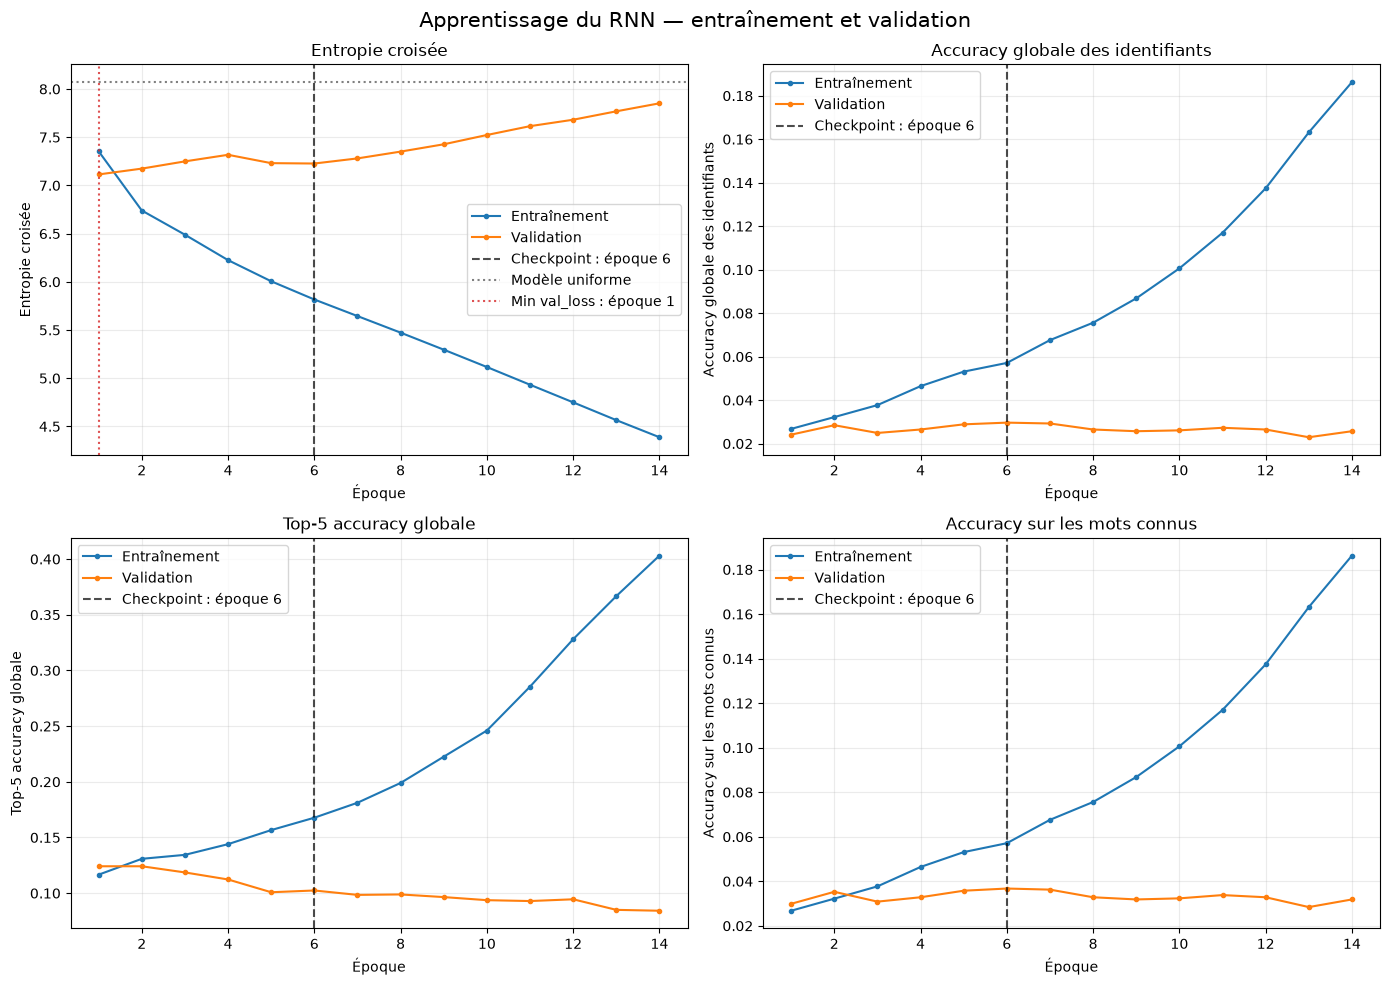

Résumé du meilleur modèle restauré :
  époques exécutées             : 14
  checkpoint                    : époque 6
  itérations Adam restaurées    : 1056
  meilleure val_accuracy connue : 3.67%
  minimum val_loss              : époque 1
  val_loss du modèle restauré   : 7.2272
  accuracy globale restaurée    : 2.97%
  top-5 globale restaurée       : 10.24%
  couverture connue             : 80.70%
  accuracy mots connus          : 3.67%
  accuracy ID des cibles [UNK]  : 0.00%
  perte moyenne mots connus     : 6.2977
  perte moyenne cibles [UNK]    : 11.1147
  prédictions PAD / [UNK]       : 0 / 0
  signal perte de surapprentissage : oui
  checkpoint local             : 4.85 Mio
  jeu de test utilisé           : non


In [25]:
courbes = historique_rnn.history

cles_attendues = {
    "loss",
    "val_loss",
    "accuracy_globale_ids",
    "val_accuracy_globale_ids",
    "top_5_accuracy_globale_ids",
    "val_top_5_accuracy_globale_ids",
    "accuracy_mots_connus",
    "val_accuracy_mots_connus",
}
cles_absentes = cles_attendues.difference(courbes)
assert not cles_absentes, f"Courbes absentes : {cles_absentes}"

nombre_epoques = len(courbes["loss"])
assert nombre_epoques == len(historique_rnn.epoch)
assert 1 <= nombre_epoques <= EPOQUES_MAX

for nom, valeurs in courbes.items():
    assert len(valeurs) == nombre_epoques
    assert np.all(np.isfinite(valeurs)), (
        f"Valeur non finie dans {nom}"
    )

for nom in cles_attendues:
    if "accuracy" in nom:
        valeurs = np.asarray(courbes[nom])
        assert np.all((0.0 <= valeurs) & (valeurs <= 1.0))

np.testing.assert_allclose(
    courbes["accuracy_globale_ids"],
    courbes["accuracy_mots_connus"],
    atol=1e-7,
)
assert np.all(
    np.asarray(courbes["top_5_accuracy_globale_ids"])
    >= np.asarray(courbes["accuracy_globale_ids"]) - 1e-7
)
assert np.all(
    np.asarray(courbes["val_top_5_accuracy_globale_ids"])
    >= np.asarray(courbes["val_accuracy_globale_ids"]) - 1e-7
)

valeurs_moniteur = np.asarray(courbes[MONITEUR])
indice_meilleure_epoque = int(np.argmax(valeurs_moniteur))
meilleure_epoque = indice_meilleure_epoque + 1
meilleure_valeur_moniteur = float(
    valeurs_moniteur[indice_meilleure_epoque]
)
indice_min_val_loss = int(np.argmin(courbes["val_loss"]))
epoque_min_val_loss = indice_min_val_loss + 1

assert CHEMIN_MEILLEURS_POIDS.is_file()
assert CHEMIN_MEILLEURS_POIDS.stat().st_size > 0
assert np.isclose(
    float(sauvegarde_meilleurs_poids.best),
    meilleure_valeur_moniteur,
)
assert np.isclose(
    float(arret_anticipe.best),
    meilleure_valeur_moniteur,
)

# EarlyStopping a déjà restauré ces poids en mémoire.
poids_restaures_en_memoire = [
    poids.numpy().copy()
    for poids in modele_rnn.weights
]

# Le rechargement explicite prouve que le fichier est exploitable.
modele_rnn.load_weights(str(CHEMIN_MEILLEURS_POIDS))

for poids_memoire, poids_fichier in zip(
    poids_restaures_en_memoire,
    modele_rnn.weights,
):
    np.testing.assert_allclose(
        poids_memoire,
        poids_fichier.numpy(),
        rtol=0.0,
        atol=0.0,
    )

iterations_adam_checkpoint = int(
    modele_rnn.optimizer.iterations.numpy()
)
assert iterations_adam_checkpoint == (
    meilleure_epoque * NOMBRE_LOTS_ENTRAINEMENT
)

mesures_validation = modele_rnn.evaluate(
    dataset_validation,
    verbose=0,
    return_dict=True,
)
assert np.isclose(
    mesures_validation["accuracy_mots_connus"],
    meilleure_valeur_moniteur,
    atol=1e-7,
)

cibles_audit = []
predictions_audit = []
pertes_audit = []

for lot_x, lot_y in dataset_validation:
    logits_audit = modele_rnn(lot_x, training=False)
    predictions = tf.argmax(
        logits_audit,
        axis=-1,
        output_type=tf.int32,
    )
    pertes = tf.nn.sparse_softmax_cross_entropy_with_logits(
        labels=lot_y,
        logits=logits_audit,
    )

    cibles_audit.append(lot_y.numpy())
    predictions_audit.append(predictions.numpy())
    pertes_audit.append(pertes.numpy())

cibles_audit = np.concatenate(cibles_audit)
predictions_audit = np.concatenate(predictions_audit)
pertes_audit = np.concatenate(pertes_audit)

masque_connu = (
    (cibles_audit != ID_PADDING)
    & (cibles_audit != ID_HORS_VOCABULAIRE)
)
masque_inconnu = cibles_audit == ID_HORS_VOCABULAIRE

assert len(cibles_audit) == 2529
assert int(np.sum(masque_connu)) == 2041
assert int(np.sum(masque_inconnu)) == 488
assert not np.any(cibles_audit == ID_PADDING)

couverture_connue = float(np.mean(masque_connu))
accuracy_connus_audit = float(np.mean(
    predictions_audit[masque_connu]
    == cibles_audit[masque_connu]
))
accuracy_inconnus_ids = float(np.mean(
    predictions_audit[masque_inconnu]
    == ID_HORS_VOCABULAIRE
))
accuracy_globale_audit = float(np.mean(
    predictions_audit == cibles_audit
))
perte_connus_audit = float(np.mean(pertes_audit[masque_connu]))
perte_inconnus_audit = float(np.mean(
    pertes_audit[masque_inconnu]
))
perte_globale_audit = float(np.mean(pertes_audit))

np.testing.assert_allclose(
    accuracy_globale_audit,
    couverture_connue * accuracy_connus_audit
    + (1.0 - couverture_connue) * accuracy_inconnus_ids,
    atol=1e-7,
)
np.testing.assert_allclose(
    perte_globale_audit,
    couverture_connue * perte_connus_audit
    + (1.0 - couverture_connue) * perte_inconnus_audit,
    rtol=1e-6,
)
np.testing.assert_allclose(
    accuracy_connus_audit,
    mesures_validation["accuracy_mots_connus"],
    atol=1e-7,
)
np.testing.assert_allclose(
    accuracy_globale_audit,
    mesures_validation["accuracy_globale_ids"],
    atol=1e-7,
)

signal_surapprentissage = (
    indice_min_val_loss < nombre_epoques - 1
    and courbes["loss"][-1] < courbes["loss"][indice_min_val_loss]
    and courbes["val_loss"][-1] > courbes["val_loss"][indice_min_val_loss]
)

epoques = np.arange(1, nombre_epoques + 1)
graphiques = [
    ("loss", "val_loss", "Entropie croisée"),
    (
        "accuracy_globale_ids",
        "val_accuracy_globale_ids",
        "Accuracy globale des identifiants",
    ),
    (
        "top_5_accuracy_globale_ids",
        "val_top_5_accuracy_globale_ids",
        "Top-5 accuracy globale",
    ),
    (
        "accuracy_mots_connus",
        "val_accuracy_mots_connus",
        "Accuracy sur les mots connus",
    ),
]

figure, axes = plt.subplots(2, 2, figsize=(14, 10))

for axe, (cle_train, cle_val, titre) in zip(
    axes.flat,
    graphiques,
):
    axe.plot(
        epoques,
        courbes[cle_train],
        marker="o",
        markersize=3,
        label="Entraînement",
    )
    axe.plot(
        epoques,
        courbes[cle_val],
        marker="o",
        markersize=3,
        label="Validation",
    )
    axe.axvline(
        meilleure_epoque,
        color="black",
        linestyle="--",
        alpha=0.7,
        label=f"Checkpoint : époque {meilleure_epoque}",
    )

    if cle_train == "loss":
        axe.axhline(
            np.log(taille_vocabulaire),
            color="gray",
            linestyle=":",
            label="Modèle uniforme",
        )
        axe.axvline(
            epoque_min_val_loss,
            color="tab:red",
            linestyle=":",
            alpha=0.8,
            label=f"Min val_loss : époque {epoque_min_val_loss}",
        )

    axe.set_title(titre)
    axe.set_xlabel("Époque")
    axe.set_ylabel(titre)
    axe.grid(alpha=0.25)
    axe.legend()

figure.suptitle(
    "Apprentissage du RNN — entraînement et validation",
    fontsize=15,
)
figure.tight_layout()
plt.show()

print("Résumé du meilleur modèle restauré :")
print("  époques exécutées             :", nombre_epoques)
print("  checkpoint                    : époque", meilleure_epoque)
print("  itérations Adam restaurées    :", iterations_adam_checkpoint)
print(
    "  meilleure val_accuracy connue :",
    f"{meilleure_valeur_moniteur:.2%}",
)
print("  minimum val_loss              : époque", epoque_min_val_loss)
print(
    "  val_loss du modèle restauré   :",
    f"{mesures_validation['loss']:.4f}",
)
print(
    "  accuracy globale restaurée    :",
    f"{accuracy_globale_audit:.2%}",
)
print(
    "  top-5 globale restaurée       :",
    f"{mesures_validation['top_5_accuracy_globale_ids']:.2%}",
)
print("  couverture connue             :", f"{couverture_connue:.2%}")
print("  accuracy mots connus          :", f"{accuracy_connus_audit:.2%}")
print("  accuracy ID des cibles [UNK]  :", f"{accuracy_inconnus_ids:.2%}")
print("  perte moyenne mots connus     :", f"{perte_connus_audit:.4f}")
print("  perte moyenne cibles [UNK]    :", f"{perte_inconnus_audit:.4f}")
print(
    "  prédictions PAD / [UNK]       :",
    int(np.sum(predictions_audit == ID_PADDING)),
    "/",
    int(np.sum(predictions_audit == ID_HORS_VOCABULAIRE)),
)
print(
    "  signal perte de surapprentissage :",
    "oui" if signal_surapprentissage else "non concluant",
)
print(
    "  checkpoint local             :",
    f"{CHEMIN_MEILLEURS_POIDS.stat().st_size / 1024**2:.2f} Mio",
)
print("  jeu de test utilisé           : non")


## Bilan de l’étape 7

L’arrêt anticipé a interrompu l’apprentissage après **14 époques sur 40**. La meilleure accuracy de validation sur les mots connus est atteinte à l’**époque 6** avec **3,67 %** ; les poids de cette époque ont été restaurés en mémoire et rechargés avec succès depuis le checkpoint local.

Le comportement des courbes fournit un **signal net de surapprentissage** :

- la perte d’entraînement passe de 7,3542 à 4,3879 entre les époques 1 et 14 ;
- l’accuracy d’entraînement passe de 2,68 % à 18,63 % ;
- la meilleure accuracy connue de validation plafonne à 3,67 % dès l’époque 6 ;
- la perte de validation est minimale à l’époque 1 avec 7,1140, puis atteint 7,8518 à l’époque 14.

Le minimum précoce de val_loss ne doit pas être interprété seul. Sur le modèle restauré, la perte moyenne vaut **6,2977** pour les mots connus mais **11,1147** pour les cibles [UNK]. Le modèle restauré ne prédit jamais [UNK] sur les 2 529 fenêtres de validation, résultat cohérent puisque cette classe n’a aucun exemple positif dans l’entraînement. Certaines fenêtres dont la cible est connue contiennent toutefois [UNK] dans leur contexte ; son embedding n’a jamais été appris sur l’entraînement, ce qui peut aussi réduire leur prédictibilité. Avec une couverture connue de **80,70 %**, nous retrouvons donc :

$$
A_{\mathrm{global}}
=0{,}8070\times3{,}67\%
\approx2{,}97\%.
$$

La top-5 accuracy globale restaurée atteint **10,24 %**. L’époque 6 est le meilleur checkpoint selon le protocole déclaré, pas un optimum statistique précis : son gain par rapport à l’époque 5 ne représente que deux prédictions connues supplémentaires. Ces scores modestes sont cohérents avec un corpus de seulement 34 poèmes d’entraînement, un vocabulaire de 3 203 identifiants, un contexte limité à trois mots et plusieurs suites poétiquement possibles pour un même contexte. Ils montrent que le modèle apprend le corpus mais généralise encore peu.

Le checkpoint mesure environ **4,85 Mio**. Son rechargement restaure les poids et ramène ici le compteur Adam à **1 056**, soit $6\times176$ mises à jour. Il reste local et est ignoré par Git grâce à la règle existante pour les fichiers .h5. Le test n’a servi ni à l’entraînement, ni à l’arrêt anticipé, ni au choix de l’époque, ni à cette analyse.

**Étape suivante :** étudier qualitativement quelques prédictions sur la validation et préparer la génération de texte, toujours sans ouvrir le jeu de test.


## 23. Examiner honnêtement les prédictions de validation

### 23.1 Passer des logits aux probabilités

L'entraînement est terminé et le checkpoint de l'époque 6 est figé. Une **inférence** calcule une sortie avec `training=False` : elle ne rétropropage aucun gradient et ne modifie ni les poids ni Adam. Pour une fenêtre $x_i$ et un mot $j$, le réseau fournit un logit $z_{i,j}$. Le softmax donne sa probabilité sur les $V=3\,203$ identifiants :

$$
p_{i,j}=P(y_i=j\mid x_i)
=\frac{\exp(z_{i,j})}{\sum_{\ell=0}^{V-1}\exp(z_{i,\ell})}.
$$

Le top-1 est l'identifiant de plus grand logit. Le top-5 contient les cinq plus grands logits :

$$
\widehat y_i=\operatorname*{arg\,max}_j z_{i,j},
\qquad
\operatorname{correct}_{i,5}
=\mathbf{1}\!\left[y_i\in\operatorname{TopK}(z_i,5)\right].
$$

Les cinq probabilités affichées restent celles du softmax sur le **vocabulaire complet** ; nous ne les renormalisons pas entre elles. Leur somme n'a donc aucune raison de valoir 1.

### 23.2 Rang et MRR

Le rang $r_i$ de la vraie cible vaut 1 si elle est la première proposition, 2 si elle est la deuxième, etc. En l'absence d'égalité exacte entre logits :

$$
r_i=1+\sum_{j=0}^{V-1}\mathbf{1}[z_{i,j}>z_{i,y_i}].
$$

Le rang réciproque moyen, ou MRR, valorise une cible placée près du sommet :

$$
\operatorname{MRR}=\frac{1}{N}\sum_{i=1}^{N}\frac{1}{r_i}.
$$

Il complète l'accuracy mais ne la remplace pas. Nous séparons aussi les cibles connues selon que leur contexte contient ou non `[UNK]`. L'embedding `[UNK]` n'a reçu aucune mise à jour utile pendant l'entraînement, puisque tous les mots d'entraînement appartenaient au vocabulaire.

### 23.3 Éviter de choisir seulement les beaux exemples

Nous afficherons exactement **une fenêtre par poème de validation** : la première dont la cible et les trois mots du contexte sont connus. Cette règle est fixée avant de regarder les prédictions. Elle évite le choix selon la réussite du modèle, mais favorise les débuts de poèmes : ces exemples sont des illustrations déterministes, pas un échantillon représentatif. Une autre continuation peut sembler plausible, mais la métrique n'accepte que le mot réellement présent dans le poème. Nous ne masquons ni `<PAD>` ni `[UNK]` pour calculer ces résultats : cela gonflerait artificiellement les scores. Le test reste fermé.


In [26]:
assert CHEMIN_MEILLEURS_POIDS.is_file()
assert "poemes_ids_test" not in globals()
assert "X_test" not in globals()
assert "y_test" not in globals()
assert "dataset_test" not in globals()
assert vectoriseur.get_vocabulary() == vocabulaire_avant_vectorisation

iterations_avant_inference = int(
    modele_rnn.optimizer.iterations.numpy()
)
poids_avant_inference = [
    poids.numpy().copy() for poids in modele_rnn.weights
]
etat_optimiseur_avant_inference = [
    variable.numpy().copy()
    for variable in modele_rnn.optimizer.variables
]

logits_validation_complets = modele_rnn.predict(
    X_validation,
    batch_size=TAILLE_LOT,
    verbose=0,
)
probabilites_validation = tf.nn.softmax(
    logits_validation_complets,
    axis=-1,
).numpy()
pertes_validation_detaillees = (
    tf.nn.sparse_softmax_cross_entropy_with_logits(
        labels=y_validation,
        logits=logits_validation_complets,
    ).numpy()
)

assert logits_validation_complets.shape == (
    len(y_validation),
    taille_vocabulaire,
)
assert np.all(np.isfinite(logits_validation_complets))
np.testing.assert_allclose(
    probabilites_validation.sum(axis=1),
    np.ones(len(y_validation)),
    rtol=1e-5,
    atol=1e-5,
)

probabilites_top5, ids_top5 = tf.math.top_k(
    probabilites_validation,
    k=5,
)
probabilites_top5 = probabilites_top5.numpy()
ids_top5 = ids_top5.numpy()
predictions_top1 = ids_top5[:, 0]
presence_cible_top5 = np.any(
    ids_top5 == y_validation[:, None],
    axis=1,
)

indices_lignes = np.arange(len(y_validation))
logits_vraies_cibles = logits_validation_complets[
    indices_lignes,
    y_validation,
]
rangs_cibles = 1 + np.sum(
    logits_validation_complets > logits_vraies_cibles[:, None],
    axis=1,
)
nombre_logit_ex_aequo = np.sum(
    logits_validation_complets == logits_vraies_cibles[:, None],
    axis=1,
)
assert np.all(nombre_logit_ex_aequo == 1), (
    "Une égalité de logits exige une règle de rang explicite."
)

masque_cible_connue = y_validation >= 2
masque_cible_inconnue = y_validation == ID_HORS_VOCABULAIRE
masque_contexte_avec_unk = np.any(
    X_validation == ID_HORS_VOCABULAIRE,
    axis=1,
)
masque_contexte_avec_padding = np.any(
    X_validation == ID_PADDING,
    axis=1,
)
masque_connu_contexte_sans_unk = (
    masque_cible_connue & ~masque_contexte_avec_unk
)
masque_connu_contexte_avec_unk = (
    masque_cible_connue & masque_contexte_avec_unk
)

assert np.all(masque_cible_connue | masque_cible_inconnue)
assert not np.any(masque_cible_connue & masque_cible_inconnue)
assert np.array_equal(
    masque_cible_connue,
    masque_connu_contexte_sans_unk
    | masque_connu_contexte_avec_unk,
)

def resumer_groupe_validation(nom, masque):
    effectif = int(np.sum(masque))
    assert effectif > 0
    return {
        "groupe": nom,
        "effectif": effectif,
        "top_1": float(np.mean(
            predictions_top1[masque] == y_validation[masque]
        )),
        "top_5": float(np.mean(presence_cible_top5[masque])),
        "perte": float(np.mean(
            pertes_validation_detaillees[masque]
        )),
        "mrr": float(np.mean(1.0 / rangs_cibles[masque])),
    }

groupes_validation = [
    resumer_groupe_validation(
        "Cible connue, contexte sans [UNK]",
        masque_connu_contexte_sans_unk,
    ),
    resumer_groupe_validation(
        "Cible connue, contexte avec [UNK]",
        masque_connu_contexte_avec_unk,
    ),
    resumer_groupe_validation(
        "Cible [UNK]",
        masque_cible_inconnue,
    ),
]

accuracy_top5_connus = float(np.mean(
    presence_cible_top5[masque_cible_connue]
))
mrr_connus = float(np.mean(
    1.0 / rangs_cibles[masque_cible_connue]
))
np.testing.assert_allclose(
    np.mean(
        predictions_top1[masque_cible_connue]
        == y_validation[masque_cible_connue]
    ),
    accuracy_connus_audit,
    atol=1e-7,
)

print("Analyse par difficulté sur la validation :")
print(
    f"{'Groupe':<39} {'N':>5} {'Top-1':>9} "
    f"{'Top-5':>9} {'Perte':>9} {'MRR':>9}"
)
for groupe in groupes_validation:
    print(
        f"{groupe['groupe']:<39} {groupe['effectif']:>5} "
        f"{groupe['top_1']:>8.2%} {groupe['top_5']:>8.2%} "
        f"{groupe['perte']:>9.4f} {groupe['mrr']:>9.4f}"
    )

print()
print("Résultats par poème de validation :")
print(
    f"{'Poème':<29} {'N':>5} {'Connus':>7} {'Couverture':>11} "
    f"{'Top-1 connu':>13} {'Top-5 connu':>13}"
)
for poeme in poemes_validation:
    masque_poeme = provenance_validation == poeme["numero"]
    masque_poeme_connu = masque_poeme & masque_cible_connue
    n_poeme = int(np.sum(masque_poeme))
    n_connu = int(np.sum(masque_poeme_connu))
    assert n_poeme > 0 and n_connu > 0
    couverture_poeme = n_connu / n_poeme
    top1_poeme = np.mean(
        predictions_top1[masque_poeme_connu]
        == y_validation[masque_poeme_connu]
    )
    top5_poeme = np.mean(
        presence_cible_top5[masque_poeme_connu]
    )
    titre_court = poeme["titre"][:28]
    print(
        f"{titre_court:<29} {n_poeme:>5} {n_connu:>7} "
        f"{couverture_poeme:>10.2%} "
        f"{top1_poeme:>12.2%} {top5_poeme:>12.2%}"
    )

indices_exemples_validation = []
for poeme in poemes_validation:
    candidats = np.flatnonzero(
        (provenance_validation == poeme["numero"])
        & masque_cible_connue
        & ~masque_contexte_avec_unk
        & ~masque_contexte_avec_padding
    )
    assert len(candidats) > 0
    indices_exemples_validation.append(int(candidats[0]))

titres_par_numero = {
    poeme["numero"]: poeme["titre"]
    for poeme in poemes_validation
}

print()
print("Exemples déterministes — un par poème :")
for indice in indices_exemples_validation:
    contexte = " ".join(
        token_affichable(id_token)
        for id_token in X_validation[indice]
    )
    cible = token_affichable(y_validation[indice])
    propositions = " | ".join(
        f"{token_affichable(id_token)} "
        f"({probabilite:.2%})"
        for id_token, probabilite in zip(
            ids_top5[indice],
            probabilites_top5[indice],
        )
    )
    numero = int(provenance_validation[indice])
    print()
    print(f"Poème {numero} — {titres_par_numero[numero]}")
    print(f"  contexte : {contexte}")
    print(
        f"  vraie cible : {cible} "
        f"(rang {int(rangs_cibles[indice])})"
    )
    print(f"  top 5      : {propositions}")

for poids_avant, poids_apres in zip(
    poids_avant_inference,
    modele_rnn.weights,
):
    np.testing.assert_array_equal(
        poids_avant,
        poids_apres.numpy(),
    )
assert len(etat_optimiseur_avant_inference) == len(
    modele_rnn.optimizer.variables
)
for variable_avant, variable_apres in zip(
    etat_optimiseur_avant_inference,
    modele_rnn.optimizer.variables,
):
    np.testing.assert_array_equal(
        variable_avant,
        variable_apres.numpy(),
    )
assert int(modele_rnn.optimizer.iterations.numpy()) == (
    iterations_avant_inference
)
assert vectoriseur.get_vocabulary() == vocabulaire_avant_vectorisation

print()
print("Top-5 sur toutes les cibles connues :", f"{accuracy_top5_connus:.2%}")
print("MRR sur toutes les cibles connues   :", f"{mrr_connus:.4f}")
print("Poids et compteur Adam modifiés     : non")
print("Jeu de test utilisé                 : non")


Analyse par difficulté sur la validation :
Groupe                                      N     Top-1     Top-5     Perte       MRR
Cible connue, contexte sans [UNK]        1008    3.47%   11.81%    6.4436    0.0859
Cible connue, contexte avec [UNK]        1033    3.87%   13.55%    6.1554    0.0985
Cible [UNK]                               488    0.00%    0.00%   11.1147    0.0003

Résultats par poème de validation :
Poème                             N  Connus  Couverture   Top-1 connu   Top-5 connu
J’aime l’araignée et j’aime     143      94     65.73%        5.32%       17.02%
La lune                         157     134     85.35%        1.49%        8.96%
Jeanne endormie                 269     229     85.13%        3.93%       14.41%
À une femme                      80      69     86.25%        8.70%       24.64%
Guitare                         450     356     79.11%        1.97%       12.92%
Demain, dès l’aube              105      83     79.05%        3.61%       12.05%
Tristesse d’

## 24. Générer du texte mot après mot

### 24.1 Boucle autorégressive et contexte glissant

À partir d'une amorce $(s_1,\ldots,s_t)$, le RNN consulte seulement ses trois derniers identifiants, prédit $s_{t+1}$, l'ajoute au texte puis recommence :

$$
P(s_{t+1:t+n}\mid s_{1:t})
=\prod_{r=t}^{t+n-1}
P(s_{r+1}\mid s_{r-2},s_{r-1},s_r).
$$

Ainsi, `[la, nuit, est]` peut produire `sombre`, puis la fenêtre devient `[nuit, est, sombre]`. Le `SimpleRNN` n'est pas stateful ici : à chaque appel, il ne possède aucune mémoire cachée au-delà des trois identifiants fournis.

### 24.2 Choix glouton, température et top-k

Le choix glouton prend toujours $\operatorname*{arg\,max}_j z_j$. Il est reproductible mais peut créer des répétitions. Pour échantillonner, une température $T>0$ transforme les scores :

$$
p_j^{(T)}
=\frac{\exp(z_j/T)}{\sum_{\ell}\exp(z_\ell/T)}.
$$

Quand $T<1$, la distribution se concentre sur les mots déjà probables. Quand $T>1$, elle s'aplatit et augmente la diversité ainsi que le risque d'incohérence. $T=0$ n'est pas défini : le mode glouton utilise directement `argmax`. Pour la stabilité numérique, le code soustrait le plus grand score avant l'exponentielle.

Nous limitons ensuite l'échantillonnage à l'ensemble $A_k$ des $k=10$ meilleurs identifiants **autorisés**, donc parmi $\{2,\ldots,V-1\}$ après exclusion de `<PAD>` et `[UNK]`, puis nous renormalisons :

$$
q_j^{(T,k)}=
\begin{cases}
\dfrac{\exp(z_j/T)}{\sum_{\ell\in A_k}\exp(z_\ell/T)},
& j\in A_k,\\
0,& j\notin A_k.
\end{cases}
$$

Ce top-k est une règle de **génération**, pas une correction des métriques précédentes. Nous interdisons aussi `<PAD>` et `[UNK]` pendant la génération : ce sont des marqueurs techniques, pas des mots restituables. Ils n'ont pas été retirés lors de l'évaluation.

### 24.3 Protocole de comparaison

L'amorce est le contexte du premier exemple déterministe ci-dessus, donc elle vient de la validation et pas du test. Nous fixons avant de voir les textes : 30 mots, top-k égal à 10, températures 0,8, 1,0 et 1,2, ainsi que la même graine réinitialisée pour chaque température. Cette comparaison contrôle mieux la part du hasard, même si les contextes divergent dès qu'un mot différent est tiré. Ces textes illustrent le comportement ; ils ne constituent pas une mesure de performance. La ponctuation a été supprimée, aucun jeton de fin n'a été appris et la longueur doit donc être imposée.


In [27]:
NOMBRE_MOTS_GENERES = 30
TOP_K_GENERATION = 10
TEMPERATURES_GENERATION = (0.8, 1.0, 1.2)

indice_amorce = indices_exemples_validation[0]
ids_amorce = X_validation[indice_amorce].astype(
    np.int32,
    copy=True,
).tolist()
assert len(ids_amorce) == TAILLE_CONTEXTE
assert all(id_token >= 2 for id_token in ids_amorce)

poids_avant_generation = [
    poids.numpy().copy() for poids in modele_rnn.weights
]
etat_optimiseur_avant_generation = [
    variable.numpy().copy()
    for variable in modele_rnn.optimizer.variables
]
iterations_avant_generation = int(
    modele_rnn.optimizer.iterations.numpy()
)

def calculer_logits_prochain_mot(ids_courants):
    if len(ids_courants) == 0:
        raise ValueError("L'amorce doit contenir au moins un mot.")
    contexte = np.full(
        TAILLE_CONTEXTE,
        ID_PADDING,
        dtype=np.int32,
    )
    ids_recents = np.asarray(
        ids_courants[-TAILLE_CONTEXTE:],
        dtype=np.int32,
    )
    contexte[-len(ids_recents):] = ids_recents

    logits = modele_rnn(
        contexte[None, :],
        training=False,
    )[0].numpy().copy()
    assert np.all(np.isfinite(logits))

    # Politique de génération uniquement : ces marqueurs ne sont pas des mots.
    logits[ID_PADDING] = -np.inf
    logits[ID_HORS_VOCABULAIRE] = -np.inf
    return logits

def echantillonner_top_k(logits, temperature, top_k, generateur):
    if temperature <= 0:
        raise ValueError("La température doit être strictement positive.")
    if not 1 <= top_k <= taille_vocabulaire - 2:
        raise ValueError("top_k est hors limites.")

    ids_candidats = np.argpartition(logits, -top_k)[-top_k:]
    ids_candidats = ids_candidats[
        np.argsort(logits[ids_candidats])[::-1]
    ]
    scores = logits[ids_candidats] / temperature
    scores = scores - np.max(scores)
    probabilites = np.exp(scores)
    probabilites = probabilites / probabilites.sum()
    np.testing.assert_allclose(
        probabilites.sum(),
        1.0,
        atol=1e-7,
    )
    return int(generateur.choice(
        ids_candidats,
        p=probabilites,
    ))

def generer_ids(
    amorce,
    nombre_mots,
    mode="glouton",
    temperature=1.0,
    top_k=10,
    graine=SEED,
):
    ids_generes = list(map(int, amorce))
    generateur = np.random.default_rng(graine)

    for _ in range(nombre_mots):
        logits = calculer_logits_prochain_mot(ids_generes)
        if mode == "glouton":
            prochain_id = int(np.argmax(logits))
        elif mode == "top_k":
            prochain_id = echantillonner_top_k(
                logits,
                temperature,
                top_k,
                generateur,
            )
        else:
            raise ValueError(f"Mode inconnu : {mode}")

        assert prochain_id not in {
            ID_PADDING,
            ID_HORS_VOCABULAIRE,
        }
        ids_generes.append(prochain_id)

    return ids_generes

generations = {
    "Glouton": generer_ids(
        ids_amorce,
        NOMBRE_MOTS_GENERES,
        mode="glouton",
    )
}
for temperature in TEMPERATURES_GENERATION:
    etiquette = f"Top-{TOP_K_GENERATION}, T={temperature:.1f}"
    generations[etiquette] = generer_ids(
        ids_amorce,
        NOMBRE_MOTS_GENERES,
        mode="top_k",
        temperature=temperature,
        top_k=TOP_K_GENERATION,
        graine=SEED,
    )

texte_amorce = " ".join(
    token_affichable(id_token) for id_token in ids_amorce
)
numero_amorce = int(provenance_validation[indice_amorce])

print("Amorce fixée :", texte_amorce)
print(
    "Origine        :",
    f"poème {numero_amorce} — {titres_par_numero[numero_amorce]}",
)
print()
for etiquette, ids_texte in generations.items():
    texte = " ".join(
        token_affichable(id_token) for id_token in ids_texte
    )
    ids_nouveaux = ids_texte[len(ids_amorce):]
    diversite = len(set(ids_nouveaux)) / len(ids_nouveaux)
    print(etiquette)
    print(texte)
    print(f"Ratio types/tokens sur 30 mots : {diversite:.2%}")
    print()

for poids_avant, poids_apres in zip(
    poids_avant_generation,
    modele_rnn.weights,
):
    np.testing.assert_array_equal(
        poids_avant,
        poids_apres.numpy(),
    )
assert len(etat_optimiseur_avant_generation) == len(
    modele_rnn.optimizer.variables
)
for variable_avant, variable_apres in zip(
    etat_optimiseur_avant_generation,
    modele_rnn.optimizer.variables,
):
    np.testing.assert_array_equal(
        variable_avant,
        variable_apres.numpy(),
    )
assert int(modele_rnn.optimizer.iterations.numpy()) == (
    iterations_avant_generation
)
assert vectoriseur.get_vocabulary() == vocabulaire_avant_vectorisation
assert "poemes_ids_test" not in globals()
assert "X_test" not in globals()
assert "y_test" not in globals()
assert "dataset_test" not in globals()

print("Réglages de génération figés : oui")
print("Poids et compteur Adam modifiés : non")
print("Jeu de test utilisé             : non")


Amorce fixée : j'aime l'araignée et
Origine        : poème 20 — J’aime l’araignée et j’aime l’ortie

Glouton
j'aime l'araignée et s'éveille reitres les graine colossales troublent les morts couchés et la nuit et la nuit et la nuit et la nuit et la nuit et la nuit et la nuit
Ratio types/tokens sur 30 mots : 36.67%

Top-10, T=0.8
j'aime l'araignée et trouvâmes voyait qui plus de que des morts colossales troublent les coeurs et que les arches colossales troublent la voix du lui se enfant des salles de la mer aux
Ratio types/tokens sur 30 mots : 76.67%

Top-10, T=1.0
j'aime l'araignée et trouvâmes voyait qui plus de que le jour et les jours se sont des fond et les nuit du morts aux hirondelles de dans de vous des hirondelles et de
Ratio types/tokens sur 30 mots : 73.33%

Top-10, T=1.2
j'aime l'araignée et trouvâmes voyait qui plus de que le jour et les jours se hirondelles à les petites qui troublent à ne yeux des jour la voix et les nuit et ce
Ratio types/tokens sur 30 mots : 76.67%

Régl

## Bilan de l'étape 8

L'audit utilise toutes les fenêtres de validation pour les mesures et une règle déterministe pour les exemples. Sur les 2 041 cibles connues, la top-5 accuracy atteint **12,69 %** et le MRR **0,0923**. Les 1 008 exemples sans [UNK] dans le contexte obtiennent 3,47 % en top-1 et 11,81 % en top-5 ; les 1 033 exemples avec au moins un [UNK] obtiennent respectivement 3,87 % et 13,55 %. Ce léger avantage apparent ne prouve pas que [UNK] aide : les deux groupes contiennent des mots, des positions et des poèmes différents. Il faudrait une expérience contrôlée pour isoler cet effet.

Les 488 cibles [UNK] obtiennent 0 % en top-1 et en top-5, avec une perte moyenne de 11,1147. Les résultats connus varient descriptivement entre les sept poèmes : la top-1 va de **1,49 % à 8,70 %** et la top-5 de **8,96 % à 24,64 %**. Les effectifs connus vont toutefois de 69 à 1 076 fenêtres ; ces écarts peuvent donc aussi refléter l'incertitude des petits poèmes. Cette dispersion illustre pourquoi quelques sorties lisibles ne doivent jamais remplacer les métriques complètes.

La génération compare une décision gloutonne et trois échantillonnages top-10 aux températures 0,8, 1,0 et 1,2, avec la même graine réinitialisée. Le mode glouton répète « et la nuit » et son ratio types/tokens vaut **36,67 %**. Les trois tirages top-10 atteignent **76,67 %**, **73,33 %** et **76,67 %**. Cette absence d'ordre monotone rappelle qu'un seul tirage ne permet pas d'estimer proprement l'effet de la température. Le ratio sur 30 mots décrit seulement la répétition à longueur fixe : ce n'est ni une mesure générale de diversité, ni une mesure de qualité. <PAD> et [UNK] sont exclus uniquement de la génération, jamais des métriques.

Ces textes ne prouvent pas que le modèle sait écrire comme Victor Hugo. Le réseau ne voit que trois mots à la fois, ignore la ponctuation, ne possède aucun jeton de fin et a surappris son petit corpus. Une suite plausible différente du poème est aussi comptée comme fausse lors de l'évaluation exacte. Les poids, Adam et le vocabulaire sont restés inchangés, et le test est toujours fermé.

**Étape suivante :** figer définitivement ce protocole, ouvrir le test une seule fois, calculer toutes les métriques finales à partir d'une unique passe d'inférence, puis ne plus modifier le modèle à partir de ces résultats.


## 25. Ouvrir le test une seule fois

### 25.1 Le modèle est déjà choisi

Le test ne doit jamais choisir une architecture, une époque ou un hyperparamètre. Notre checkpoint a été sélectionné uniquement sur la validation :

$$
e^*=\operatorname*{arg\,max}_e
A_{\mathrm{connus,val}}^{(e)}=6,
\qquad
\theta^*=\theta^{(6)}.
$$

Le vocabulaire, la longueur de contexte, les baselines et les règles de génération sont également figés. Après lecture du test, nous ne modifierons plus ce SimpleRNN. Une faiblesse découverte sera rapportée comme une limite, pas corrigée à partir du test.

Les textes bruts et les titres du test existent en mémoire depuis la séparation des 48 poèmes. Dans cette expérience, **ouvrir le test** signifie effectuer maintenant sa première vectorisation, construire ses fenêtres, puis réaliser sa seule inférence par le modèle.

### 25.2 Conserver exactement le même prétraitement

Pour un poème test de $n_p$ mots, le padding à gauche permet de créer une cible pour chaque mot, y compris au début :

$$
x_{p,t}=
(\widetilde z_{p,t-3},\widetilde z_{p,t-2},\widetilde z_{p,t-1}),
\qquad
y_{p,t}=z_{p,t},
\qquad 1\leq t\leq n_p.
$$

Ainsi, contrairement à une construction qui supprimerait les trois premiers mots :

$$
N_{\mathrm{test}}=
\sum_{p\in\mathcal P_{\mathrm{test}}}n_p.
$$

Dans chacun des sept poèmes, la première fenêtre contient trois PAD, la deuxième en contient deux et la troisième un. Au total, chaque quantité apparaît donc sept fois. Aucun PAD ne sera une cible et aucune fenêtre ne traversera une frontière de poème.

### 25.3 Une unique passe et des garde-fous vérifiables

Nous rechargerons le checkpoint, enregistrerons une copie des poids, de toutes les variables d'Adam, du vocabulaire et de l'empreinte du fichier, puis appellerons le modèle **une seule fois** sur toutes les fenêtres :

$$
Z_{\mathrm{test}}=f_{\theta^*}(X_{\mathrm{test}}).
$$

Toutes les métriques suivantes seront dérivées de ce même tableau de logits. Il n'y aura aucun appel à fit, adapt, evaluate ou predict. Le verrou Python empêche une seconde ouverture accidentelle dans le même noyau ; une exécution intégrale depuis un noyau neuf reste naturellement possible pour reproduire le notebook.


In [28]:
assert "EVALUATION_TEST_EFFECTUEE" not in globals(), (
    "Le test a déjà été ouvert dans ce noyau. "
    "Redémarrez le noyau pour reproduire tout le notebook."
)
for nom_objet_test in (
    "poemes_ids_test",
    "X_test",
    "y_test",
    "provenance_test",
    "logits_test_finaux",
):
    assert nom_objet_test not in globals()
EVALUATION_TEST_EFFECTUEE = False

assert CHEMIN_MEILLEURS_POIDS.is_file()
assert meilleure_epoque == 6
assert meilleure_epoque == indice_meilleure_epoque + 1
assert vectoriseur.get_vocabulary() == vocabulaire_avant_vectorisation

numeros_train = {p["numero"] for p in poemes_entrainement}
numeros_validation = {p["numero"] for p in poemes_validation}
numeros_test = {p["numero"] for p in poemes_test}
assert numeros_train.isdisjoint(numeros_validation)
assert numeros_train.isdisjoint(numeros_test)
assert numeros_validation.isdisjoint(numeros_test)
assert numeros_train | numeros_validation | numeros_test == set(
    range(1, 49)
)
assert sorted(numeros_test) == attendus_test

# Ces baselines sont entièrement définies avant la vectorisation du test.
frequences_cibles_train = np.bincount(
    y_entrainement,
    minlength=taille_vocabulaire,
).astype(np.int64)
assert frequences_cibles_train[ID_PADDING] == 0
assert frequences_cibles_train[ID_HORS_VOCABULAIRE] == 0

ordre_frequences_train = np.argsort(
    -frequences_cibles_train,
    kind="stable",
)
ids_top5_frequence_train = ordre_frequences_train[:5]
id_majoritaire_train = int(ids_top5_frequence_train[0])
assert np.all(ids_top5_frequence_train >= 2)
assert len(set(ids_top5_frequence_train.tolist())) == 5

probabilites_unigramme_train = (
    frequences_cibles_train + 1.0
) / (len(y_entrainement) + taille_vocabulaire)
np.testing.assert_allclose(
    probabilites_unigramme_train.sum(),
    1.0,
    atol=1e-12,
)

# Rechargement explicite du checkpoint choisi sur la validation.
modele_rnn.load_weights(str(CHEMIN_MEILLEURS_POIDS))
assert int(modele_rnn.optimizer.iterations.numpy()) == (
    meilleure_epoque * NOMBRE_LOTS_ENTRAINEMENT
)

identites_objets_avant_test = (
    id(modele_rnn),
    id(modele_rnn.optimizer),
    id(vectoriseur),
)
empreinte_checkpoint_avant_test = hashlib.sha256(
    CHEMIN_MEILLEURS_POIDS.read_bytes()
).hexdigest()
vocabulaire_avant_test = tuple(vectoriseur.get_vocabulary())
poids_avant_test = [
    poids.numpy().copy() for poids in modele_rnn.weights
]
etat_optimiseur_avant_test = [
    variable.numpy().copy()
    for variable in modele_rnn.optimizer.variables
]
iterations_avant_test = int(
    modele_rnn.optimizer.iterations.numpy()
)

# Première vectorisation et premier fenêtrage du test.
poemes_ids_test = vectoriser_poemes_separement(poemes_test)
(
    X_test,
    y_test,
    provenance_test,
    statistiques_fenetres_test,
) = assembler_fenetres(poemes_ids_test)

verifier_jeu_fenetres(
    poemes_ids_test,
    X_test,
    y_test,
    provenance_test,
)

nombre_mots_test = sum(
    len(poeme["ids"]) for poeme in poemes_ids_test
)
assert len(poemes_ids_test) == 7
assert nombre_mots_test == 2327
assert X_test.shape == (2327, TAILLE_CONTEXTE)
assert y_test.shape == (2327,)
assert provenance_test.shape == y_test.shape
assert X_test.dtype == y_test.dtype == np.int32
assert np.array_equal(
    y_test,
    np.concatenate([p["ids"] for p in poemes_ids_test]),
)
assert np.count_nonzero(y_test == ID_HORS_VOCABULAIRE) == 532
assert not np.any(y_test == ID_PADDING)
assert set(np.unique(provenance_test)) == numeros_test

nombre_pad_par_fenetre_test = np.sum(
    X_test == ID_PADDING,
    axis=1,
)
assert np.count_nonzero(nombre_pad_par_fenetre_test == 3) == 7
assert np.count_nonzero(nombre_pad_par_fenetre_test == 2) == 7
assert np.count_nonzero(nombre_pad_par_fenetre_test == 1) == 7
assert np.count_nonzero(X_test == ID_PADDING) == 42

# UNIQUE appel du RNN sur le test, en mode inférence.
_nombre_passes_inference_test = 0

def inferer_test_une_fois(entrees):
    global _nombre_passes_inference_test
    assert _nombre_passes_inference_test == 0, (
        "Une seconde passe sur le test est interdite."
    )
    _nombre_passes_inference_test += 1
    return modele_rnn(
        tf.convert_to_tensor(entrees),
        training=False,
    ).numpy()

logits_test_finaux = inferer_test_une_fois(X_test)
assert _nombre_passes_inference_test == 1
EVALUATION_TEST_EFFECTUEE = True

assert logits_test_finaux.shape == (
    len(y_test),
    taille_vocabulaire,
)
assert np.all(np.isfinite(logits_test_finaux))

for avant, apres in zip(poids_avant_test, modele_rnn.weights):
    np.testing.assert_array_equal(avant, apres.numpy())
assert len(etat_optimiseur_avant_test) == len(
    modele_rnn.optimizer.variables
)
for avant, apres in zip(
    etat_optimiseur_avant_test,
    modele_rnn.optimizer.variables,
):
    np.testing.assert_array_equal(avant, apres.numpy())
assert int(modele_rnn.optimizer.iterations.numpy()) == iterations_avant_test
assert tuple(vectoriseur.get_vocabulary()) == vocabulaire_avant_test
assert identites_objets_avant_test == (
    id(modele_rnn),
    id(modele_rnn.optimizer),
    id(vectoriseur),
)
assert hashlib.sha256(
    CHEMIN_MEILLEURS_POIDS.read_bytes()
).hexdigest() == empreinte_checkpoint_avant_test

print("Poèmes de test                 :", len(poemes_ids_test))
print("Mots et fenêtres de test       :", len(y_test))
print("Cibles connues / [UNK]         :", 1795, "/", 532)
print("Occurrences de PAD en contexte :", np.count_nonzero(
    X_test == ID_PADDING
))
print("Appels du RNN sur le test       :", _nombre_passes_inference_test)
print("fit / adapt / evaluate          : aucun")
print("Poids, Adam, vocabulaire        : inchangés")


Poèmes de test                 : 7
Mots et fenêtres de test       : 2327
Cibles connues / [UNK]         : 1795 / 532
Occurrences de PAD en contexte : 42
Appels du RNN sur le test       : 1
fit / adapt / evaluate          : aucun
Poids, Adam, vocabulaire        : inchangés


## 26. Calculer toutes les métriques depuis les mêmes logits

### 26.1 Métrique principale et couverture

Pour l'exemple $i$, définissons le masque de cible connue $m_i$, le masque de cible inconnue $u_i$ et l'indicateur de bonne prédiction $c_i$ :

$$
m_i=\mathbf 1[y_i\geq2],
\qquad
u_i=\mathbf 1[y_i=1],
\qquad
c_i=\mathbf 1[\widehat y_i=y_i].
$$

La couverture mesure la part des vraies cibles représentables par le vocabulaire d'entraînement :

$$
C=\frac{1}{N}\sum_{i=1}^{N}m_i.
$$

Notre résultat principal est l'accuracy sur ces cibles connues :

$$
A_{\mathrm{connus}}=
\frac{\sum_i m_i c_i}{\sum_i m_i}.
$$

Nous publions aussi l'accuracy globale et celle de l'identifiant [UNK], avec l'identité de contrôle :

$$
A_{\mathrm{global}}=
C A_{\mathrm{connus}}+(1-C)A_{\mathrm{UNK}}.
$$

Prédire correctement l'identifiant [UNK] ne permettrait pas de retrouver le vrai mot absent ; cette mesure reste donc secondaire.

### 26.2 Top-5, rang et MRR

Le top-5 est correct si la cible figure parmi les cinq plus grands logits, sans masquer PAD ni [UNK] :

$$
q_i^{(5)}=\mathbf 1[y_i\in\operatorname{TopK}(z_i,5)].
$$

Le rang de la cible et le rang réciproque moyen sont :

$$
r_i=1+\sum_j\mathbf 1[z_{i,j}>z_{i,y_i}],
\qquad
\operatorname{MRR}=\frac{1}{N}\sum_i\frac{1}{r_i}.
$$

### 26.3 Perte et perplexité

La perte individuelle est calculée de façon stable directement depuis les logits :

$$
\ell_i=\operatorname{logsumexp}(z_i)-z_{i,y_i}.
$$

Pour un groupe $S$, sa perte moyenne et sa perplexité valent :

$$
L_S=\frac{1}{|S|}\sum_{i\in S}\ell_i,
\qquad
\operatorname{PPL}_S=\exp(L_S).
$$

Une perplexité plus faible est meilleure, mais elle ne se compare qu'entre modèles utilisant exactement le même vocabulaire et la même tokenisation. Les pertes, et non les perplexités, suivent une moyenne arithmétique entre cibles connues et [UNK].

### 26.4 Baselines fixées sur l'entraînement

Avant d'ouvrir le test, nous avons figé trois repères : toujours prédire le mot d'entraînement le plus fréquent, proposer les cinq mots les plus fréquents, et une distribution unigramme avec lissage additif :

$$
q_j=\frac{c_{\mathrm{train}}(j)+1}{N_{\mathrm{train}}+V}.
$$

Ces baselines indiquent si le RNN exploite davantage que la seule fréquence globale des mots.


In [29]:
assert EVALUATION_TEST_EFFECTUEE is True
assert _nombre_passes_inference_test == 1

indices_lignes_test = np.arange(len(y_test))
pertes_test_detaillees = (
    tf.nn.sparse_softmax_cross_entropy_with_logits(
        labels=y_test,
        logits=logits_test_finaux,
    ).numpy()
)

scores_top5_test, ids_top5_test = tf.math.top_k(
    logits_test_finaux,
    k=5,
)
scores_top5_test = scores_top5_test.numpy()
ids_top5_test = ids_top5_test.numpy()
predictions_test_top1 = ids_top5_test[:, 0]
presence_cible_top5_test = np.any(
    ids_top5_test == y_test[:, None],
    axis=1,
)

log_normalisateurs_test = tf.reduce_logsumexp(
    logits_test_finaux,
    axis=1,
).numpy()
probabilites_top5_test = np.exp(
    scores_top5_test - log_normalisateurs_test[:, None]
)
confiance_top1_test = probabilites_top5_test[:, 0]
assert np.all(probabilites_top5_test.sum(axis=1) <= 1.0 + 1e-6)

logits_cibles_test = logits_test_finaux[
    indices_lignes_test,
    y_test,
]
rangs_cibles_test = 1 + np.sum(
    logits_test_finaux > logits_cibles_test[:, None],
    axis=1,
)
nombre_ex_aequo_test = np.sum(
    logits_test_finaux == logits_cibles_test[:, None],
    axis=1,
)
assert np.all(nombre_ex_aequo_test == 1)

masque_cible_connue_test = y_test >= 2
masque_cible_unk_test = y_test == ID_HORS_VOCABULAIRE
assert np.all(masque_cible_connue_test | masque_cible_unk_test)
assert not np.any(masque_cible_connue_test & masque_cible_unk_test)
assert int(np.sum(masque_cible_connue_test)) == 1795
assert int(np.sum(masque_cible_unk_test)) == 532

correct_test = predictions_test_top1 == y_test
couverture_test = float(np.mean(masque_cible_connue_test))
accuracy_globale_test = float(np.mean(correct_test))
accuracy_connus_test = float(np.mean(
    correct_test[masque_cible_connue_test]
))
accuracy_unk_test = float(np.mean(
    correct_test[masque_cible_unk_test]
))

top5_globale_test = float(np.mean(presence_cible_top5_test))
top5_connus_test = float(np.mean(
    presence_cible_top5_test[masque_cible_connue_test]
))
top5_unk_test = float(np.mean(
    presence_cible_top5_test[masque_cible_unk_test]
))

perte_globale_test = float(np.mean(pertes_test_detaillees))
perte_connus_test = float(np.mean(
    pertes_test_detaillees[masque_cible_connue_test]
))
perte_unk_test = float(np.mean(
    pertes_test_detaillees[masque_cible_unk_test]
))
perplexite_globale_test = float(np.exp(perte_globale_test))
perplexite_connus_test = float(np.exp(perte_connus_test))
perplexite_unk_test = float(np.exp(perte_unk_test))

mrr_globale_test = float(np.mean(1.0 / rangs_cibles_test))
mrr_connus_test = float(np.mean(
    1.0 / rangs_cibles_test[masque_cible_connue_test]
))

np.testing.assert_allclose(
    accuracy_globale_test,
    couverture_test * accuracy_connus_test
    + (1.0 - couverture_test) * accuracy_unk_test,
    atol=1e-7,
)
np.testing.assert_allclose(
    top5_globale_test,
    couverture_test * top5_connus_test
    + (1.0 - couverture_test) * top5_unk_test,
    atol=1e-7,
)
np.testing.assert_allclose(
    perte_globale_test,
    couverture_test * perte_connus_test
    + (1.0 - couverture_test) * perte_unk_test,
    rtol=1e-6,
)

accuracy_majoritaire_connus_test = float(np.mean(
    y_test[masque_cible_connue_test] == id_majoritaire_train
))
top5_frequence_connus_test = float(np.mean(np.isin(
    y_test[masque_cible_connue_test],
    ids_top5_frequence_train,
)))
pertes_unigramme_test = -np.log(
    probabilites_unigramme_train[y_test]
)
perte_unigramme_globale_test = float(np.mean(pertes_unigramme_test))
perte_unigramme_connus_test = float(np.mean(
    pertes_unigramme_test[masque_cible_connue_test]
))

assert top5_globale_test >= accuracy_globale_test
assert top5_connus_test >= accuracy_connus_test
assert 0.0 <= mrr_connus_test <= 1.0
assert np.all(np.isfinite([
    perplexite_globale_test,
    perplexite_connus_test,
    perplexite_unk_test,
]))

resultats_test_finaux = {
    "effectif": len(y_test),
    "couverture_connue": couverture_test,
    "accuracy_globale": accuracy_globale_test,
    "accuracy_connus": accuracy_connus_test,
    "accuracy_unk": accuracy_unk_test,
    "top5_globale": top5_globale_test,
    "top5_connus": top5_connus_test,
    "top5_unk": top5_unk_test,
    "mrr_global": mrr_globale_test,
    "mrr_connus": mrr_connus_test,
    "perte_globale": perte_globale_test,
    "perte_connus": perte_connus_test,
    "perte_unk": perte_unk_test,
    "perplexite_globale": perplexite_globale_test,
    "perplexite_connus": perplexite_connus_test,
    "perplexite_unk": perplexite_unk_test,
    "baseline_accuracy_majoritaire_connus": accuracy_majoritaire_connus_test,
    "baseline_top5_frequence_connus": top5_frequence_connus_test,
    "baseline_perte_unigramme_globale": perte_unigramme_globale_test,
    "baseline_perte_unigramme_connus": perte_unigramme_connus_test,
}

print("ÉVALUATION FINALE DU TEST")
print()
print("Effectif total                  :", len(y_test))
print("Cibles connues / [UNK]          :", 1795, "/", 532)
print("Couverture connue               :", f"{couverture_test:.2%}")
print("Accuracy globale                :", f"{accuracy_globale_test:.2%}")
print("Accuracy mots connus            :", f"{accuracy_connus_test:.2%}")
print("Accuracy identifiant [UNK]      :", f"{accuracy_unk_test:.2%}")
print("Top-5 globale                   :", f"{top5_globale_test:.2%}")
print("Top-5 mots connus               :", f"{top5_connus_test:.2%}")
print("Top-5 identifiant [UNK]         :", f"{top5_unk_test:.2%}")
print("MRR global                      :", f"{mrr_globale_test:.4f}")
print("MRR mots connus                 :", f"{mrr_connus_test:.4f}")
print("Perte globale                   :", f"{perte_globale_test:.4f}")
print("Perte mots connus               :", f"{perte_connus_test:.4f}")
print("Perte cibles [UNK]              :", f"{perte_unk_test:.4f}")
print("Perplexité globale              :", f"{perplexite_globale_test:.2f}")
print("Perplexité mots connus          :", f"{perplexite_connus_test:.2f}")
print("Perplexité cibles [UNK]         :", f"{perplexite_unk_test:.2f}")
print(
    "Prédictions PAD / [UNK]         :",
    int(np.sum(predictions_test_top1 == ID_PADDING)),
    "/",
    int(np.sum(predictions_test_top1 == ID_HORS_VOCABULAIRE)),
)
print("Identifiants différents prédits :", len(np.unique(
    predictions_test_top1
)))
print()
print(
    "Baseline majoritaire — connus   :",
    token_affichable(id_majoritaire_train),
    f"→ {accuracy_majoritaire_connus_test:.2%}",
)
print("Baseline top-5 fréquence — connus :", f"{top5_frequence_connus_test:.2%}")
print("Perte unigramme globale        :", f"{perte_unigramme_globale_test:.4f}")
print("Perte unigramme mots connus    :", f"{perte_unigramme_connus_test:.4f}")
print("Repère uniforme log(V)         :", f"{np.log(taille_vocabulaire):.4f}")
print()
print(
    "Écart top-1 connu test - val   :",
    f"{accuracy_connus_test - accuracy_connus_audit:+.2%}",
)
print(
    "Écart top-5 connu test - val   :",
    f"{top5_connus_test - accuracy_top5_connus:+.2%}",
)


ÉVALUATION FINALE DU TEST

Effectif total                  : 2327
Cibles connues / [UNK]          : 1795 / 532
Couverture connue               : 77.14%
Accuracy globale                : 3.18%
Accuracy mots connus            : 4.12%
Accuracy identifiant [UNK]      : 0.00%
Top-5 globale                   : 10.96%
Top-5 mots connus               : 14.21%
Top-5 identifiant [UNK]         : 0.00%
MRR global                      : 0.0777
MRR mots connus                 : 0.1006
Perte globale                   : 7.5190
Perte mots connus               : 6.4305
Perte cibles [UNK]              : 11.1915
Perplexité globale              : 1842.64
Perplexité mots connus          : 620.49
Perplexité cibles [UNK]         : 72508.40
Prédictions PAD / [UNK]         : 0 / 0
Identifiants différents prédits : 65

Baseline majoritaire — connus   : et → 5.52%
Baseline top-5 fréquence — connus : 17.94%
Perte unigramme globale        : 7.0867
Perte unigramme mots connus    : 6.3483
Repère uniforme log(V)      

## 27. Diagnostiquer le résultat sans réévaluer le modèle

Tout ce qui suit réutilise les logits déjà calculés. Aucune nouvelle inférence n'est autorisée.

### 27.1 Contextes courts, inconnus et fréquence

La longueur réelle du contexte vaut :

$$
d_i=3-\sum_{j=1}^{3}\mathbf 1[x_{i,j}=\mathrm{PAD}].
$$

Avant filtrage, les longueurs 0, 1 et 2 concernent chacune exactement sept débuts de poèmes. Les tableaux consacrés aux cibles connues peuvent afficher un effectif inférieur si la cible de début vaut [UNK] ; ces petits groupes ne seront pas surinterprétés. Nous comparons aussi, de façon descriptive, les cibles connues selon le nombre de [UNK] dans le contexte et selon leur fréquence d'entraînement : 1, 2 à 5, 6 à 20 ou plus de 20 occurrences. Ces groupes diffèrent par leurs mots et leurs poèmes ; une différence n'établit donc pas une causalité.

### 27.2 Précision, rappel et F1 dans un grand vocabulaire

Pour chaque mot connu $c$ présent comme cible dans le test :

$$
P_c=\frac{TP_c}{TP_c+FP_c},
\qquad
R_c=\frac{TP_c}{TP_c+FN_c},
$$

$$
F1_c=\frac{2P_cR_c}{P_c+R_c}.
$$

Les moyennes portent sur les classes présentes comme vraies cibles connues dans le test. Quand le dénominateur d'une précision, d'un rappel ou d'un F1 est nul, le code adopte la convention 0. La macro-moyenne donne le même poids à chaque mot cible, même rare. La moyenne pondérée donne davantage de poids aux mots fréquents. Le rappel pondéré est égal à l'accuracy dans cette classification à une seule étiquette ; il ne constitue donc pas une preuve supplémentaire. Avec des centaines de classes peu représentées, le macro-F1 sera naturellement très faible.

### 27.3 Poèmes et erreurs

La moyenne globale par fenêtre est dominée par les poèmes longs. Nous ajoutons donc une moyenne macro entre les sept poèmes, tout en publiant leurs effectifs. Une matrice de confusion complète de taille $3\,203\times3\,203$ serait illisible : nous affichons plutôt les dix couples d'erreur les plus fréquents et cinq erreurs connues de plus forte confiance. Une confiance softmax élevée ne garantit pas que la probabilité est bien calibrée.


Analyse finale par difficulté :
Groupe                                           N     Top-1     Top-5     Perte       MRR
Toutes les cibles connues                     1795    4.12%   14.21%    6.4305    0.1006
Connue, contexte sans [UNK]                    781    3.59%   11.78%    6.7238    0.0850
Connue, contexte avec [UNK]                   1014    4.54%   16.07%    6.2046    0.1126
Cible [UNK]                                    532    0.00%    0.00%   11.1915    0.0003
Cible connue, contexte de 0 mot(s)               7    0.00%   14.29%    7.9845    0.0602
Cible connue, contexte de 1 mot(s)               5    0.00%   40.00%    6.3724    0.1410
Cible connue, contexte de 2 mot(s)               6    0.00%   16.67%    7.6190    0.1074
Cible connue, contexte de 3 mot(s)            1777    4.16%   14.12%    6.4205    0.1006
Fréquence train = 1                            217    0.00%    0.00%    9.5731    0.0008
Fréquence train de 2 à 5                       324    0.00%    0.31%    8.34

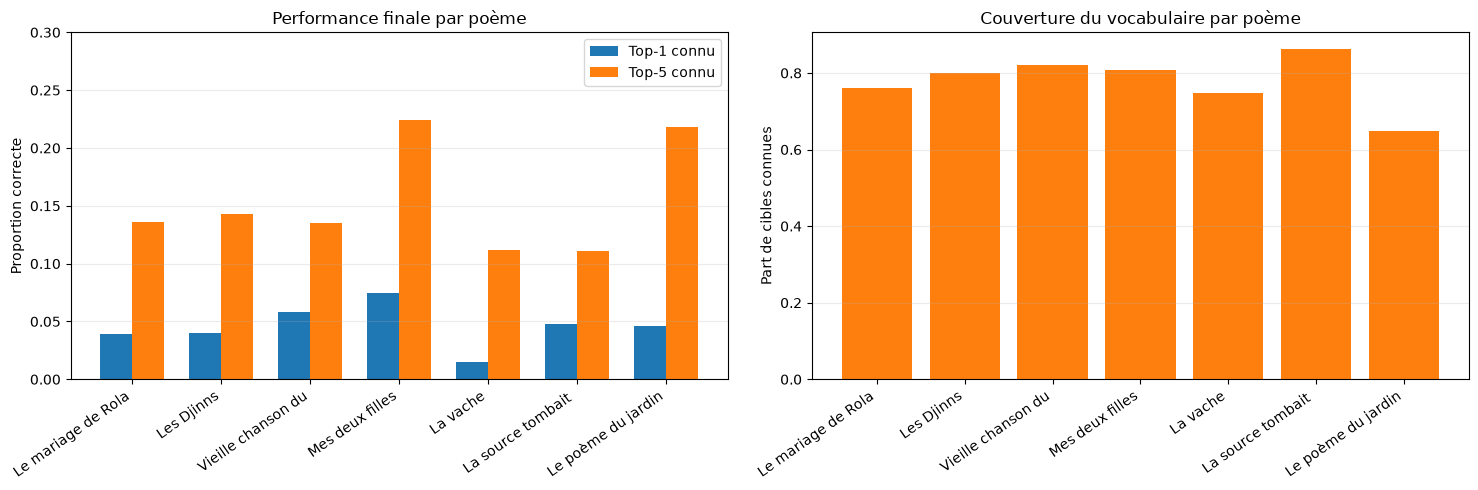


Nouvelle inférence après la passe unique : non
Réentraînement ou adaptation après test  : non
Protocole final verrouillé               : oui


In [30]:
from sklearn.metrics import precision_recall_fscore_support

assert EVALUATION_TEST_EFFECTUEE is True
assert _nombre_passes_inference_test == 1

def resumer_groupe_test(nom, masque):
    effectif = int(np.sum(masque))
    if effectif == 0:
        return {
            "groupe": nom,
            "effectif": 0,
            "top_1": np.nan,
            "top_5": np.nan,
            "perte": np.nan,
            "mrr": np.nan,
        }
    return {
        "groupe": nom,
        "effectif": effectif,
        "top_1": float(np.mean(correct_test[masque])),
        "top_5": float(np.mean(presence_cible_top5_test[masque])),
        "perte": float(np.mean(pertes_test_detaillees[masque])),
        "mrr": float(np.mean(1.0 / rangs_cibles_test[masque])),
    }

nombre_pad_contexte_test = np.sum(X_test == ID_PADDING, axis=1)
longueur_reelle_contexte_test = (
    TAILLE_CONTEXTE - nombre_pad_contexte_test
)
nombre_unk_contexte_test = np.sum(
    X_test == ID_HORS_VOCABULAIRE,
    axis=1,
)
masque_contexte_avec_unk_test = nombre_unk_contexte_test > 0
frequence_cible_train_test = frequences_cibles_train[y_test]

groupes_test = [
    resumer_groupe_test(
        "Toutes les cibles connues",
        masque_cible_connue_test,
    ),
    resumer_groupe_test(
        "Connue, contexte sans [UNK]",
        masque_cible_connue_test & ~masque_contexte_avec_unk_test,
    ),
    resumer_groupe_test(
        "Connue, contexte avec [UNK]",
        masque_cible_connue_test & masque_contexte_avec_unk_test,
    ),
    resumer_groupe_test("Cible [UNK]", masque_cible_unk_test),
]

for nombre_mots in range(TAILLE_CONTEXTE + 1):
    groupes_test.append(resumer_groupe_test(
        f"Cible connue, contexte de {nombre_mots} mot(s)",
        masque_cible_connue_test
        & (longueur_reelle_contexte_test == nombre_mots),
    ))

groupes_frequence = [
    ("Fréquence train = 1", frequence_cible_train_test == 1),
    ("Fréquence train de 2 à 5", (
        frequence_cible_train_test >= 2
    ) & (frequence_cible_train_test <= 5)),
    ("Fréquence train de 6 à 20", (
        frequence_cible_train_test >= 6
    ) & (frequence_cible_train_test <= 20)),
    ("Fréquence train > 20", frequence_cible_train_test > 20),
]
for nom, masque_frequence in groupes_frequence:
    groupes_test.append(resumer_groupe_test(
        nom,
        masque_cible_connue_test & masque_frequence,
    ))

print("Analyse finale par difficulté :")
print(
    f"{'Groupe':<43} {'N':>6} {'Top-1':>9} "
    f"{'Top-5':>9} {'Perte':>9} {'MRR':>9}"
)
for groupe in groupes_test:
    if groupe["effectif"] == 0:
        print(
            f"{groupe['groupe']:<43} {0:>6} "
            f"{'—':>9} {'—':>9} {'—':>9} {'—':>9}"
        )
    else:
        print(
            f"{groupe['groupe']:<43} {groupe['effectif']:>6} "
            f"{groupe['top_1']:>8.2%} {groupe['top_5']:>8.2%} "
            f"{groupe['perte']:>9.4f} {groupe['mrr']:>9.4f}"
        )

mesures_par_poeme_test = []
print()
print("Résultats par poème de test :")
print(
    f"{'Poème':<29} {'N':>6} {'Connus':>7} "
    f"{'Couverture':>11} {'Top-1':>9} {'Top-5':>9} {'Perte':>9}"
)
for poeme in poemes_test:
    masque_poeme = provenance_test == poeme["numero"]
    masque_poeme_connu = masque_poeme & masque_cible_connue_test
    n_total = int(np.sum(masque_poeme))
    n_connu = int(np.sum(masque_poeme_connu))
    assert n_total > 0 and n_connu > 0
    mesure = {
        "numero": poeme["numero"],
        "titre": poeme["titre"],
        "n": n_total,
        "connus": n_connu,
        "couverture": n_connu / n_total,
        "top_1": float(np.mean(correct_test[masque_poeme_connu])),
        "top_5": float(np.mean(
            presence_cible_top5_test[masque_poeme_connu]
        )),
        "perte": float(np.mean(
            pertes_test_detaillees[masque_poeme_connu]
        )),
        "mrr": float(np.mean(
            1.0 / rangs_cibles_test[masque_poeme_connu]
        )),
    }
    mesures_par_poeme_test.append(mesure)
    print(
        f"{poeme['titre'][:28]:<29} {n_total:>6} {n_connu:>7} "
        f"{mesure['couverture']:>10.2%} {mesure['top_1']:>8.2%} "
        f"{mesure['top_5']:>8.2%} {mesure['perte']:>9.4f}"
    )

accuracy_macro_poemes_test = float(np.mean([
    mesure["top_1"] for mesure in mesures_par_poeme_test
]))
top5_macro_poemes_test = float(np.mean([
    mesure["top_5"] for mesure in mesures_par_poeme_test
]))
print()
print("Top-1 macro entre poèmes :", f"{accuracy_macro_poemes_test:.2%}")
print("Top-5 macro entre poèmes :", f"{top5_macro_poemes_test:.2%}")

y_connus_test = y_test[masque_cible_connue_test]
pred_connus_test = predictions_test_top1[masque_cible_connue_test]
classes_connues_test = np.unique(y_connus_test)
(
    precisions_classes_test,
    rappels_classes_test,
    f1_classes_test,
    supports_classes_test,
) = precision_recall_fscore_support(
    y_connus_test,
    pred_connus_test,
    labels=classes_connues_test,
    zero_division=0,
)

macro_precision_test = float(np.mean(precisions_classes_test))
macro_rappel_test = float(np.mean(rappels_classes_test))
macro_f1_test = float(np.mean(f1_classes_test))
weighted_precision_test = float(np.average(
    precisions_classes_test,
    weights=supports_classes_test,
))
weighted_rappel_test = float(np.average(
    rappels_classes_test,
    weights=supports_classes_test,
))
weighted_f1_test = float(np.average(
    f1_classes_test,
    weights=supports_classes_test,
))
np.testing.assert_allclose(
    weighted_rappel_test,
    accuracy_connus_test,
    atol=1e-12,
)
resultats_test_finaux.update({
    "nombre_classes_connues_presentes": len(classes_connues_test),
    "macro_precision": macro_precision_test,
    "macro_rappel": macro_rappel_test,
    "macro_f1": macro_f1_test,
    "weighted_precision": weighted_precision_test,
    "weighted_rappel": weighted_rappel_test,
    "weighted_f1": weighted_f1_test,
    "accuracy_macro_poemes": accuracy_macro_poemes_test,
    "top5_macro_poemes": top5_macro_poemes_test,
})

print()
print("Métriques par classe sur les cibles connues :")
print("Classes présentes  :", len(classes_connues_test))
print("Macro-précision    :", f"{macro_precision_test:.2%}")
print("Macro-rappel       :", f"{macro_rappel_test:.2%}")
print("Macro-F1           :", f"{macro_f1_test:.2%}")
print("Weighted-précision :", f"{weighted_precision_test:.2%}")
print("Weighted-rappel    :", f"{weighted_rappel_test:.2%}")
print("Weighted-F1        :", f"{weighted_f1_test:.2%}")

ordre_support_test = np.argsort(
    -supports_classes_test,
    kind="stable",
)[:12]
print()
print("Douze cibles connues les plus représentées :")
print(
    f"{'Mot':<18} {'Support':>8} {'Précision':>11} "
    f"{'Rappel':>9} {'F1':>9}"
)
for indice in ordre_support_test:
    identifiant = int(classes_connues_test[indice])
    print(
        f"{token_affichable(identifiant)[:17]:<18} "
        f"{int(supports_classes_test[indice]):>8} "
        f"{precisions_classes_test[indice]:>10.2%} "
        f"{rappels_classes_test[indice]:>8.2%} "
        f"{f1_classes_test[indice]:>8.2%}"
    )

indices_erreurs_connues_test = np.flatnonzero(
    masque_cible_connue_test & ~correct_test
)
paires_erreurs = np.column_stack((
    y_test[indices_erreurs_connues_test],
    predictions_test_top1[indices_erreurs_connues_test],
))
paires_uniques, comptes_paires = np.unique(
    paires_erreurs,
    axis=0,
    return_counts=True,
)
ordre_paires = np.argsort(-comptes_paires, kind="stable")[:10]
print()
print("Dix couples d'erreur les plus fréquents :")
for indice in ordre_paires:
    vraie, predite = paires_uniques[indice]
    print(
        f"  {token_affichable(vraie)} → "
        f"{token_affichable(predite)} : {int(comptes_paires[indice])}"
    )

ordre_erreurs_confiantes = indices_erreurs_connues_test[
    np.argsort(
        -confiance_top1_test[indices_erreurs_connues_test],
        kind="stable",
    )
]
indices_erreurs_affichees = ordre_erreurs_confiantes[:5]
titres_test_par_numero = {
    poeme["numero"]: poeme["titre"] for poeme in poemes_test
}
print()
print("Cinq erreurs connues de plus forte confiance :")
for indice in indices_erreurs_affichees:
    contexte = " ".join(
        token_affichable(id_token) for id_token in X_test[indice]
    )
    propositions = " | ".join(
        f"{token_affichable(id_token)} ({probabilite:.2%})"
        for id_token, probabilite in zip(
            ids_top5_test[indice],
            probabilites_top5_test[indice],
        )
    )
    numero_poeme = int(provenance_test[indice])
    print()
    print(
        f"Poème {numero_poeme} — "
        f"{titres_test_par_numero[numero_poeme]}"
    )
    print("  contexte    :", contexte)
    print("  vraie cible :", token_affichable(y_test[indice]))
    print(
        "  prédiction  :",
        token_affichable(predictions_test_top1[indice]),
        f"({confiance_top1_test[indice]:.2%})",
    )
    print("  top 5       :", propositions)

noms_poemes_test = [
    mesure["titre"][:18] for mesure in mesures_par_poeme_test
]
positions_poemes = np.arange(len(mesures_par_poeme_test))
largeur_barre = 0.36
figure, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(
    positions_poemes - largeur_barre / 2,
    [m["top_1"] for m in mesures_par_poeme_test],
    width=largeur_barre,
    label="Top-1 connu",
)
axes[0].bar(
    positions_poemes + largeur_barre / 2,
    [m["top_5"] for m in mesures_par_poeme_test],
    width=largeur_barre,
    label="Top-5 connu",
)
axes[0].set_title("Performance finale par poème")
axes[0].set_ylabel("Proportion correcte")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(
    positions_poemes,
    [m["couverture"] for m in mesures_par_poeme_test],
    color="tab:orange",
)
axes[1].set_title("Couverture du vocabulaire par poème")
axes[1].set_ylabel("Part de cibles connues")
axes[1].grid(axis="y", alpha=0.25)

for axe in axes:
    axe.set_xticks(positions_poemes)
    axe.set_xticklabels(noms_poemes_test, rotation=35, ha="right")
    axe.set_ylim(0, max(0.3, axe.get_ylim()[1]))
figure.tight_layout()
plt.show()

for avant, apres in zip(poids_avant_test, modele_rnn.weights):
    np.testing.assert_array_equal(avant, apres.numpy())
for avant, apres in zip(
    etat_optimiseur_avant_test,
    modele_rnn.optimizer.variables,
):
    np.testing.assert_array_equal(avant, apres.numpy())
assert int(modele_rnn.optimizer.iterations.numpy()) == iterations_avant_test
assert tuple(vectoriseur.get_vocabulary()) == vocabulaire_avant_test
assert hashlib.sha256(
    CHEMIN_MEILLEURS_POIDS.read_bytes()
).hexdigest() == empreinte_checkpoint_avant_test
PROTOCOLE_TEST_VERROUILLE = True

print()
print("Nouvelle inférence après la passe unique : non")
print("Réentraînement ou adaptation après test  : non")
print("Protocole final verrouillé               : oui")


## Bilan de l'étape 9 — évaluation finale

Le checkpoint de l'époque 6 a été évalué sur les sept poèmes de test au moyen d'un unique appel du RNN. Les **2 327 vecteurs de 3 203 logits** ont été conservés, puis toutes les métriques et analyses ont été calculées sans nouvelle inférence. Les poids, toutes les variables d'Adam, le vocabulaire et le fichier de checkpoint sont restés strictement inchangés.

Parmi les 2 327 cibles, **1 795 sont connues** et **532 deviennent [UNK]**, soit une couverture de **77,14 %**, contre 80,70 % en validation. Sur les mots connus, le modèle atteint **4,12 %** en top-1, **14,21 %** en top-5 et un MRR de **0,1006**. Le top-1 et le top-5 dépassent la validation de 0,45 et 1,52 point, mais la perte connue augmente de 6,2977 à **6,4305**. Ce n'est pas contradictoire : quelques rangs deviennent meilleurs alors que la probabilité moyenne attribuée aux vraies cibles diminue.

Comme le modèle ne prédit jamais [UNK], l'accuracy de cet identifiant vaut 0 %. L'accuracy globale retrouve donc :

$$
A_{\mathrm{global}}
=0{,}7714\times4{,}12\%+0{,}2286\times0\%
\approx3{,}18\%.
$$

La perte vaut **7,5190** globalement, **6,4305** sur les mots connus et **11,1915** sur [UNK]. Les perplexités correspondantes sont 1 842,64, 620,49 et 72 508,40. La valeur énorme pour [UNK] est cohérente avec l'absence de cible [UNK] pendant l'entraînement ; elle augmente fortement la perplexité globale et ne signifie pas que le modèle hésite entre 72 508 mots réels.

### Le constat décisif : les baselines font mieux

Toujours prédire « et » obtient **5,52 %** sur les cibles connues, contre 4,12 % pour le RNN. Les cinq mots d'entraînement les plus fréquents atteignent **17,94 %** en top-5, contre 14,21 %. La distribution unigramme lissée obtient aussi une perte plus faible : 7,0867 contre 7,5190 globalement, et 6,3483 contre 6,4305 sur les mots connus. Le RNN fait mieux que le modèle uniforme, dont la perte vaut 8,0718, mais il ne dépasse aucune de nos baselines de fréquence sur le test. Il a appris que certains mots sont plus probables que d'autres, sans exploiter suffisamment le contexte de trois mots pour généraliser à de nouveaux poèmes.

La fréquence explique une grande partie de l'échec. Les 942 cibles apparues plus de 20 fois pendant l'entraînement atteignent 7,75 % en top-1 et 26,54 % en top-5. Le top-1 est nul pour les mots vus une à cinq fois, puis atteint seulement 0,32 % entre 6 et 20 occurrences. Le modèle ne produit que **65 identifiants différents**, alors que le test contient **597 classes connues distinctes**. Il se concentre surtout sur des mots fréquents comme « et » et « la ».

Cette concentration conduit à un macro-F1 de **0,10 %** et à un F1 pondéré de **1,44 %**. Le rappel pondéré vaut 4,12 %, exactement comme l'accuracy connue dans cette classification multiclasses à une seule cible. Les erreurs les plus courantes — « et → la », « de → et » ou « le → la » — concernent principalement des mots grammaticaux. Même les erreurs dites les plus confiantes restent proches de 16 %, signe que le réseau demeure incertain.

Les résultats diffèrent descriptivement entre poèmes : le top-1 connu va de **1,49 % à 7,46 %**, le top-5 de **11,11 % à 22,39 %** et la couverture de **64,93 % à 86,30 %**. Les moyennes macro entre poèmes atteignent 4,58 % et 15,43 %, légèrement au-dessus des moyennes par fenêtre, mais les effectifs connus vont de 63 à 912 ; ces écarts ne permettent pas d'établir un classement fiable. De même, le meilleur score apparent lorsque le contexte contient [UNK] ne prouve pas que ce marqueur aide : les groupes contiennent des mots, des fréquences et des poèmes différents.

### Conclusion finale

Le SimpleRNN apprend le corpus d'entraînement mais **généralise mal** : il surapprend, ignore pratiquement les mots rares et ne bat pas une simple baseline de fréquences. Une accuracy exacte faible doit être nuancée parce que plusieurs continuations poétiques peuvent être plausibles, mais cette nuance ne suffit pas à effacer l'échec face aux baselines.

À partir de maintenant, **aucun réglage de ce SimpleRNN n'est autorisé à partir du test**. Toute nouvelle architecture, notamment un LSTM, devra être choisie exclusivement avec entraînement et validation. Puisque le test du SimpleRNN est désormais connu, une future comparaison sur ce même test devra être présentée comme une expérience supplémentaire et non comme une nouvelle sélection totalement aveugle.


## 28. Comparer équitablement SimpleRNN et LSTM

### 28.1 Ce que nous cherchons à comprendre

Le SimpleRNN vient d'être évalué sur le test. Nous allons construire une variante LSTM pour étudier si une mémoire contrôlée aide à prédire le mot suivant. Une comparaison n'est utile que si elle change le moins de choses possible.

Nous conservons donc :

- les mêmes 34 poèmes d'entraînement et les mêmes 7 poèmes de validation ;
- le même vocabulaire appris uniquement sur l'entraînement, de taille $V=3\,203$ ;
- les mêmes fenêtres de trois mots, sans franchir les frontières entre poèmes ;
- les mêmes lots de 64 exemples ;
- une dimension d'embedding $D=64$ et un état récurrent de taille $H=64$ ;
- la même couche Dense de $3\,203$ logits ;
- la même perte, Adam avec $\eta=10^{-3}$, l'écrêtage global à 1 et les mêmes métriques.

Le seul changement conceptuel est :

$$
\mathrm{SimpleRNN}(64)
\quad\longrightarrow\quad
\mathrm{LSTM}(64).
$$

Cela isole mieux l'effet du type de cellule récurrente. Ce n'est toutefois **pas une comparaison à nombre de paramètres égal** : une LSTM possède quatre blocs de paramètres et sera donc un peu plus grande.

### 28.2 Protocole figé avant l'entraînement

Nous préenregistrons une seule expérience LSTM :

- maximum de 40 époques ;
- sélection exclusive sur val_accuracy_mots_connus ;
- patience de 8 époques et min_delta égal à 0 ;
- restauration des meilleurs poids ;
- aucun transfert de poids depuis le SimpleRNN ;
- aucune décision fondée sur le test.

Le test du SimpleRNN ayant déjà été observé, une future comparaison des deux modèles sur ce même test ne pourra plus être présentée comme entièrement aveugle. Si nous évaluons plus tard le LSTM sur ce test, le résultat sera clairement qualifié de **comparaison exploratoire post-hoc**. Une comparaison confirmatoire exigerait un nouveau jeu de test intact ou une validation croisée imbriquée.

Dans cette étape, nous allons seulement construire, compiler et contrôler le LSTM sur **un lot de validation**. Nous ne l'entraînons pas et nous ne réalisons aucune nouvelle inférence sur le test.

## 29. Comprendre mathématiquement une cellule LSTM

### 29.1 Pourquoi ajouter une mémoire ?

Dans un SimpleRNN, l'état est entièrement réécrit à chaque pas :

$$
\mathbf{h}_t
=
\tanh\!\left(
W\mathbf{e}_t
+
U\mathbf{h}_{t-1}
+
\mathbf{b}
\right).
$$

Lorsque de nombreux pas sont enchaînés, le gradient traverse à répétition la dérivée de tanh et la matrice récurrente $U$. Le produit de nombreux facteurs peut devenir très petit, ce qui donne le **gradient évanescent**, ou très grand, ce qui donne le **gradient explosif**.

Une LSTM, pour Long Short-Term Memory, sépare deux objets :

- $\mathbf{c}_t\in\mathbb{R}^{H}$ : l'état de cellule, qui joue le rôle de mémoire ;
- $\mathbf{h}_t\in\mathbb{R}^{H}$ : l'état caché, transmis à la sortie et au pas suivant.

À chaque pas $t$, elle reçoit le vecteur du mot courant $\mathbf{e}_t\in\mathbb{R}^{D}$ et l'état caché précédent $\mathbf{h}_{t-1}$.

### 29.2 Les portes et la mise à jour

La fonction sigmoïde vaut :

$$
\sigma(a)=\frac{1}{1+\exp(-a)}.
$$

Elle produit un nombre entre 0 et 1. Les portes sont donc des **coefficients continus**, et non des interrupteurs strictement binaires.

**Porte d'oubli :**

$$
\mathbf{f}_t
=
\sigma\!\left(
W_f\mathbf{e}_t
+
U_f\mathbf{h}_{t-1}
+
\mathbf{b}_f
\right).
$$

Une valeur proche de 0 efface presque l'information correspondante ; une valeur proche de 1 la conserve presque entièrement.

**Porte d'entrée :**

$$
\mathbf{i}_t
=
\sigma\!\left(
W_i\mathbf{e}_t
+
U_i\mathbf{h}_{t-1}
+
\mathbf{b}_i
\right).
$$

Elle règle la quantité de nouvelle information à écrire.

**Contenu candidat :**

$$
\widetilde{\mathbf{c}}_t
=
\tanh\!\left(
W_c\mathbf{e}_t
+
U_c\mathbf{h}_{t-1}
+
\mathbf{b}_c
\right).
$$

Ce vecteur propose de nouvelles valeurs comprises entre $-1$ et $1$.

**Mise à jour de la mémoire :**

$$
\mathbf{c}_t
=
\mathbf{f}_t\odot\mathbf{c}_{t-1}
+
\mathbf{i}_t\odot\widetilde{\mathbf{c}}_t,
$$

où $\odot$ désigne la multiplication composante par composante. Le premier terme conserve une partie du passé ; le second ajoute une partie du candidat.

**Porte de sortie et état caché :**

$$
\mathbf{o}_t
=
\sigma\!\left(
W_o\mathbf{e}_t
+
U_o\mathbf{h}_{t-1}
+
\mathbf{b}_o
\right),
$$

$$
\mathbf{h}_t
=
\mathbf{o}_t\odot\tanh(\mathbf{c}_t).
$$

La porte de sortie choisit quelle partie de la mémoire devient visible dans l'état caché.

### 29.3 Pourquoi le gradient circule mieux

En ne considérant que le chemin direct entre deux états de cellule :

$$
\frac{\partial\mathbf{c}_t}
{\partial\mathbf{c}_{t-1}}
\approx
\operatorname{diag}(\mathbf{f}_t).
$$

Si une composante de la porte d'oubli reste proche de 1, le gradient peut traverser plusieurs pas sans être systématiquement écrasé par tanh. Le LSTM **réduit** ainsi le problème du gradient évanescent, sans garantir sa disparition. L'écrêtage global reste utile contre les gradients trop grands.

Dans Keras, unit_forget_bias=True ajoute initialement 1 au biais de la porte d'oubli. Comme $\sigma(1)\approx0{,}731$, cette initialisation encourage au début une conservation modérée de la mémoire ; cette valeur reste ensuite apprenable.

### 29.4 Formes et masque du padding

Pour un lot de $B$ contextes de trois mots :

$$
(B,3)
\xrightarrow{\mathrm{Embedding}}
(B,3,64)
\xrightarrow{\mathrm{LSTM}}
(B,64).
$$

Avec return_sequences=False, seule la sortie finale est renvoyée. Le masque produit par Embedding(mask_zero=True) indique que l'identifiant 0 est du padding. Un pas masqué ne doit pas apporter une fausse information : les états précédents sont conservés.

### 29.5 Nombre de paramètres

Chacune des quatre parties — oubli, entrée, candidat et sortie — possède une matrice d'entrée $D\times H$, une matrice récurrente $H\times H$ et un biais de taille $H$. Ainsi :

$$
N_{\mathrm{LSTM}}
=
4(DH+H^2+H)
=
4H(D+H+1).
$$

Avec $D=64$ et $H=64$ :

$$
N_{\mathrm{LSTM}}
=
4\times64\times(64+64+1)
=
33\,024.
$$

Le modèle complet contient donc :

$$
N_{\mathrm{Embedding}}=3\,203\times64=204\,992,
$$

$$
N_{\mathrm{Dense}}=(64+1)\times3\,203=208\,195,
$$

$$
N_{\mathrm{total,LSTM}}
=
204\,992+33\,024+208\,195
=
446\,211.
$$

Le SimpleRNN complet contenait 421 443 paramètres. Le LSTM en ajoute 24 768, soit environ 5,88 % du modèle complet. Sa seule couche récurrente possède exactement quatre fois plus de paramètres que la couche SimpleRNN : 33 024 contre 8 256.

### 29.6 Limite essentielle de notre expérience

Nos fenêtres ne contiennent que **trois mots** et stateful=False réinitialise les états entre les fenêtres. Le LSTM ne lit donc jamais le poème entier et ne transporte pas sa mémoire d'une fenêtre à la suivante. Son avantage théorique sur de longues dépendances est peu sollicité ici ; sa capacité supplémentaire peut aider, ne rien changer ou favoriser le surapprentissage. Seule la validation permettra de le constater.

## 30. Construire un LSTM neuf sans toucher au SimpleRNN

Nous photographions d'abord les poids du SimpleRNN, l'état de son optimiseur, son vocabulaire et son checkpoint. Cela permettra de vérifier après la construction que rien n'a été modifié.

Le nouveau modèle reçoit les mêmes identifiants et crée ses **propres** couches Embedding, LSTM et Dense. Aucun poids n'est copié. La graine est replacée à 42 juste avant la construction pour rendre l'initialisation reproductible.

Les sorties de la couche Dense restent des logits : aucune activation softmax n'est ajoutée au modèle.

In [31]:
# Le test du SimpleRNN a déjà été vu une fois.
# Nous enregistrons son état, sans réutiliser ses données ni ses logits.
assert EVALUATION_TEST_EFFECTUEE is True
assert PROTOCOLE_TEST_VERROUILLE is True
assert _nombre_passes_inference_test == 1
assert "modele_lstm" not in globals()
assert "historique_lstm" not in globals()
assert "logits_test_lstm" not in globals()

nombre_passes_test_avant_lstm = _nombre_passes_inference_test
poids_rnn_avant_lstm = [
    poids.numpy().copy() for poids in modele_rnn.weights
]
etat_adam_rnn_avant_lstm = [
    variable.numpy().copy()
    for variable in modele_rnn.optimizer.variables
]
iterations_rnn_avant_lstm = int(
    modele_rnn.optimizer.iterations.numpy()
)
vocabulaire_avant_lstm = tuple(
    vectoriseur.get_vocabulary()
)
empreinte_checkpoint_avant_lstm = hashlib.sha256(
    CHEMIN_MEILLEURS_POIDS.read_bytes()
).hexdigest()

assert taille_vocabulaire == 3203
assert DIMENSION_EMBEDDING == 64
assert NOMBRE_UNITES_RNN == 64

NOMBRE_UNITES_LSTM = NOMBRE_UNITES_RNN
PARAMETRES_EMBEDDING_LSTM = (
    taille_vocabulaire * DIMENSION_EMBEDDING
)
PARAMETRES_LSTM = (
    4
    * NOMBRE_UNITES_LSTM
    * (
        DIMENSION_EMBEDDING
        + NOMBRE_UNITES_LSTM
        + 1
    )
)
PARAMETRES_DENSE_LSTM = (
    (NOMBRE_UNITES_LSTM + 1) * taille_vocabulaire
)
PARAMETRES_TOTAL_LSTM = (
    PARAMETRES_EMBEDDING_LSTM
    + PARAMETRES_LSTM
    + PARAMETRES_DENSE_LSTM
)

assert PARAMETRES_EMBEDDING_LSTM == 204992
assert PARAMETRES_LSTM == 33024
assert PARAMETRES_DENSE_LSTM == 208195
assert PARAMETRES_TOTAL_LSTM == 446211

PROTOCOLE_LSTM_FIGE = {
    "graine": SEED,
    "taille_contexte": TAILLE_CONTEXTE,
    "taille_lot": TAILLE_LOT,
    "dimension_embedding": DIMENSION_EMBEDDING,
    "unites_lstm": NOMBRE_UNITES_LSTM,
    "learning_rate": 1e-3,
    "global_clipnorm": 1.0,
    "moniteur": "val_accuracy_mots_connus",
    "mode": "max",
    "epoques_max": 40,
    "patience": 8,
    "min_delta": 0.0,
}

# Modèle entièrement neuf : aucun poids du SimpleRNN n'est transféré.
tf.keras.utils.set_random_seed(SEED)

entree_contexte_lstm = tf.keras.Input(
    shape=(TAILLE_CONTEXTE,),
    dtype=tf.int32,
    name="identifiants_contexte_lstm",
)
representations_lstm = tf.keras.layers.Embedding(
    input_dim=taille_vocabulaire,
    output_dim=DIMENSION_EMBEDDING,
    mask_zero=True,
    name="embedding_lstm",
)(entree_contexte_lstm)
etat_final_lstm = tf.keras.layers.LSTM(
    units=NOMBRE_UNITES_LSTM,
    activation="tanh",
    recurrent_activation="sigmoid",
    use_bias=True,
    unit_forget_bias=True,
    dropout=0.0,
    recurrent_dropout=0.0,
    return_sequences=False,
    stateful=False,
    name="lstm",
)(representations_lstm)
logits_sortie_lstm = tf.keras.layers.Dense(
    units=taille_vocabulaire,
    activation=None,
    name="logits_lstm",
)(etat_final_lstm)
modele_lstm = tf.keras.Model(
    inputs=entree_contexte_lstm,
    outputs=logits_sortie_lstm,
    name="lstm_victor_hugo",
)

assert modele_lstm.input_shape == (None, TAILLE_CONTEXTE)
assert modele_lstm.output_shape == (None, taille_vocabulaire)
assert modele_lstm.get_layer("embedding_lstm").mask_zero is True
assert (
    modele_lstm.get_layer("embedding_lstm").count_params()
    == PARAMETRES_EMBEDDING_LSTM
)
assert modele_lstm.get_layer("lstm").count_params() == PARAMETRES_LSTM
assert (
    modele_lstm.get_layer("logits_lstm").count_params()
    == PARAMETRES_DENSE_LSTM
)
assert (
    modele_lstm.get_layer("logits_lstm").activation.__name__
    == "linear"
)
assert modele_lstm.count_params() == PARAMETRES_TOTAL_LSTM

modele_lstm.summary()

Model: "lstm_victor_hugo"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ identifiants_conte… │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_lstm      │ (None, 3, 64)     │    204,992 │ identifiants_con… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 3)         │          0 │ identifiants_con… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     33,024 │ embedding_lstm[0… │
│                     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ logits_lstm (Dense) │ (None, 3203)      │    208,195 │ lstm[0][0]        │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 446,211 (1.70 MB)

 Trainable params: 446,211 (1.70 MB)

 Non-trainable params: 0 (0.00 B)

## 31. Compiler et effectuer un contrôle sans apprentissage

Nous compilons le LSTM avec exactement la même fonction objectif que le SimpleRNN :

$$
\mathcal{L}
=
-\frac{1}{B'}
\sum_{i=1}^{B'}
\log p_{i,y_i},
$$

où les probabilités sont calculées de façon stable à partir des logits. SparseCategoricalCrossentropy(from_logits=True) attend directement les identifiants entiers des mots cibles.

Adam et l'écrêtage global utilisent les mêmes hyperparamètres. Nous créons toutefois un **nouvel objet optimiseur** : partager l'optimiseur du SimpleRNN mélangerait les variables et les moments d'Adam des deux modèles.

Les trois métriques sont également recréées : accuracy_globale_ids, top_5_accuracy_globale_ids et accuracy_mots_connus.

Compiler ne calcule aucun gradient. Ensuite, une unique passe en mode training=False sur le premier lot de validation servira seulement à contrôler la forme $(64,3\,203)$ des logits, leur finitude, la somme à 1 après softmax, l'identité des argmax, la cohérence de l'entropie croisée et l'absence de modification des poids.

Cette perte initiale aléatoire n'est **pas une performance** et ne servira à aucun choix. Aucune donnée de test n'est transmise au LSTM.

In [32]:
fonction_perte_lstm = (
    tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True,
        name="entropie_croisee_sparse_lstm",
    )
)
optimiseur_lstm = tf.keras.optimizers.Adam(
    learning_rate=PROTOCOLE_LSTM_FIGE["learning_rate"],
    global_clipnorm=PROTOCOLE_LSTM_FIGE["global_clipnorm"],
)
metriques_lstm = [
    tf.keras.metrics.SparseCategoricalAccuracy(
        name="accuracy_globale_ids",
    ),
    tf.keras.metrics.SparseTopKCategoricalAccuracy(
        k=5,
        name="top_5_accuracy_globale_ids",
    ),
    AccuracyMotsConnus(),
]
modele_lstm.compile(
    optimizer=optimiseur_lstm,
    loss=fonction_perte_lstm,
    metrics=metriques_lstm,
)

assert modele_lstm.loss.from_logits is True
assert np.isclose(
    float(modele_lstm.optimizer.learning_rate.numpy()),
    1e-3,
)
assert modele_lstm.optimizer.global_clipnorm == 1.0
assert int(modele_lstm.optimizer.iterations.numpy()) == 0
assert [metrique.name for metrique in metriques_lstm] == [
    "accuracy_globale_ids",
    "top_5_accuracy_globale_ids",
    "accuracy_mots_connus",
]
assert modele_lstm.optimizer is not modele_rnn.optimizer

CHEMIN_MEILLEURS_POIDS_LSTM = (
    DOSSIER_ARTEFACTS
    / "lstm_victor_hugo_meilleurs.weights.h5"
)

assert "_nombre_passes_validation_lstm" not in globals()
_nombre_passes_validation_lstm = 0


def inferer_validation_lstm_une_fois(entrees):
    global _nombre_passes_validation_lstm

    assert _nombre_passes_validation_lstm == 0, (
        "Une seule passe de contrôle est autorisée."
    )
    _nombre_passes_validation_lstm += 1
    return modele_lstm(entrees, training=False)


lot_x_validation_lstm, lot_y_validation_lstm = next(
    iter(dataset_validation)
)
np.testing.assert_array_equal(
    lot_x_validation_lstm.numpy(),
    X_validation[:TAILLE_LOT],
)
np.testing.assert_array_equal(
    lot_y_validation_lstm.numpy(),
    y_validation[:TAILLE_LOT],
)

poids_lstm_avant_forward = [
    poids.numpy().copy() for poids in modele_lstm.weights
]
iterations_lstm_avant_forward = int(
    modele_lstm.optimizer.iterations.numpy()
)

logits_validation_lstm = inferer_validation_lstm_une_fois(
    lot_x_validation_lstm
)
probabilites_validation_lstm = tf.nn.softmax(
    logits_validation_lstm,
    axis=-1,
)
perte_validation_lstm_initiale = fonction_perte_lstm(
    lot_y_validation_lstm,
    logits_validation_lstm,
)
pertes_individuelles_lstm = (
    tf.nn.sparse_softmax_cross_entropy_with_logits(
        labels=lot_y_validation_lstm,
        logits=logits_validation_lstm,
    )
)

assert _nombre_passes_validation_lstm == 1
assert logits_validation_lstm.shape == (
    TAILLE_LOT,
    taille_vocabulaire,
)
assert probabilites_validation_lstm.shape == (
    TAILLE_LOT,
    taille_vocabulaire,
)
assert bool(tf.reduce_all(
    tf.math.is_finite(logits_validation_lstm)
))
np.testing.assert_allclose(
    tf.reduce_sum(
        probabilites_validation_lstm,
        axis=1,
    ).numpy(),
    np.ones(TAILLE_LOT),
    rtol=1e-5,
    atol=1e-5,
)
np.testing.assert_array_equal(
    tf.argmax(logits_validation_lstm, axis=1).numpy(),
    tf.argmax(probabilites_validation_lstm, axis=1).numpy(),
)
np.testing.assert_allclose(
    float(perte_validation_lstm_initiale),
    float(tf.reduce_mean(pertes_individuelles_lstm)),
    rtol=1e-6,
)

for avant, apres in zip(
    poids_lstm_avant_forward,
    modele_lstm.weights,
):
    np.testing.assert_array_equal(avant, apres.numpy())
assert int(modele_lstm.optimizer.iterations.numpy()) == 0
assert (
    int(modele_lstm.optimizer.iterations.numpy())
    == iterations_lstm_avant_forward
)

for avant, apres in zip(
    poids_rnn_avant_lstm,
    modele_rnn.weights,
):
    np.testing.assert_array_equal(avant, apres.numpy())
for avant, apres in zip(
    etat_adam_rnn_avant_lstm,
    modele_rnn.optimizer.variables,
):
    np.testing.assert_array_equal(avant, apres.numpy())
assert (
    int(modele_rnn.optimizer.iterations.numpy())
    == iterations_rnn_avant_lstm
)
assert tuple(vectoriseur.get_vocabulary()) == vocabulaire_avant_lstm
assert hashlib.sha256(
    CHEMIN_MEILLEURS_POIDS.read_bytes()
).hexdigest() == empreinte_checkpoint_avant_lstm

assert (
    _nombre_passes_inference_test
    == nombre_passes_test_avant_lstm
    == 1
)

ecart_parametres_lstm = (
    modele_lstm.count_params() - modele_rnn.count_params()
)
pourcentage_parametres_lstm = (
    100 * ecart_parametres_lstm / modele_rnn.count_params()
)

print("Forme du lot de validation :", lot_x_validation_lstm.shape)
print("Forme des logits LSTM      :", logits_validation_lstm.shape)
print(
    "Perte initiale aléatoire   :",
    f"{float(perte_validation_lstm_initiale):.4f}",
)
print("Paramètres SimpleRNN       :", modele_rnn.count_params())
print("Paramètres LSTM            :", modele_lstm.count_params())
print(
    "Écart de paramètres        :",
    ecart_parametres_lstm,
    f"({pourcentage_parametres_lstm:.2f} %)",
)
print("Passes de contrôle val.    :", _nombre_passes_validation_lstm)
print(
    "Mises à jour Adam LSTM     :",
    int(modele_lstm.optimizer.iterations.numpy()),
)
print("Nouvelle passe sur le test : non")
print("Entraînement LSTM effectué : non")

Forme du lot de validation : (64, 3)
Forme des logits LSTM      : (64, 3203)
Perte initiale aléatoire   : 8.0714
Paramètres SimpleRNN       : 421443
Paramètres LSTM            : 446211
Écart de paramètres        : 24768 (5.88 %)
Passes de contrôle val.    : 1
Mises à jour Adam LSTM     : 0
Nouvelle passe sur le test : non
Entraînement LSTM effectué : non


## Bilan de l'étape 10 — LSTM construit et compilé

Nous avons remplacé uniquement la cellule SimpleRNN par une cellule LSTM de même largeur :

$$
\mathrm{Embedding}(3\,203,64)
\longrightarrow
\mathrm{LSTM}(64)
\longrightarrow
\mathrm{Dense}(3\,203\ \mathrm{logits}).
$$

Le LSTM complet contient **446 211 paramètres**, contre 421 443 pour le SimpleRNN : 24 768 paramètres supplémentaires, soit environ 5,88 %. Cette différence vient des quatre blocs internes de la LSTM.

Le modèle utilise sa propre initialisation, sa propre fonction de perte, son propre optimiseur Adam et ses propres métriques. Un seul lot de validation a contrôlé les dimensions et les calculs, avec zéro mise à jour d'Adam. Les poids, l'optimiseur, le vocabulaire et le checkpoint du SimpleRNN sont restés inchangés. Aucune nouvelle inférence de test n'a été effectuée et le LSTM n'est pas encore entraîné.

La limite principale reste le contexte de trois mots : cette expérience mesure surtout l'effet d'une cellule plus riche sur une très courte séquence, pas sa capacité à mémoriser un poème entier.

**Prochaine étape :** entraîner le LSTM sur les mêmes données avec le protocole déjà figé, sauvegarder les meilleurs poids, puis comparer les courbes et la meilleure validation au SimpleRNN — toujours sans rouvrir le test.

## 32. Entraîner le LSTM avec le protocole figé

### 32.1 Une mise à jour des poids

Le modèle est maintenant construit : nous ne changeons plus son architecture ni ses hyperparamètres. Pour un lot $B_t$, la rétropropagation à travers le temps calcule le gradient de l'entropie croisée :

$$
\mathbf{g}_t
=
\nabla_{\theta}
\left[
-\frac{1}{|B_t|}
\sum_{i\in B_t}
\log p_{\theta}(y_i\mid x_i)
\right].
$$

Avant Adam, la norme globale est écrêtée au seuil $c=1$ :

$$
\widetilde{\mathbf{g}}_t
=
\mathbf{g}_t
\min\left(
1,
\frac{1}{\lVert\mathbf{g}_t\rVert_2}
\right).
$$

Cet écrêtage conserve la direction du gradient et réduit seulement sa longueur lorsqu'elle dépasse 1. Adam utilise ensuite ses moyennes mobiles du gradient et de son carré pour mettre à jour les paramètres. Une époque correspond ici à 176 mises à jour, une par lot d'entraînement.

Après chaque époque, Keras parcourt les 40 lots de validation avec training=False. Aucun gradient n'est calculé et aucun poids n'est modifié pendant cette phase.

### 32.2 Arrêt anticipé et checkpoint

Le score surveillé est :

$$
a_e
=
A_{\mathrm{connus,val}}^{(e)}.
$$

La meilleure époque est définie avant l'entraînement par :

$$
e^*
=
\operatorname*{arg\,max}_{1\leq e\leq E} a_e.
$$

ModelCheckpoint écrit les poids chaque fois que $a_e$ dépasse strictement son meilleur niveau précédent. EarlyStopping attend huit époques consécutives sans amélioration stricte, arrête l'apprentissage, puis restaure en mémoire les poids de $e^*$.

Le dernier point des courbes représente donc la dernière époque exécutée, tandis que le modèle conservé correspond à $e^*$. Ces deux états ne doivent pas être confondus.

Nous surveillons l'accuracy sur les mots connus plutôt que la perte globale, car 488 cibles de validation sont [UNK] alors qu'aucune cible d'entraînement ne l'est. La perte globale restera affichée, mais elle mélange deux phénomènes : la généralisation sur les mots représentables et la pénalisation structurelle des cibles [UNK].

### 32.3 Repartir d'un pipeline équitable

Le pipeline d'entraînement utilise reshuffle_each_iteration=True. L'objet employé par le SimpleRNN a déjà été parcouru ; le réutiliser ferait continuer sa suite de permutations. Nous recréons donc un pipeline LSTM avec la même fonction et la même graine.

Avant son entraînement, le SimpleRNN avait consommé exactement un premier lot pour contrôler le mélange. Nous effectuons le même contrôle sur le nouveau pipeline LSTM et vérifions que ce lot est identique. Le fit commencera ainsi au même rang dans la suite déterministe des mélanges. La validation, elle, n'est jamais mélangée.

Aucun objet de test n'est transmis au LSTM.

In [33]:
EPOQUES_MAX_LSTM = PROTOCOLE_LSTM_FIGE["epoques_max"]
PATIENCE_LSTM = PROTOCOLE_LSTM_FIGE["patience"]
MONITEUR_LSTM = PROTOCOLE_LSTM_FIGE["moniteur"]

assert EPOQUES_MAX_LSTM == EPOQUES_MAX == 40
assert PATIENCE_LSTM == PATIENCE == 8
assert MONITEUR_LSTM == MONITEUR == "val_accuracy_mots_connus"
assert PROTOCOLE_LSTM_FIGE["mode"] == "max"
assert PROTOCOLE_LSTM_FIGE["min_delta"] == 0.0
assert CHEMIN_MEILLEURS_POIDS_LSTM != CHEMIN_MEILLEURS_POIDS
assert int(modele_lstm.optimizer.iterations.numpy()) == 0
assert "historique_lstm" not in globals()

assert EVALUATION_TEST_EFFECTUEE is True
assert PROTOCOLE_TEST_VERROUILLE is True
assert (
    _nombre_passes_inference_test
    == nombre_passes_test_avant_lstm
    == 1
)
assert "logits_test_lstm" not in globals()

# Photographie du SimpleRNN avant tout apprentissage du LSTM.
poids_rnn_avant_entrainement_lstm = [
    poids.numpy().copy() for poids in modele_rnn.weights
]
etat_adam_rnn_avant_entrainement_lstm = [
    variable.numpy().copy()
    for variable in modele_rnn.optimizer.variables
]
iterations_rnn_avant_entrainement_lstm = int(
    modele_rnn.optimizer.iterations.numpy()
)
vocabulaire_avant_entrainement_lstm = tuple(
    vectoriseur.get_vocabulary()
)
empreinte_checkpoint_rnn_avant_entrainement_lstm = (
    hashlib.sha256(
        CHEMIN_MEILLEURS_POIDS.read_bytes()
    ).hexdigest()
)

tf.keras.utils.set_random_seed(
    PROTOCOLE_LSTM_FIGE["graine"]
)

# Pipelines neufs : même fonction, mêmes tableaux et même graine.
dataset_entrainement_lstm = creer_pipeline(
    X_entrainement,
    y_entrainement,
    melanger=True,
)
dataset_validation_lstm = creer_pipeline(
    X_validation,
    y_validation,
    melanger=False,
)

assert int(
    dataset_entrainement_lstm.cardinality().numpy()
) == NOMBRE_LOTS_ENTRAINEMENT == 176
assert int(
    dataset_validation_lstm.cardinality().numpy()
) == NOMBRE_LOTS_VALIDATION == 40

# Le SimpleRNN avait subi ce même contrôle avant son fit.
premier_x_entrainement_lstm, premier_y_entrainement_lstm = next(
    iter(dataset_entrainement_lstm)
)
np.testing.assert_array_equal(
    premier_x_entrainement_lstm.numpy(),
    premier_x_train.numpy(),
)
np.testing.assert_array_equal(
    premier_y_entrainement_lstm.numpy(),
    premier_y_train.numpy(),
)

premier_x_validation_lstm, premier_y_validation_lstm = next(
    iter(dataset_validation_lstm)
)
np.testing.assert_array_equal(
    premier_x_validation_lstm.numpy(),
    X_validation[:TAILLE_LOT],
)
np.testing.assert_array_equal(
    premier_y_validation_lstm.numpy(),
    y_validation[:TAILLE_LOT],
)

sauvegarde_meilleurs_poids_lstm = (
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(CHEMIN_MEILLEURS_POIDS_LSTM),
        monitor=MONITEUR_LSTM,
        mode="max",
        save_best_only=True,
        save_weights_only=True,
        verbose=1,
    )
)

arret_anticipe_lstm = tf.keras.callbacks.EarlyStopping(
    monitor=MONITEUR_LSTM,
    mode="max",
    min_delta=0.0,
    patience=PATIENCE_LSTM,
    restore_best_weights=True,
    verbose=1,
)

arret_si_nan_lstm = tf.keras.callbacks.TerminateOnNaN()

print("Moniteur LSTM                :", MONITEUR_LSTM)
print("Époques maximales            :", EPOQUES_MAX_LSTM)
print("Patience                     :", PATIENCE_LSTM)
print("Lots train / validation      :", 176, "/", 40)
print("Premier mélange identique    : oui")
print("Checkpoint                   :", CHEMIN_MEILLEURS_POIDS_LSTM.name)
print("Mises à jour Adam avant fit  :", int(
    modele_lstm.optimizer.iterations.numpy()
))
print("Nouvelle passe sur le test   : non")

Moniteur LSTM                : val_accuracy_mots_connus
Époques maximales            : 40
Patience                     : 8
Lots train / validation      : 176 / 40
Premier mélange identique    : oui
Checkpoint                   : lstm_victor_hugo_meilleurs.weights.h5
Mises à jour Adam avant fit  : 0
Nouvelle passe sur le test   : non


## 33. Lancer l'entraînement sans intervenir

Le protocole étant figé, nous lançons maintenant fit une seule fois. Le mélange est déjà assuré par le pipeline tf.data ; shuffle=False dans fit évite de suggérer qu'un second mélange est appliqué.

Pendant l'entraînement :

1. le LSTM ne voit que les fenêtres d'entraînement ;
2. les poids sont mis à jour lot par lot ;
3. la validation est mesurée à la fin de chaque époque ;
4. les callbacks choisissent le checkpoint uniquement avec val_accuracy_mots_connus ;
5. aucune décision manuelle n'interrompt ou ne prolonge l'expérience.

Si l'accuracy de validation ne s'améliore plus pendant huit époques, l'arrêt anticipé se déclenche. Nous vérifierons ensuite que le nombre de mises à jour effectué avant restauration vaut :

$$
N_{\mathrm{updates}}
=
E_{\mathrm{exécutées}}
\times176.
$$

EarlyStopping restaure les poids du modèle, mais pas nécessairement l'état de l'optimiseur. Avec la version et le format Keras utilisés ici, le rechargement du checkpoint restaure aussi le compteur Adam ; ce comportement n'est pas garanti avec toutes les versions. Nous vérifierons donc exactement les poids, puis nous signalerons séparément l'état du compteur. Le SimpleRNN, son optimiseur, son checkpoint et le vocabulaire doivent rester strictement inchangés.

In [34]:
poids_lstm_avant_entrainement = [
    poids.numpy().copy() for poids in modele_lstm.weights
]

historique_lstm = modele_lstm.fit(
    dataset_entrainement_lstm,
    validation_data=dataset_validation_lstm,
    epochs=EPOQUES_MAX_LSTM,
    callbacks=[
        arret_si_nan_lstm,
        sauvegarde_meilleurs_poids_lstm,
        arret_anticipe_lstm,
    ],
    shuffle=False,
    verbose=2,
)

nombre_epoques_lstm = len(historique_lstm.epoch)
iterations_lstm_apres_fit = int(
    modele_lstm.optimizer.iterations.numpy()
)

assert 1 <= nombre_epoques_lstm <= EPOQUES_MAX_LSTM
assert iterations_lstm_apres_fit == (
    nombre_epoques_lstm * NOMBRE_LOTS_ENTRAINEMENT
)
assert any(
    not np.array_equal(avant, apres.numpy())
    for avant, apres in zip(
        poids_lstm_avant_entrainement,
        modele_lstm.weights,
    )
)

# L'entraînement du LSTM ne doit rien modifier dans le SimpleRNN.
for avant, apres in zip(
    poids_rnn_avant_entrainement_lstm,
    modele_rnn.weights,
):
    np.testing.assert_array_equal(avant, apres.numpy())

for avant, apres in zip(
    etat_adam_rnn_avant_entrainement_lstm,
    modele_rnn.optimizer.variables,
):
    np.testing.assert_array_equal(avant, apres.numpy())

assert int(modele_rnn.optimizer.iterations.numpy()) == (
    iterations_rnn_avant_entrainement_lstm
)
assert tuple(vectoriseur.get_vocabulary()) == (
    vocabulaire_avant_entrainement_lstm
)
assert hashlib.sha256(
    CHEMIN_MEILLEURS_POIDS.read_bytes()
).hexdigest() == (
    empreinte_checkpoint_rnn_avant_entrainement_lstm
)
assert (
    _nombre_passes_inference_test
    == nombre_passes_test_avant_lstm
    == 1
)
assert "logits_test_lstm" not in globals()

print()
print("Époques LSTM exécutées       :", nombre_epoques_lstm)
print("Mises à jour Adam avant load :", iterations_lstm_apres_fit)
print("Poids LSTM modifiés          : oui")
print("SimpleRNN modifié            : non")
print("Nouvelle passe sur le test   : non")

Epoch 1/40



Epoch 1: val_accuracy_mots_connus improved from None to 0.03528, saving model to C:\Users\driou\OneDrive\Bureau\introduction_au_deeplearning\artefacts\lstm_victor_hugo_meilleurs.weights.h5



Epoch 1: finished saving model to C:\Users\driou\OneDrive\Bureau\introduction_au_deeplearning\artefacts\lstm_victor_hugo_meilleurs.weights.h5


176/176 - 4s - 24ms/step - accuracy_globale_ids: 0.0267 - accuracy_mots_connus: 0.0267 - loss: 7.4445 - top_5_accuracy_globale_ids: 0.1211 - val_accuracy_globale_ids: 0.0285 - val_accuracy_mots_connus: 0.0353 - val_loss: 7.1034 - val_top_5_accuracy_globale_ids: 0.1242


Epoch 2/40


...


Epoch 21: val_accuracy_mots_connus did not improve from 0.04312


176/176 - 2s - 9ms/step - accuracy_globale_ids: 0.0774 - accuracy_mots_connus: 0.0774 - loss: 5.3481 - top_5_accuracy_globale_ids: 0.2110 - val_accuracy_globale_ids: 0.0245 - val_accuracy_mots_connus: 0.0304 - val_loss: 8.1547 - val_top_5_accuracy_globale_ids: 0.0992


Epoch 21: early stopping


Restoring model weights from the end of the best epoch: 13.



Époques LSTM exécutées       : 21
Mises à jour Adam avant load : 3696
Poids LSTM modifiés          : oui
SimpleRNN modifié            : non
Nouvelle passe sur le test   : non


## 34. Comparer honnêtement les courbes de validation

Les deux historiques proviennent du même découpage par poèmes, du même vocabulaire, des mêmes fenêtres, de lots de même taille, du même optimiseur et du même critère d'arrêt. Le type de cellule récurrente est le changement conceptuel principal.

La comparaison n'est cependant pas à capacité égale : le LSTM contient 446 211 paramètres contre 421 443 pour le SimpleRNN, soit 24 768 paramètres et 5,88 % de plus.

### 34.1 Critère principal

Pour chaque modèle $M$, nous calculons :

$$
A_M^*
=
\max_e
A_{M,\mathrm{connus,val}}^{(e)},
$$

$$
e_M^*
=
\operatorname*{arg\,max}_e
A_{M,\mathrm{connus,val}}^{(e)}.
$$

L'écart descriptif est exprimé en **points de pourcentage** :

$$
\Delta A
=
100
\left(
A_{\mathrm{LSTM}}^*
-
A_{\mathrm{RNN}}^*
\right).
$$

Comme les deux checkpoints prédisent les mêmes 2 041 cibles connues, nous rapportons aussi le nombre net de prédictions correctes supplémentaires :

$$
\Delta N
=
\sum_{i\in\mathcal{K}}
\left[
\mathbf{1}
\left(
\widehat y_i^{\mathrm{LSTM}}=y_i
\right)
-
\mathbf{1}
\left(
\widehat y_i^{\mathrm{RNN}}=y_i
\right)
\right].
$$

### 34.2 Comment lire les courbes ?

Quatre situations sont importantes :

- les pertes d'entraînement et de validation diminuent ensemble : l'apprentissage reste utile ;
- la perte d'entraînement diminue tandis que la validation stagne ou monte : surapprentissage probable ;
- l'accuracy d'entraînement progresse tandis que la validation plafonne : mémorisation sans gain visible de généralisation ;
- de petites oscillations isolées restent normales avec Adam et le mélange des lots.

Une perte d'entraînement plus basse ne suffit jamais à déclarer un modèle meilleur. La comparaison principale porte sur la validation et sur le checkpoint choisi par le protocole.

Nous calculerons aussi, sur les poids restaurés, la perte et la top-5 accuracy limitées aux mots connus. Elles complètent les courbes globales, perturbées par les cibles [UNK].

### 34.3 Limites de la conclusion

Les deux modèles sont sélectionnés sur les mêmes sept poèmes de validation. Les fenêtres qui se chevauchent au sein d'un poème ne sont pas indépendantes. Un petit écart correspondant à quelques fenêtres ne démontre donc pas une supériorité générale.

La conclusion correcte sera « meilleur sur ce découpage de validation », jamais « meilleur en général ». De plus, le contexte reste limité à trois mots : une absence de gain ne réfuterait pas l'intérêt des LSTM pour les dépendances longues.

Le test n'intervient dans aucun calcul de cette comparaison.

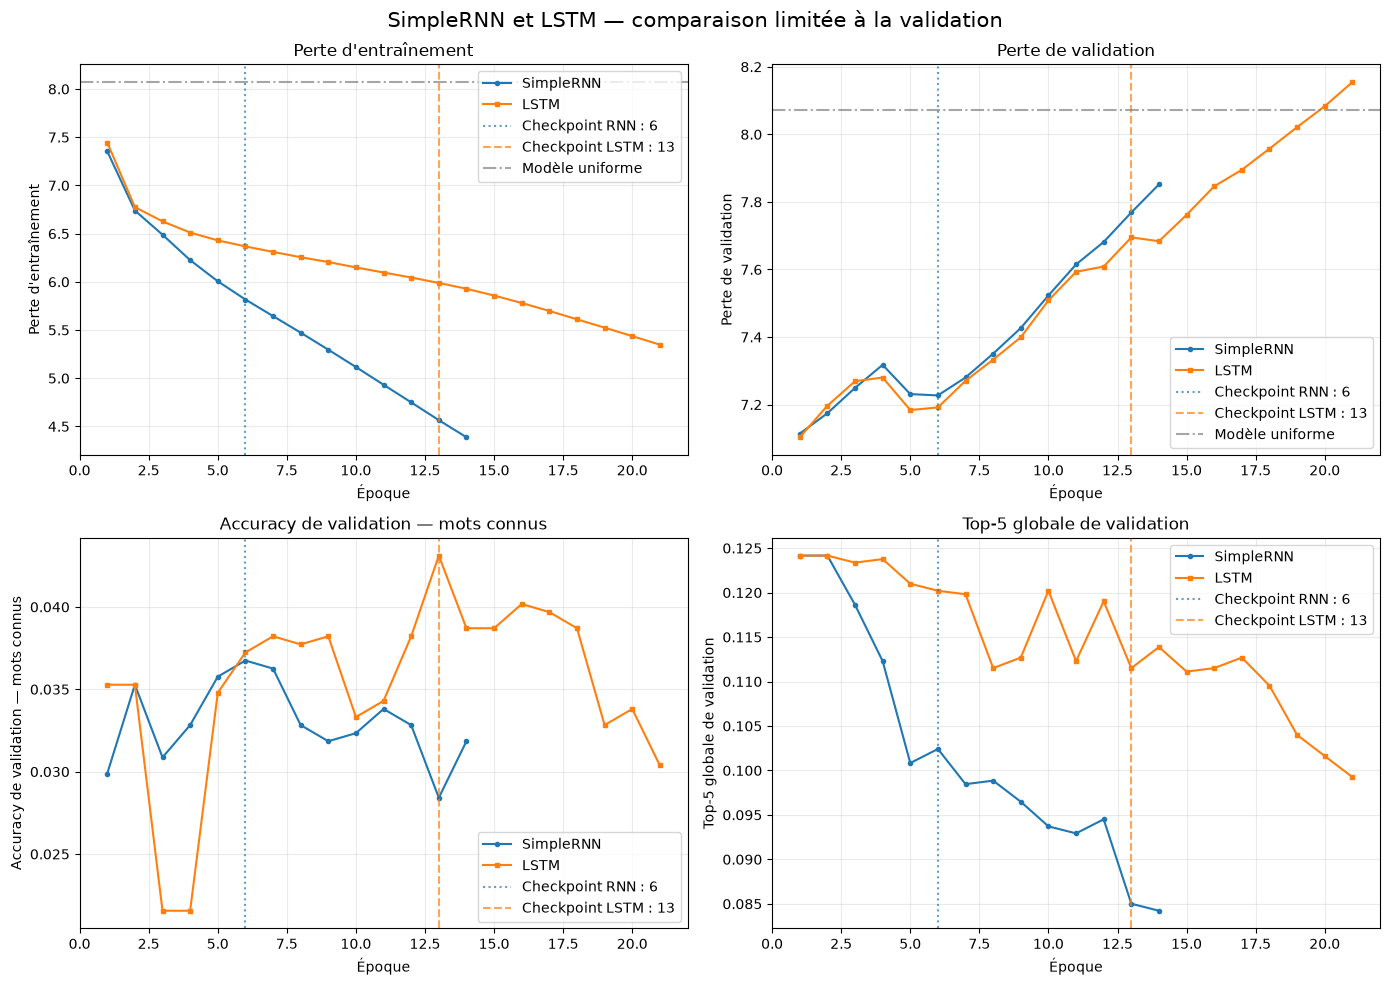

Comparaison des checkpoints — validation uniquement :
Mesure                                SimpleRNN         LSTM
Paramètres                              421,443      446,211
Époques exécutées                            14           21
Époque du checkpoint                          6           13
Corrects parmi 2 041 connus                  75           88
Accuracy mots connus                     3.67%       4.31%
Top-5 mots connus                       12.69%      13.82%
Perte mots connus                        6.2977       6.4059
Perte cibles [UNK]                      11.1147      13.0862
Perte globale                            7.2272       7.6950

Écart d'accuracy connue LSTM - RNN : +0.637 point(s)
Écart de prédictions correctes      : +13
Signal de surapprentissage RNN/LSTM : oui / oui
Conclusion descriptive              : LSTM meilleur sur ce découpage de validation
Checkpoint LSTM local              : 5.13 Mio
État Adam restauré par le fichier  : oui
Nouvelle passe sur le test

In [35]:
courbes_lstm = historique_lstm.history

cles_attendues_lstm = {
    "loss",
    "val_loss",
    "accuracy_globale_ids",
    "val_accuracy_globale_ids",
    "top_5_accuracy_globale_ids",
    "val_top_5_accuracy_globale_ids",
    "accuracy_mots_connus",
    "val_accuracy_mots_connus",
}
cles_absentes_lstm = cles_attendues_lstm.difference(
    courbes_lstm
)
assert not cles_absentes_lstm, (
    f"Courbes LSTM absentes : {cles_absentes_lstm}"
)

assert len(courbes_lstm["loss"]) == nombre_epoques_lstm
for nom, valeurs in courbes_lstm.items():
    assert len(valeurs) == nombre_epoques_lstm
    assert np.all(np.isfinite(valeurs)), (
        f"Valeur non finie dans {nom}"
    )

for nom in cles_attendues_lstm:
    if "accuracy" in nom:
        valeurs = np.asarray(courbes_lstm[nom])
        assert np.all((0.0 <= valeurs) & (valeurs <= 1.0))

np.testing.assert_allclose(
    courbes_lstm["accuracy_globale_ids"],
    courbes_lstm["accuracy_mots_connus"],
    atol=1e-7,
)
assert np.all(
    np.asarray(courbes_lstm["top_5_accuracy_globale_ids"])
    >= np.asarray(courbes_lstm["accuracy_globale_ids"]) - 1e-7
)
assert np.all(
    np.asarray(courbes_lstm["val_top_5_accuracy_globale_ids"])
    >= np.asarray(courbes_lstm["val_accuracy_globale_ids"]) - 1e-7
)

valeurs_moniteur_lstm = np.asarray(
    courbes_lstm[MONITEUR_LSTM]
)
indice_meilleure_epoque_lstm = int(
    np.argmax(valeurs_moniteur_lstm)
)
meilleure_epoque_lstm = indice_meilleure_epoque_lstm + 1
meilleure_valeur_moniteur_lstm = float(
    valeurs_moniteur_lstm[indice_meilleure_epoque_lstm]
)
indice_min_val_loss_lstm = int(
    np.argmin(courbes_lstm["val_loss"])
)
epoque_min_val_loss_lstm = indice_min_val_loss_lstm + 1

if nombre_epoques_lstm < EPOQUES_MAX_LSTM:
    assert nombre_epoques_lstm == (
        meilleure_epoque_lstm + PATIENCE_LSTM
    )

assert CHEMIN_MEILLEURS_POIDS_LSTM.is_file()
assert CHEMIN_MEILLEURS_POIDS_LSTM.stat().st_size > 0
assert np.isclose(
    float(sauvegarde_meilleurs_poids_lstm.best),
    meilleure_valeur_moniteur_lstm,
)
assert np.isclose(
    float(arret_anticipe_lstm.best),
    meilleure_valeur_moniteur_lstm,
)

# EarlyStopping a restauré les meilleurs poids en mémoire.
poids_lstm_restaures_en_memoire = [
    poids.numpy().copy() for poids in modele_lstm.weights
]

# Le rechargement explicite prouve que le fichier est exploitable.
modele_lstm.load_weights(
    str(CHEMIN_MEILLEURS_POIDS_LSTM)
)

for poids_memoire, poids_fichier in zip(
    poids_lstm_restaures_en_memoire,
    modele_lstm.weights,
):
    np.testing.assert_array_equal(
        poids_memoire,
        poids_fichier.numpy(),
    )

iterations_adam_checkpoint_lstm = int(
    modele_lstm.optimizer.iterations.numpy()
)
iterations_attendues_checkpoint_lstm = (
    meilleure_epoque_lstm * NOMBRE_LOTS_ENTRAINEMENT
)
etat_adam_checkpoint_restaure_lstm = (
    iterations_adam_checkpoint_lstm
    == iterations_attendues_checkpoint_lstm
)
assert iterations_adam_checkpoint_lstm in {
    iterations_attendues_checkpoint_lstm,
    iterations_lstm_apres_fit,
}

poids_lstm_avant_evaluation_validation = [
    poids.numpy().copy() for poids in modele_lstm.weights
]
etat_adam_lstm_avant_evaluation_validation = [
    variable.numpy().copy()
    for variable in modele_lstm.optimizer.variables
]

mesures_validation_lstm = modele_lstm.evaluate(
    dataset_validation_lstm,
    verbose=0,
    return_dict=True,
)

assert np.isclose(
    mesures_validation_lstm["accuracy_mots_connus"],
    meilleure_valeur_moniteur_lstm,
    atol=1e-7,
)

logits_validation_lstm_complets = modele_lstm.predict(
    X_validation,
    batch_size=TAILLE_LOT,
    verbose=0,
)
pertes_validation_lstm_detaillees = (
    tf.nn.sparse_softmax_cross_entropy_with_logits(
        labels=y_validation,
        logits=logits_validation_lstm_complets,
    ).numpy()
)
ids_top5_lstm = tf.math.top_k(
    logits_validation_lstm_complets,
    k=5,
).indices.numpy()
predictions_top1_lstm = ids_top5_lstm[:, 0]
presence_cible_top5_lstm = np.any(
    ids_top5_lstm == y_validation[:, None],
    axis=1,
)

assert logits_validation_lstm_complets.shape == (
    len(y_validation),
    taille_vocabulaire,
)
assert np.all(np.isfinite(
    logits_validation_lstm_complets
))
assert np.array_equal(
    masque_cible_connue,
    y_validation >= 2,
)
assert int(np.sum(masque_cible_connue)) == 2041

accuracy_connus_lstm_validation = float(np.mean(
    predictions_top1_lstm[masque_cible_connue]
    == y_validation[masque_cible_connue]
))
accuracy_globale_lstm_validation = float(np.mean(
    predictions_top1_lstm == y_validation
))
accuracy_top5_connus_lstm = float(np.mean(
    presence_cible_top5_lstm[masque_cible_connue]
))
perte_connus_lstm_validation = float(np.mean(
    pertes_validation_lstm_detaillees[masque_cible_connue]
))
perte_inconnus_lstm_validation = float(np.mean(
    pertes_validation_lstm_detaillees[
        masque_cible_inconnue
    ]
))
perte_globale_lstm_validation = float(np.mean(
    pertes_validation_lstm_detaillees
))

nombre_corrects_connus_rnn = int(np.sum(
    predictions_top1[masque_cible_connue]
    == y_validation[masque_cible_connue]
))
nombre_corrects_connus_lstm = int(np.sum(
    predictions_top1_lstm[masque_cible_connue]
    == y_validation[masque_cible_connue]
))
delta_corrects_connus = (
    nombre_corrects_connus_lstm
    - nombre_corrects_connus_rnn
)
delta_accuracy_connus_points = 100 * (
    accuracy_connus_lstm_validation
    - accuracy_connus_audit
)

np.testing.assert_allclose(
    accuracy_connus_lstm_validation,
    meilleure_valeur_moniteur_lstm,
    atol=1e-7,
)
np.testing.assert_allclose(
    accuracy_globale_lstm_validation,
    mesures_validation_lstm["accuracy_globale_ids"],
    atol=1e-7,
)
np.testing.assert_allclose(
    perte_globale_lstm_validation,
    mesures_validation_lstm["loss"],
    rtol=1e-6,
)
assert accuracy_top5_connus_lstm >= (
    accuracy_connus_lstm_validation
)
np.testing.assert_allclose(
    float(np.mean(
        predictions_top1[masque_cible_connue]
        == y_validation[masque_cible_connue]
    )),
    accuracy_connus_audit,
    atol=1e-7,
)
np.testing.assert_allclose(
    float(np.mean(
        presence_cible_top5[masque_cible_connue]
    )),
    accuracy_top5_connus,
    atol=1e-7,
)

signal_surapprentissage_lstm = (
    indice_min_val_loss_lstm < nombre_epoques_lstm - 1
    and courbes_lstm["loss"][-1]
    < courbes_lstm["loss"][indice_min_val_loss_lstm]
    and courbes_lstm["val_loss"][-1]
    > courbes_lstm["val_loss"][indice_min_val_loss_lstm]
)

# Les évaluations de validation ne doivent rien apprendre.
for avant, apres in zip(
    poids_lstm_avant_evaluation_validation,
    modele_lstm.weights,
):
    np.testing.assert_array_equal(avant, apres.numpy())
for avant, apres in zip(
    etat_adam_lstm_avant_evaluation_validation,
    modele_lstm.optimizer.variables,
):
    np.testing.assert_array_equal(avant, apres.numpy())
assert int(modele_lstm.optimizer.iterations.numpy()) == (
    iterations_adam_checkpoint_lstm
)

# Vérifications finales d'isolement du SimpleRNN et du test.
for avant, apres in zip(
    poids_rnn_avant_entrainement_lstm,
    modele_rnn.weights,
):
    np.testing.assert_array_equal(avant, apres.numpy())
for avant, apres in zip(
    etat_adam_rnn_avant_entrainement_lstm,
    modele_rnn.optimizer.variables,
):
    np.testing.assert_array_equal(avant, apres.numpy())
assert int(modele_rnn.optimizer.iterations.numpy()) == (
    iterations_rnn_avant_entrainement_lstm
)
assert hashlib.sha256(
    CHEMIN_MEILLEURS_POIDS.read_bytes()
).hexdigest() == (
    empreinte_checkpoint_rnn_avant_entrainement_lstm
)
assert tuple(vectoriseur.get_vocabulary()) == (
    vocabulaire_avant_entrainement_lstm
)
assert (
    _nombre_passes_inference_test
    == nombre_passes_test_avant_lstm
    == 1
)
assert "logits_test_lstm" not in globals()

epoques_rnn_comparaison = np.arange(
    1,
    len(courbes["loss"]) + 1,
)
epoques_lstm_comparaison = np.arange(
    1,
    nombre_epoques_lstm + 1,
)

figure_comparaison, axes_comparaison = plt.subplots(
    2,
    2,
    figsize=(14, 10),
)

graphiques_comparaison = [
    (
        "loss",
        "loss",
        "Perte d'entraînement",
    ),
    (
        "val_loss",
        "val_loss",
        "Perte de validation",
    ),
    (
        "val_accuracy_mots_connus",
        "val_accuracy_mots_connus",
        "Accuracy de validation — mots connus",
    ),
    (
        "val_top_5_accuracy_globale_ids",
        "val_top_5_accuracy_globale_ids",
        "Top-5 globale de validation",
    ),
]

for axe, (
    cle_rnn,
    cle_lstm,
    titre,
) in zip(
    axes_comparaison.flat,
    graphiques_comparaison,
):
    axe.plot(
        epoques_rnn_comparaison,
        courbes[cle_rnn],
        marker="o",
        markersize=3,
        label="SimpleRNN",
        color="tab:blue",
    )
    axe.plot(
        epoques_lstm_comparaison,
        courbes_lstm[cle_lstm],
        marker="s",
        markersize=3,
        label="LSTM",
        color="tab:orange",
    )
    axe.axvline(
        meilleure_epoque,
        color="tab:blue",
        linestyle=":",
        alpha=0.7,
        label=f"Checkpoint RNN : {meilleure_epoque}",
    )
    axe.axvline(
        meilleure_epoque_lstm,
        color="tab:orange",
        linestyle="--",
        alpha=0.7,
        label=(
            "Checkpoint LSTM : "
            f"{meilleure_epoque_lstm}"
        ),
    )
    if cle_rnn in {"loss", "val_loss"}:
        axe.axhline(
            np.log(taille_vocabulaire),
            color="gray",
            linestyle="-.",
            alpha=0.7,
            label="Modèle uniforme",
        )
    axe.set_title(titre)
    axe.set_xlabel("Époque")
    axe.set_ylabel(titre)
    axe.grid(alpha=0.25)
    axe.legend()

figure_comparaison.suptitle(
    "SimpleRNN et LSTM — comparaison limitée à la validation",
    fontsize=15,
)
figure_comparaison.tight_layout()
plt.show()

if delta_corrects_connus > 0:
    conclusion_validation = (
        "LSTM meilleur sur ce découpage de validation"
    )
elif delta_corrects_connus < 0:
    conclusion_validation = (
        "SimpleRNN meilleur sur ce découpage de validation"
    )
else:
    conclusion_validation = (
        "égalité sur ce découpage de validation"
    )

print("Comparaison des checkpoints — validation uniquement :")
print(
    f"{'Mesure':<34} {'SimpleRNN':>12} {'LSTM':>12}"
)
print(
    f"{'Paramètres':<34} "
    f"{modele_rnn.count_params():>12,d} "
    f"{modele_lstm.count_params():>12,d}"
)
print(
    f"{'Époques exécutées':<34} "
    f"{len(courbes['loss']):>12} "
    f"{nombre_epoques_lstm:>12}"
)
print(
    f"{'Époque du checkpoint':<34} "
    f"{meilleure_epoque:>12} "
    f"{meilleure_epoque_lstm:>12}"
)
print(
    f"{'Corrects parmi 2 041 connus':<34} "
    f"{nombre_corrects_connus_rnn:>12} "
    f"{nombre_corrects_connus_lstm:>12}"
)
print(
    f"{'Accuracy mots connus':<34} "
    f"{accuracy_connus_audit:>11.2%} "
    f"{accuracy_connus_lstm_validation:>11.2%}"
)
print(
    f"{'Top-5 mots connus':<34} "
    f"{accuracy_top5_connus:>11.2%} "
    f"{accuracy_top5_connus_lstm:>11.2%}"
)
print(
    f"{'Perte mots connus':<34} "
    f"{perte_connus_audit:>12.4f} "
    f"{perte_connus_lstm_validation:>12.4f}"
)
print(
    f"{'Perte cibles [UNK]':<34} "
    f"{perte_inconnus_audit:>12.4f} "
    f"{perte_inconnus_lstm_validation:>12.4f}"
)
print(
    f"{'Perte globale':<34} "
    f"{float(mesures_validation['loss']):>12.4f} "
    f"{perte_globale_lstm_validation:>12.4f}"
)
print()
print(
    "Écart d'accuracy connue LSTM - RNN :",
    f"{delta_accuracy_connus_points:+.3f} point(s)",
)
print(
    "Écart de prédictions correctes      :",
    f"{delta_corrects_connus:+d}",
)
print(
    "Signal de surapprentissage RNN/LSTM :",
    (
        "oui" if signal_surapprentissage
        else "non concluant"
    ),
    "/",
    (
        "oui" if signal_surapprentissage_lstm
        else "non concluant"
    ),
)
print("Conclusion descriptive              :", conclusion_validation)
print(
    "Checkpoint LSTM local              :",
    f"{CHEMIN_MEILLEURS_POIDS_LSTM.stat().st_size / 1024**2:.2f} Mio",
)
print(
    "État Adam restauré par le fichier  :",
    "oui" if etat_adam_checkpoint_restaure_lstm else "non",
)
print("Nouvelle passe sur le test          : non")

## Bilan de l'étape 11 — entraînement et comparaison de validation

L'arrêt anticipé a interrompu le LSTM après **21 époques sur 40**. Son meilleur checkpoint selon le critère préenregistré val_accuracy_mots_connus se situe à l'**époque 13**. Les poids de cette époque ont été restaurés en mémoire puis rechargés avec succès depuis le checkpoint local.

### Résultat selon la métrique principale

Sur les 2 041 cibles connues de validation :

- le SimpleRNN trouve 75 mots, soit **3,67 %** ;
- le LSTM trouve 88 mots, soit **4,31 %** ;
- le LSTM gagne donc **13 prédictions correctes** et **0,637 point de pourcentage**.

La top-5 accuracy sur les mots connus passe également de **12,69 %** à **13,82 %**, soit un gain descriptif de 1,13 point. Selon le critère défini avant l'entraînement, le LSTM est donc le meilleur modèle **sur ce découpage de validation**.

### Pourquoi la perte raconte une histoire différente

Le gain d'accuracy ne s'accompagne pas d'une meilleure entropie croisée :

| Mesure au checkpoint | SimpleRNN | LSTM |
|---|---:|---:|
| Perte sur les mots connus | 6,2977 | 6,4059 |
| Perte sur les cibles [UNK] | 11,1147 | 13,0862 |
| Perte globale | 7,2272 | 7,6950 |

L'accuracy observe seulement si le plus grand logit correspond au vrai mot. La perte utilise toute la distribution de probabilités et pénalise fortement une probabilité très faible attribuée à la vraie cible :

$$
\ell_i=-\log p_{i,y_i}.
$$

Le LSTM place donc le bon mot en première position pour 13 fenêtres supplémentaires, mais la log-probabilité moyenne des vraies cibles — donc leur probabilité moyenne géométrique — est plus faible. Il est meilleur selon le top-1 préenregistré, mais pas selon la qualité probabiliste mesurée par l'entropie croisée. Les deux constats sont compatibles.

### Surapprentissage observé

Pour le LSTM, la perte d'entraînement descend de 7,4445 à 5,3481 entre les époques 1 et 21, tandis que la perte de validation est minimale dès l'époque 1 avec 7,1034 puis monte jusqu'à 8,1547. L'accuracy connue de validation atteint son maximum à l'époque 13, puis ne l'améliore plus pendant huit époques. L'arrêt anticipé fonctionne donc comme prévu.

Les deux modèles présentent un signal de surapprentissage. Le SimpleRNN mémorise davantage l'entraînement, tandis que le LSTM atteint ici une accuracy de validation légèrement supérieure sans améliorer la perte.

### Conclusion honnête

Cette expérience ne démontre pas que le LSTM est généralement supérieur :

- il possède 24 768 paramètres de plus, soit 5,88 % ;
- la validation ne contient que sept poèmes ;
- les fenêtres qui se chevauchent ne sont pas indépendantes ;
- les deux modèles ont été sélectionnés sur cette même validation ;
- une seule graine et une seule initialisation ont été étudiées ;
- le contexte de trois mots exploite peu la mémoire longue du LSTM.

La conclusion défendable est donc : **le LSTM obtient la meilleure accuracy sur les mots connus pour ce découpage, avec un gain faible de 13 fenêtres, mais une entropie croisée moins bonne**.

Aucune nouvelle inférence sur le test n'a été effectuée. Le SimpleRNN, son optimiseur, son checkpoint et le vocabulaire sont restés inchangés.